# Spotify: estimar la popularidad de una canción
## Unidad 2 · Regresión y clasificación

Este cuaderno reúne el objetivo, la preparación y la comparación de una referencia de mediana y cuatro modelos: regresión lineal, árbol sencillo, KNN y HistGradientBoosting. Además, se compara cada modelo con y sin una variable de artista calculada con exclusión de la propia clave. El código se agrupa por tarea y cada bloque explica sus instrucciones y resultados. El bloque 9 inicia la clasificación binaria con popularidad >=60, usando únicamente entrenamiento.

**Archivos necesarios:** `Spotify_Unidad_2.ipynb` y `Spotify_Base_Unidad_2.csv` en la misma carpeta de trabajo. Ejecutar de arriba hacia abajo. Se utilizan Pandas, Matplotlib y scikit-learn; la versión de modelos verificada es 1.6.1. Si falta, puede instalarse en una celda auxiliar con `%pip install scikit-learn==1.6.1`.

### Recorrido

1. [Objetivo y KPI](#bloque-1)
2. [Carga y controles de entrada](#bloque-2)
3. [Separación entre entrenamiento y prueba](#bloque-3)
4. [Validación agrupada y referencia de mediana](#bloque-4)
5. [Preparación común de los modelos](#bloque-5)
6. [Regresión lineal](#bloque-6)
7. [Árbol sencillo, KNN y HistGradientBoosting](#bloque-7)
8. [Comparación, KPI y conclusiones de regresión](#bloque-8)
9. [Clasificación: objetivo, validación, KPI y evaluación final](#bloque-9)

La comparación de candidatos utiliza solo validación dentro de entrenamiento. La prueba interna se utiliza al final del bloque 8, después de fijar el procedimiento mediante validación. Las tablas de entrada y la unidad 1 no se modifican.

**Orden de evaluación:** los bloques iniciales y la primera parte del bloque 8 documentan el desarrollo sin evaluar test. Al final del bloque 8 se realiza y reporta la evaluación final del procedimiento fijado; los estados «pendiente» anteriores corresponden a esa etapa previa.


**Clasificación:** el bloque 9 conserva las particiones de entrenamiento y no consulta test para crear etiquetas, revisar clases ni fijar metas. La evaluación de regresión anterior se mantiene como evidencia de una tarea distinta.


**Evaluación de clasificación:** el bloque 9 desarrolla las decisiones usando solo entrenamiento y finaliza con la evaluación del procedimiento fijado en test. Las indicaciones anteriores de «sin usar test» describen las etapas de desarrollo, no sustituyen este reporte final.


<a id="bloque-1"></a>
## 1. Objetivo y KPI

**Objetivo:** estimar el puntaje de popularidad registrado, de 0 a 100, a partir de características musicales, categorías y géneros, comparar el aporte de información del artista disponible dentro del entrenamiento y comprobar si mejora una referencia sencilla. Buscamos un número, por eso comenzamos con regresión.

La referencia predice siempre la mediana aprendida en ajuste. La métrica principal es **MAE**, el promedio de los errores absolutos en puntos de popularidad: menor es mejor. No es porcentaje de aciertos ni un límite para todos los errores individuales.

**Mejora relativa:** `(MAE referencia − MAE modelo) / MAE referencia × 100`. Si la referencia fuera perfecta, no se calcularía esa división por cero.

| KPI | Meta | Alcance |
|---|---|---|
| IDs compartidos entre entrenamiento y prueba | 0 | Separación de observaciones |
| Claves artista + título compartidas | 0 | Mantener juntas versiones identificadas |
| Cobertura de la partición | 100% de IDs preparados | Sin pérdidas ni duplicaciones al separar |
| Mejora relativa de MAE frente a la mediana | Al menos 10% | Meta inicial de trabajo, no una garantía comercial ni una exigencia de rúbrica confirmada |

**Límite del objetivo:** describimos popularidad registrada; anticipar éxito futuro requeriría fechas e información disponible antes de predecir. RMSE y R² complementan la evaluación del bloque 8, sin sustituir el MAE como criterio principal ni añadir metas retrospectivas.

**Prueba interna:** el dataset completo ya se exploró en la unidad 1. Separarlo ahora no borra ese conocimiento; la evaluación no será una prueba externa completamente ciega. Una muestra nueva o temporalmente posterior aportaría evidencia más independiente.

<a id="bloque-2"></a>
## 2. Carga y controles de entrada

`Spotify_Base_Unidad_2.csv` es la base preparada de unidad 1, no el archivo original renombrado. Reúne una fila por ID, 114 géneros Multi-Hot y una clave auxiliar de partición.

**Lectura del código:**

- `import pandas as pd` incorpora la herramienta de tablas. `display` permite mostrar varios resultados dentro de una misma celda.
- `read_csv` lee el archivo local. `dtype` preserva ID y clave como texto y compás como entero con ausencias (`Int64`). `set_index` coloca el ID en el índice.
- `shape` informa filas y columnas: **89.740 × 130**, sin contar el ID del índice. No todas las columnas serán predictoras.
- `is_unique` comprueba IDs distintos; `notna` comprueba presencia y `str.strip().ne("")` rechaza claves vacías.
- `if not ...all()` detiene la ejecución si falla un requisito, en vez de continuar con una separación inválida.

La popularidad de 720 IDs discrepantes conserva el resumen por mediana de registros. Tempo y compás mantienen ausencias, y el compás 1 y la sonoridad positiva conservan sus limitaciones. No se reutilizan las escalas demo de unidad 1.

In [1]:
from IPython.display import display

# Leer la base preparada

import pandas as pd
archivo_base = "Spotify_Base_Unidad_2.csv"
base_unidad2 = pd.read_csv(archivo_base, dtype={"track_id": "string", "clave_cancion": "string", "time_signature": "Int64"})
base_unidad2 = base_unidad2.set_index("track_id")
display(base_unidad2.shape)

# Comprobar identidad y clave

requisitos_particion = pd.Series({
    "ID único": base_unidad2.index.is_unique,
    "ID sin faltantes": base_unidad2.index.notna().all(),
    "Clave sin faltantes": base_unidad2["clave_cancion"].notna().all(),
    "Clave sin texto vacío": base_unidad2["clave_cancion"].str.strip().ne("").all()
})
display(requisitos_particion)

# Detener ante requisitos incumplidos

if not requisitos_particion.all():
    raise ValueError("Revisar IDs y claves antes de realizar la partición.")

(89740, 130)

ID único                 True
ID sin faltantes         True
Clave sin faltantes      True
Clave sin texto vacío    True
dtype: bool

<a id="bloque-3"></a>
## 3. Separación entre entrenamiento y prueba

La clave reúne artista y título normalizados: minúsculas y espacios externos o repetidos corregidos. Así se mantienen juntas las versiones con igual clave. No reconoce todas las reediciones, títulos distintos ni cambios de orden de colaboradores; tampoco separa artistas completos.

**Asignación:** `drop_duplicates` obtiene claves distintas; `sort_values` fija su orden; `sample(frac=0.80, random_state=42)` selecciona aproximadamente 80% de grupos. La semilla reproduce la selección con la misma base; no mejora el resultado. `isin` marca sus filas y `.loc` crea las copias. `~` invierte la máscara para obtener prueba.

**Controles:** `intersection` detecta IDs compartidos, `set(...).intersection(...)` detecta claves compartidas y `union` comprueba cobertura. `len` cuenta IDs y `nunique` grupos. El resultado es **71.728 IDs de entrenamiento (79,93%) y 18.012 de prueba (20,07%)**, con cero solapamientos y cobertura del 100%. Los porcentajes por ID no son exactos porque los grupos tienen tamaños distintos.

In [2]:
# Separar grupos sin usar popularidad

claves_unicas = base_unidad2["clave_cancion"].drop_duplicates().sort_values().reset_index(drop=True)
claves_entrenamiento = claves_unicas.sample(frac=0.80, random_state=42)
es_entrenamiento = base_unidad2["clave_cancion"].isin(claves_entrenamiento)
datos_entrenamiento = base_unidad2.loc[es_entrenamiento].copy()
datos_prueba = base_unidad2.loc[~es_entrenamiento].copy()

# Describir tamaño de las partes

resumen_particion = pd.DataFrame({"IDs": [len(datos_entrenamiento), len(datos_prueba)], "Claves distintas": [datos_entrenamiento["clave_cancion"].nunique(), datos_prueba["clave_cancion"].nunique()]}, index=["Entrenamiento", "Prueba interna"])
resumen_particion["Porcentaje de IDs"] = resumen_particion["IDs"] / len(base_unidad2) * 100
display(resumen_particion.round(3))

# Comprobar intersección y cobertura

ids_compartidos = datos_entrenamiento.index.intersection(datos_prueba.index)
claves_compartidas = set(datos_entrenamiento["clave_cancion"]).intersection(set(datos_prueba["clave_cancion"]))
ids_asignados = datos_entrenamiento.index.union(datos_prueba.index)
comprobaciones_particion = pd.Series({
    "IDs compartidos": len(ids_compartidos),
    "Claves compartidas": len(claves_compartidas),
    "Cobertura de IDs (%)": len(ids_asignados) / len(base_unidad2) * 100,
    "IDs únicos en cada conjunto": datos_entrenamiento.index.is_unique and datos_prueba.index.is_unique,
    "Todos los IDs asignados sin adiciones": set(ids_asignados) == set(base_unidad2.index),
    "Suma de filas coincide con base": len(datos_entrenamiento) + len(datos_prueba) == len(base_unidad2)
})
display(comprobaciones_particion)

,IDs,Claves distintas,Porcentaje de IDs
Entrenamiento,71728,64965,79.929
Prueba interna,18012,16241,20.071


IDs compartidos                              0
Claves compartidas                           0
Cobertura de IDs (%)                     100.0
IDs únicos en cada conjunto               True
Todos los IDs asignados sin adiciones     True
Suma de filas coincide con base           True
dtype: object

**Entradas y respuesta:** `X_train` y `X_test` conservan 127 columnas: diez medidas, tres categorías y 114 géneros. `y_train` y `y_test` son popularidad. `drop` excluye objetivo, clave y duración en milisegundos, redundante con minutos. El ID queda en el índice para alinear, no como predictor.

`columns.equals` compara nombres y orden; `index.equals` verifica alineación con y; `startswith` identifica el bloque de géneros. Estas comprobaciones no evalúan popularidad de prueba.

El manifiesto `Spotify_Particion_Unidad_2.csv` guarda ID, clave y conjunto. `to_csv` escribe un archivo con nombre distinto: no sobrescribe la base. No contiene predicciones.

In [3]:
# Separar entradas y objetivo

columnas_excluir_X = ["popularity", "clave_cancion", "duration_ms"]
X_train = datos_entrenamiento.drop(columns=columnas_excluir_X).copy()
X_test = datos_prueba.drop(columns=columnas_excluir_X).copy()
y_train = datos_entrenamiento["popularity"].copy()
y_test = datos_prueba["popularity"].copy()

# Verificar columnas y alineación

comprobaciones_X_y = pd.Series({
    "Columnas de X idénticas y en el mismo orden": X_train.columns.equals(X_test.columns),
    "127 columnas de entrada": X_train.shape[1] == 127 and X_test.shape[1] == 127,
    "114 indicadores de género": X_train.columns.str.startswith("genero__").sum() == 114,
    "Índices train alineados con y": X_train.index.equals(y_train.index),
    "Índices test alineados con y": X_test.index.equals(y_test.index),
    "Objetivo y auxiliares fuera de X": all(columna not in X_train.columns for columna in ["popularity", "track_id", "clave_cancion", "duration_ms"])
})
display(comprobaciones_X_y)

# Guardar una asignación reproducible

particion_unidad2 = base_unidad2[["clave_cancion"]].copy()
particion_unidad2["conjunto"] = "prueba_interna"
particion_unidad2.loc[es_entrenamiento, "conjunto"] = "entrenamiento"
particion_unidad2.to_csv("Spotify_Particion_Unidad_2.csv", index_label="track_id")

Columnas de X idénticas y en el mismo orden    True
127 columnas de entrada                        True
114 indicadores de género                      True
Índices train alineados con y                  True
Índices test alineados con y                   True
Objetivo y auxiliares fuera de X               True
dtype: bool

<a id="bloque-4"></a>
## 4. Validación agrupada y referencia de mediana

Solo se trabaja con los **71.728 IDs de entrenamiento**. Se crean tres pliegues y se rota la evaluación: ajustar con 2–3 y validar con 1; ajustar con 1–3 y validar con 2; ajustar con 1–2 y validar con 3. Cada clave pertenece íntegramente a un pliegue.

`sample(frac=1, random_state=42)` mezcla las claves de entrenamiento. El resto de dividir la posición por tres (`% 3`) asigna códigos 0, 1 y 2; `map` los lleva a cada ID. No es una llamada a `GroupKFold` ni una estratificación por popularidad. Los tamaños son **23.913, 24.104 y 23.711 IDs**.

`groupby(...).nunique()` comprueba un pliegue por clave; `notna`, `isin` e igualdad de índices comprueban cobertura y alineación. Si falla un control, `raise ValueError` detiene el cálculo. Las versiones de una misma clave nunca se reparten entre ajuste y validación.

In [4]:
# Construir pliegues dentro de entrenamiento

numero_pliegues = 3
claves_validacion = datos_entrenamiento["clave_cancion"].drop_duplicates().sort_values().sample(frac=1, random_state=42).reset_index(drop=True)
pliegue_por_clave = pd.Series([posicion % numero_pliegues for posicion in range(len(claves_validacion))], index=claves_validacion)
pliegue_por_id = datos_entrenamiento["clave_cancion"].map(pliegue_por_clave)
display(pliegue_por_id.value_counts().sort_index())

# Controlar cobertura y grupos

asignacion_validacion = pd.DataFrame({"clave_cancion": datos_entrenamiento["clave_cancion"], "pliegue": pliegue_por_id})
pliegues_por_grupo = asignacion_validacion.groupby("clave_cancion")["pliegue"].nunique()
controles_validacion = pd.Series({
    "Todos los IDs de entrenamiento tienen pliegue": pliegue_por_id.notna().all(),
    "Solo tres códigos de pliegue": pliegue_por_id.isin([0, 1, 2]).all(),
    "Cada clave pertenece a un único pliegue": pliegues_por_grupo.eq(1).all(),
    "Asignaciones cubren el entrenamiento": len(asignacion_validacion) == len(datos_entrenamiento),
    "Índices alineados con y_train": pliegue_por_id.index.equals(y_train.index)
})
display(controles_validacion)

# Detener si la validación está mal definida

if not controles_validacion.all():
    raise ValueError("Revisar la asignación de pliegues antes de evaluar la referencia.")

clave_cancion
0    23913
1    24104
2    23711
Name: count, dtype: int64

Todos los IDs de entrenamiento tienen pliegue    True
Solo tres códigos de pliegue                     True
Cada clave pertenece a un único pliegue          True
Asignaciones cubren el entrenamiento             True
Índices alineados con y_train                    True
dtype: bool

### MAE con un ejemplo ficticio

Una muestra de ajuste con popularidades 10, 40 y 70 tiene mediana 40. La referencia predice 40 para tres respuestas de validación: 20, 50 y 80. Sus errores absolutos son 20, 10 y 40; **MAE = 70 / 3 = 23,33 puntos**. No son resultados de Spotify.

`median` aprende la constante solo del ajuste. `pd.Series(constante, index=...)` repite la predicción en los índices de validación. La resta compara cada par, `abs` evita cancelación por signos y `mean` promedia los tamaños de error. La tabla reúne reales, predicciones y errores para leerlos juntos.

In [5]:
# Ejemplo pequeño para leer errores individuales

y_ajuste_ejemplo = pd.Series([10, 40, 70])
y_validacion_ejemplo = pd.Series([20, 50, 80])
mediana_ejemplo = y_ajuste_ejemplo.median()
predicciones_ejemplo = pd.Series(mediana_ejemplo, index=y_validacion_ejemplo.index)
errores_ejemplo = (y_validacion_ejemplo - predicciones_ejemplo).abs()
display(pd.DataFrame({"real": y_validacion_ejemplo, "prediccion": predicciones_ejemplo, "error_absoluto": errores_ejemplo}))

# Promediar los errores absolutos del ejemplo

display(errores_ejemplo.mean())

,real,prediccion,error_absoluto
0,20,40.0,20.0
1,50,40.0,10.0
2,80,40.0,40.0


np.float64(23.333333333333332)

### Referencia real fuera de pliegue

La Serie OOF reserva una posición por ID; la lista guarda resultados por ronda. En el bucle, `eq` define validación y `~` define ajuste; `.loc` selecciona respuestas. Los conjuntos de claves deben tener intersección vacía.

`y_ajuste.median()` aprende la predicción constante sin respuestas de validación. `pd.Series` la repite para los IDs evaluados; resta, `abs` y `mean` calculan el MAE. La asignación `.loc[...]` guarda cada predicción en su ID; `append` registra tamaños, mediana y error. La mediana minimiza error absoluto entre constantes en ajuste, no garantiza el menor error futuro.

Los controles OOF exigen una predicción por ID. El MAE global promedia todos los errores, dando el mismo peso a cada canción. La media simple de rondas da igual peso a cada ronda y puede diferir ligeramente cuando los tamaños no coinciden; el promedio ponderado por IDs coincide con el global.

**Resultados:** medianas **33, 34 y 33**; MAE por ronda **17,363; 17,366; 17,024**; MAE global **17,252** y desviación entre rondas **0,160**. La desviación no es un margen de error por canción ni un intervalo de confianza.

El objetivo de mejorar un 10% equivale en esta validación a `0.90 × MAE referencia`, aproximadamente **15,527 puntos**. No se usa ese número como si fuera el error de referencia en prueba. El manifiesto adicional conserva solo IDs de entrenamiento, clave y pliegue.

In [6]:
# Preparar resultados fuera de pliegue

predicciones_mediana_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_mediana_oof")
resultados_mediana = []

# Aprender y evaluar una mediana por ronda

for pliegue in range(numero_pliegues):
    es_validacion = pliegue_por_id.eq(pliegue)
    y_ajuste = y_train.loc[~es_validacion]
    y_validacion = y_train.loc[es_validacion]
    claves_ajuste = set(datos_entrenamiento.loc[~es_validacion, "clave_cancion"])
    claves_evaluadas = set(datos_entrenamiento.loc[es_validacion, "clave_cancion"])
    if claves_ajuste.intersection(claves_evaluadas):
        raise ValueError("Hay claves compartidas entre ajuste y validación.")
    mediana_ajuste = y_ajuste.median()
    prediccion_pliegue = pd.Series(mediana_ajuste, index=y_validacion.index)
    errores_pliegue = (y_validacion - prediccion_pliegue).abs()
    mae_pliegue = errores_pliegue.mean()
    predicciones_mediana_oof.loc[y_validacion.index] = prediccion_pliegue
    resultados_mediana.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste), "IDs validación": len(y_validacion), "Mediana de ajuste": mediana_ajuste, "MAE validación": mae_pliegue, "Claves compartidas": len(claves_ajuste.intersection(claves_evaluadas))})

# Resumir las rondas

tabla_referencia_mediana = pd.DataFrame(resultados_mediana)
display(tabla_referencia_mediana.round(4))

# Verificar las predicciones OOF

controles_oof = pd.Series({
    "Todos los IDs tienen predicción OOF": predicciones_mediana_oof.notna().all(),
    "Índice OOF alineado con y_train": predicciones_mediana_oof.index.equals(y_train.index),
    "Validaciones cubren todo el entrenamiento": tabla_referencia_mediana["IDs validación"].sum() == len(y_train),
    "Ninguna ronda comparte claves": tabla_referencia_mediana["Claves compartidas"].eq(0).all()
})

# Calcular MAE global por ID

if not controles_oof.all():
    raise ValueError("Las predicciones OOF no cubren correctamente el entrenamiento.")
errores_mediana_oof = (y_train - predicciones_mediana_oof).abs()
mae_referencia_oof = errores_mediana_oof.mean()

# Distinguir promedio de rondas y promedio por IDs

mae_medio_rondas = tabla_referencia_mediana["MAE validación"].mean()
desviacion_mae_rondas = tabla_referencia_mediana["MAE validación"].std(ddof=0)
mae_ponderado_rondas = (tabla_referencia_mediana["MAE validación"] * tabla_referencia_mediana["IDs validación"]).sum() / tabla_referencia_mediana["IDs validación"].sum()
display(pd.Series({"Media de MAE por ronda": mae_medio_rondas, "Desviación entre rondas (ddof=0)": desviacion_mae_rondas, "MAE ponderado por IDs": mae_ponderado_rondas, "MAE OOF por ID": mae_referencia_oof}))

# Traducir la meta de mejora sin cambiarla

mejora_objetivo = 0.10
mae_objetivo_validacion = mae_referencia_oof * (1 - mejora_objetivo)
display(pd.Series({"MAE de referencia OOF": mae_referencia_oof, "Mejora objetivo (%)": mejora_objetivo * 100, "MAE máximo del modelo para esa meta en validación": mae_objetivo_validacion}))

# Guardar los pliegues de entrenamiento

manifiesto_validacion = asignacion_validacion.copy()
manifiesto_validacion["pliegue"] = manifiesto_validacion["pliegue"] + 1
manifiesto_validacion.to_csv("Spotify_Validacion_Entrenamiento.csv", index_label="track_id")

,Ronda,IDs ajuste,IDs validación,Mediana de ajuste,MAE validación,Claves compartidas
0,1,47815,23913,33.0,17.3627,0
1,2,47624,24104,34.0,17.3657,0
2,3,48017,23711,33.0,17.0243,0


Media de MAE por ronda              17.250883
Desviación entre rondas (ddof=0)     0.160243
MAE ponderado por IDs               17.251826
MAE OOF por ID                      17.251826
dtype: float64

MAE de referencia OOF                                17.251826
Mejora objetivo (%)                                  10.000000
MAE máximo del modelo para esa meta en validación    15.526644
dtype: float64

<a id="bloque-5"></a>
## 5. Preparación común de los modelos

La preparación se define como una plantilla y se ajusta de nuevo dentro de cada ronda. **Nunca se imputan o escalan todas las observaciones antes de validar.**

| Grupo | Tratamiento | Lectura |
|---|---|---|
| Diez medidas | Mediana de ajuste + estandarización | El tempo ausente usa una mediana aprendida solo en ajuste |
| Tres categorías | Regla fija + One-Hot | Los códigos no se interpretan como magnitudes continuas |
| 114 géneros | Multi-Hot sin escalar | Conserva varias etiquetas por ID |

**Lectura del código:**

1. Las importaciones incorporan componentes, sin ajustar nada. `clone` crea una configuración independiente, `Pipeline` encadena pasos y `ColumnTransformer` asigna grupos de columnas. `mean_absolute_error` calcula la misma métrica ya explicada.
2. Las listas seleccionan medidas, categorías y géneros por prefijo. Popularidad y auxiliares están fuera. Tonalidad (`key`) no está en esta base y no se incorpora implícitamente.
3. `preparar_categorias_lineal` crea texto con ausencias explícitas. Solo el compás 1 se agrupa como `NO_DETERMINADO`, por la limitación documentada; no cambia la base ni `mode=1`. `return` entrega una transformación auxiliar.
4. `SimpleImputer(strategy="median")` aprende una mediana por medida. `StandardScaler` aprende media y desviación sobre las medidas ya imputadas. Definirlos no ejecuta `fit`.
5. `FunctionTransformer` integra la regla fija de categorías manteniendo nombres. `OneHotEncoder` aprende niveles en ajuste. `drop="first"` omite una referencia por categoría; `handle_unknown="ignore"` evita fallar ante niveles nuevos, cuyo bloque queda en cero y puede confundirse con la referencia omitida. `sparse_output` almacena ceros eficientemente.
6. `ColumnTransformer` combina los bloques; `passthrough` conserva los géneros. El umbral de dispersión es una decisión de almacenamiento, no una meta predictiva. La última `Pipeline` añade la regresión lineal.

El escalamiento no crea relaciones nuevas; facilita unidades y condicionamiento. Para el árbol no es necesario del mismo modo, pero se conservará la misma configuración para aislar el cambio de regresor. La sonoridad positiva permanece sin nuevas exclusiones.

**Adaptación para KNN en el bloque 7:** conservará todas las categorías One-Hot (`drop=None`) para una distancia simétrica entre sus niveles. Los modelos anteriores mantienen su configuración. Se comparan procedimientos completos sobre los mismos IDs, no se exige una matriz idéntica cuando el modelo necesita otra representación.

In [7]:
# Componentes de preparación y regresión

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Seleccionar los tres bloques de variables

columnas_numericas_modelo = ["duration_min", "danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
columnas_categoricas_modelo = ["explicit", "mode", "time_signature"]
columnas_genero_modelo = X_train.columns[X_train.columns.str.startswith("genero__")].tolist()
display(pd.Series({"Medidas numéricas": len(columnas_numericas_modelo), "Categorías": len(columnas_categoricas_modelo), "Géneros Multi-Hot": len(columnas_genero_modelo)}))

# Regla fija para las categorías no determinadas

def preparar_categorias_lineal(datos):
    categorias = datos.astype("string").fillna("NO_DETERMINADO")
    categorias["time_signature"] = categorias["time_signature"].replace("1", "NO_DETERMINADO")
    return categorias.astype(object)

# Preparación numérica aprendida dentro de ajuste

preparacion_numerica_lineal = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler())
])

# Preparación categórica y One-Hot

preparacion_categorica_lineal = Pipeline([
    ("etiquetar", FunctionTransformer(preparar_categorias_lineal, validate=False, feature_names_out="one-to-one")),
    ("codificar", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=True))
])

# Combinar preparación y regresión lineal

preprocesador_lineal = ColumnTransformer([
    ("numericas", preparacion_numerica_lineal, columnas_numericas_modelo),
    ("categoricas", preparacion_categorica_lineal, columnas_categoricas_modelo),
    ("generos", "passthrough", columnas_genero_modelo)
], sparse_threshold=1.0)
modelo_lineal_base = Pipeline([
    ("preparar", preprocesador_lineal),
    ("regresion", LinearRegression())
])

Medidas numéricas     10
Categorías             3
Géneros Multi-Hot    114
dtype: int64

<a id="bloque-6"></a>
## 6. Regresión lineal

Aprende **intercepto + suma de coeficiente × característica**. Combina varias entradas y puede producir valores distintos por canción. Ajusta mínimos cuadrados, mientras MAE sigue siendo la métrica externa: no son la misma función.

**Lectura de las rondas:** se reservan predicciones OOF, resultados y modelos. El bucle usa los mismos pliegues; `.loc` separa entradas y respuestas. Se detiene si alguna medida está totalmente ausente en ajuste. `clone` crea una plantilla nueva; `fit` aprende preparación y coeficientes solo con ajuste. `predict` transforma validación sin recibir sus respuestas y `mean_absolute_error` mide el error después.

Las predicciones se guardan por ID. `named_steps` y `named_transformers_` permiten recuperar las medianas aprendidas, entre ellas tempo. `merge(..., on="Ronda", validate="one_to_one")` compara con la referencia de esa misma ronda; no mezcla particiones.

Los controles OOF verifican cobertura, índices y tamaños. Después se promedian errores absolutos de los 71.728 IDs y se calcula la mejora relativa.

**Resultado:** MAE **11,894**, reducción de **5,358 puntos** frente a la mediana y mejora relativa **31,06%**. Eso no equivale a 31,06% de canciones correctas ni demuestra un efecto causal de las características.

In [8]:
# Preparar estructuras de resultados

predicciones_lineales_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_lineal_oof")
resultados_lineales = []
modelos_lineales_por_pliegue = {}

# Ajustar y predecir dentro de cada ronda

for pliegue in range(numero_pliegues):
    es_validacion_lineal = pliegue_por_id.eq(pliegue)
    X_ajuste_lineal = X_train.loc[~es_validacion_lineal]
    X_validacion_lineal = X_train.loc[es_validacion_lineal]
    y_ajuste_lineal = y_train.loc[~es_validacion_lineal]
    y_validacion_lineal = y_train.loc[es_validacion_lineal]
    if X_ajuste_lineal[columnas_numericas_modelo].notna().sum().eq(0).any():
        raise ValueError("Una medida no tiene datos en ajuste; revisar antes de imputar.")
    modelo_lineal_pliegue = clone(modelo_lineal_base)
    modelo_lineal_pliegue.fit(X_ajuste_lineal, y_ajuste_lineal)
    prediccion_lineal = modelo_lineal_pliegue.predict(X_validacion_lineal)
    mae_lineal_pliegue = mean_absolute_error(y_validacion_lineal, prediccion_lineal)
    predicciones_lineales_oof.loc[y_validacion_lineal.index] = prediccion_lineal
    modelos_lineales_por_pliegue[pliegue] = modelo_lineal_pliegue
    numericas_ajustadas = modelo_lineal_pliegue.named_steps["preparar"].named_transformers_["numericas"]
    mediana_tempo_aprendida = numericas_ajustadas.named_steps["imputar"].statistics_[columnas_numericas_modelo.index("tempo")]
    resultados_lineales.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste_lineal), "IDs validación": len(y_validacion_lineal), "Mediana tempo de ajuste": mediana_tempo_aprendida, "MAE lineal": mae_lineal_pliegue})

# Comparar con la mediana por ronda

tabla_lineal = pd.DataFrame(resultados_lineales)
comparacion_por_ronda = tabla_lineal.merge(tabla_referencia_mediana[["Ronda", "MAE validación"]].rename(columns={"MAE validación": "MAE referencia"}), on="Ronda", validate="one_to_one")
comparacion_por_ronda["Mejora MAE (%)"] = (comparacion_por_ronda["MAE referencia"] - comparacion_por_ronda["MAE lineal"]) / comparacion_por_ronda["MAE referencia"] * 100
display(comparacion_por_ronda.round(4))

# Controlar cobertura fuera de pliegue

controles_lineal_oof = pd.Series({
    "Cada ID tiene predicción lineal OOF": predicciones_lineales_oof.notna().all(),
    "Índices alineados con y_train": predicciones_lineales_oof.index.equals(y_train.index),
    "Validaciones cubren entrenamiento": tabla_lineal["IDs validación"].sum() == len(y_train),
    "Mismos tamaños por ronda que referencia": tabla_lineal["IDs validación"].equals(tabla_referencia_mediana["IDs validación"])
})

# Calcular MAE global y mejora

if not controles_lineal_oof.all():
    raise ValueError("Revisar las predicciones OOF antes de comparar errores.")
errores_lineales_oof = (y_train - predicciones_lineales_oof).abs()
mae_lineal_oof = errores_lineales_oof.mean()
mejora_lineal_oof = (mae_referencia_oof - mae_lineal_oof) / mae_referencia_oof * 100
display(pd.Series({"MAE referencia OOF": mae_referencia_oof, "MAE lineal OOF": mae_lineal_oof, "Mejora relativa (%)": mejora_lineal_oof, "Reducción absoluta de MAE (puntos)": mae_referencia_oof - mae_lineal_oof}))

,Ronda,IDs ajuste,IDs validación,Mediana tempo de ajuste,MAE lineal,MAE referencia,Mejora MAE (%)
0,1,47815,23913,122.013,11.9504,17.3627,31.1718
1,2,47624,24104,122.068,12.1464,17.3657,30.0549
2,3,48017,23711,122.007,11.5811,17.0243,31.9729


MAE referencia OOF                    17.251826
MAE lineal OOF                        11.894220
Mejora relativa (%)                   31.055299
Reducción absoluta de MAE (puntos)     5.357606
dtype: float64

### Diagnósticos del modelo lineal

La tabla de cinco ejemplos muestra reales y predicciones alineados por ID, sin ordenar para escoger solo aciertos. `head` no es una muestra representativa; mejorar el promedio no garantiza mejorar cada canción.

`lt(0)` y `gt(100)` cuentan salidas fuera de escala: hubo **360 negativas y cero superiores a 100**. No se recortaron al calcular el MAE. Es una limitación del regresor, no motivo para eliminar datos originales.

La revisión de parámetros compara `statistics_` del imputador con medianas calculadas directamente solo en ajuste. `n_samples_seen_` del escalador debe coincidir con los IDs de ajuste de la ronda. Estos controles aportan evidencia del procedimiento, no una prueba exhaustiva contra cualquier fuga posible.

La última comparación verifica la meta del 10% **en validación**. No convierte el resultado en una evaluación final de prueba.

In [9]:
# Leer algunos errores reales de entrenamiento OOF

ejemplos_lineal_oof = pd.DataFrame({"Popularidad real resumida": y_train, "Referencia OOF": predicciones_mediana_oof, "Lineal OOF": predicciones_lineales_oof, "Error absoluto lineal": errores_lineales_oof})
display(ejemplos_lineal_oof.head(5).round(3))

# Contar salidas fuera de escala sin recortarlas

predicciones_lineales_negativas = predicciones_lineales_oof.lt(0).sum()
predicciones_lineales_sobre_100 = predicciones_lineales_oof.gt(100).sum()
display(pd.Series({"Predicciones OOF menores que 0": predicciones_lineales_negativas, "Predicciones OOF mayores que 100": predicciones_lineales_sobre_100}))

# Comprobar parámetros aprendidos en cada ajuste

revision_ajuste_lineal = []
for pliegue, modelo_guardado in modelos_lineales_por_pliegue.items():
    bloque_numerico = modelo_guardado.named_steps["preparar"].named_transformers_["numericas"]
    medianas_esperadas = X_train.loc[~pliegue_por_id.eq(pliegue), columnas_numericas_modelo].median()
    medianas_coinciden = pd.Series(bloque_numerico.named_steps["imputar"].statistics_, index=columnas_numericas_modelo).equals(medianas_esperadas)
    revision_ajuste_lineal.append({"Ronda": pliegue + 1, "Medianas coinciden con ajuste": medianas_coinciden, "Filas vistas por escalador": int(bloque_numerico.named_steps["escalar"].n_samples_seen_), "IDs esperados de ajuste": int(pliegue_por_id.ne(pliegue).sum())})
display(pd.DataFrame(revision_ajuste_lineal))

# Estado de la meta de desarrollo del modelo lineal

cumple_lineal_en_validacion = mejora_lineal_oof >= mejora_objetivo * 100

,Popularidad real resumida,Referencia OOF,Lineal OOF,Error absoluto lineal
track_id,,,,
000CC8EParg64OmTxVnZ0p,47.0,33.0,32.754,14.246
000Iz0K615UepwSJ5z2RE5,22.0,33.0,34.240,12.240
000RDCYioLteXcutOjeweY,62.0,33.0,38.243,23.757
000qpdoc97IMTBvF8gwcpy,19.0,34.0,33.353,14.353
0017XiMkqbTfF2AUOzlhj6,24.0,33.0,24.363,0.363


Predicciones OOF menores que 0      360
Predicciones OOF mayores que 100      0
dtype: int64

,Ronda,Medianas coinciden con ajuste,Filas vistas por escalador,IDs esperados de ajuste
0,1,True,47815,47815
1,2,True,47624,47624
2,3,True,48017,48017


<a id="bloque-7"></a>
## 7. Árbol sencillo, KNN y HistGradientBoosting

### Árbol de decisión

Un árbol divide canciones mediante preguntas y predice una constante por hoja. Con `criterion="squared_error"`, esa constante es la **media de respuestas de ajuste que llegan a la hoja**, no una mediana ni una respuesta de validación.

| Configuración fijada previamente | Significado |
|---|---|
| `max_depth=4` | Hasta cuatro divisiones por ruta; raíz en profundidad cero |
| `min_samples_leaf=50` | Al menos 50 IDs de ajuste por hoja |
| `criterion="squared_error"` | Aprender divisiones reduciendo error cuadrático |
| `random_state=42` | Reproducir elecciones internas |

Como máximo puede formar 16 hojas, aunque creó **14, 13 y 12** según la ronda. Son características de estructura, no puntuaciones de calidad. No se buscó otra profundidad para presentar solo una configuración ganadora.

**Lectura del código:** el árbol se incorpora a una `Pipeline` con copia sin ajustar de la preparación común. Las estructuras OOF se crean con el índice de entrenamiento. Cada ronda reutiliza su máscara, clona, ajusta y predice. Se calcula MAE de validación y, aparte, MAE del propio ajuste como diagnóstico. `get_depth` y `get_n_leaves` consultan la estructura.

`merge` agrega los MAE anteriores por ronda; los controles verifican cobertura y límites estructurales. El MAE global vuelve a dar un peso igual a cada ID. La resta **MAE árbol − MAE lineal** es positiva si el árbol se equivoca más.

**Resultado:** MAE **16,210**, mejora **6,04%** frente a la mediana, pero **4,316 puntos más de error que la regresión lineal**. No alcanza la meta del 10%. Un modelo no lineal no tiene garantizado superar a uno lineal; un árbol pequeño también puede representar pocas diferencias.

In [10]:
# Plantilla del árbol con configuración fija

from sklearn.tree import DecisionTreeRegressor, export_text
modelo_arbol_base = Pipeline([
    ("preparar", clone(preprocesador_lineal)),
    ("regresion", DecisionTreeRegressor(max_depth=4, min_samples_leaf=50, criterion="squared_error", random_state=42))
])

# Preparar resultados OOF

predicciones_arbol_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_arbol_oof")
resultados_arbol = []
modelos_arbol_por_pliegue = {}

# Aprender y evaluar con los mismos pliegues

for pliegue in range(numero_pliegues):
    es_validacion_arbol = pliegue_por_id.eq(pliegue)
    X_ajuste_arbol = X_train.loc[~es_validacion_arbol]
    X_validacion_arbol = X_train.loc[es_validacion_arbol]
    y_ajuste_arbol = y_train.loc[~es_validacion_arbol]
    y_validacion_arbol = y_train.loc[es_validacion_arbol]
    modelo_arbol_pliegue = clone(modelo_arbol_base)
    modelo_arbol_pliegue.fit(X_ajuste_arbol, y_ajuste_arbol)
    prediccion_arbol = modelo_arbol_pliegue.predict(X_validacion_arbol)
    mae_arbol_pliegue = mean_absolute_error(y_validacion_arbol, prediccion_arbol)
    predicciones_arbol_oof.loc[y_validacion_arbol.index] = prediccion_arbol
    modelos_arbol_por_pliegue[pliegue] = modelo_arbol_pliegue
    arbol_ajustado = modelo_arbol_pliegue.named_steps["regresion"]
    mae_ajuste_arbol = mean_absolute_error(y_ajuste_arbol, modelo_arbol_pliegue.predict(X_ajuste_arbol))
    resultados_arbol.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste_arbol), "IDs validación": len(y_validacion_arbol), "MAE ajuste árbol": mae_ajuste_arbol, "MAE árbol": mae_arbol_pliegue, "Profundidad efectiva": arbol_ajustado.get_depth(), "Hojas": arbol_ajustado.get_n_leaves()})

# Comparar por ronda y registrar estructura

tabla_arbol = pd.DataFrame(resultados_arbol)
comparacion_arbol_por_ronda = tabla_arbol.merge(comparacion_por_ronda[["Ronda", "MAE referencia", "MAE lineal"]], on="Ronda", validate="one_to_one")
comparacion_arbol_por_ronda["Mejora árbol vs mediana (%)"] = (comparacion_arbol_por_ronda["MAE referencia"] - comparacion_arbol_por_ronda["MAE árbol"]) / comparacion_arbol_por_ronda["MAE referencia"] * 100
display(comparacion_arbol_por_ronda.round(4))

# Comprobar cobertura y límites

controles_arbol_oof = pd.Series({
    "Cada ID tiene predicción OOF": predicciones_arbol_oof.notna().all(),
    "Índice alineado con y_train": predicciones_arbol_oof.index.equals(y_train.index),
    "Validaciones cubren entrenamiento": tabla_arbol["IDs validación"].sum() == len(y_train),
    "Mismos tamaños por ronda que referencia": tabla_arbol["IDs validación"].equals(tabla_referencia_mediana["IDs validación"]),
    "Profundidad no mayor que 4": tabla_arbol["Profundidad efectiva"].le(4).all(),
    "No más de 16 hojas": tabla_arbol["Hojas"].le(16).all()
})

# Calcular MAE OOF del árbol y diferencias

if not controles_arbol_oof.all():
    raise ValueError("Revisar las predicciones del árbol antes de comparar MAE.")
errores_arbol_oof = (y_train - predicciones_arbol_oof).abs()
mae_arbol_oof = errores_arbol_oof.mean()
mejora_arbol_vs_mediana = (mae_referencia_oof - mae_arbol_oof) / mae_referencia_oof * 100
diferencia_arbol_lineal = mae_arbol_oof - mae_lineal_oof
display(pd.Series({"MAE árbol OOF": mae_arbol_oof, "Mejora respecto de mediana (%)": mejora_arbol_vs_mediana, "Diferencia de MAE árbol menos lineal (puntos)": diferencia_arbol_lineal}))

,Ronda,IDs ajuste,IDs validación,MAE ajuste árbol,MAE árbol,Profundidad efectiva,Hojas,MAE referencia,MAE lineal,Mejora árbol vs mediana (%)
0,1,47815,23913,16.1877,16.2772,4,14,17.3627,11.9504,6.2522
1,2,47624,24104,16.1304,16.3291,4,13,17.3657,12.1464,5.9689
2,3,48017,23711,16.2935,16.0215,4,12,17.0243,11.5811,5.8903


MAE árbol OOF                                    16.210106
Mejora respecto de mediana (%)                    6.038317
Diferencia de MAE árbol menos lineal (puntos)     4.315886
dtype: float64

### Rango y lectura de reglas

Las medias de hojas quedan dentro del rango de respuestas de ajuste. En este caso no hubo predicciones del árbol fuera de 0–100; respetar el rango no implica menor MAE.

Se inspecciona la ronda 1, sin elegirla por su error. `get_feature_names_out` obtiene los nombres tras preparar las columnas. `export_text(..., max_depth=2)` muestra solo una parte del árbol de profundidad cuatro; no lo vuelve a ajustar ni reduce su estructura.

En la salida, `<=` separa ramas y `value` es la predicción de una hoja. Un género dividido por 0,5 separa ausencia y presencia (0/1), no 50% de pertenencia. Una medida con prefijo `numericas__` usa unidades estandarizadas.

La raíz del ejemplo fue `generos__genero__iranian <= 0.5`. Describe una etiqueta registrada, no la nacionalidad ni el mérito de una persona. No demuestra causalidad.

Si la raíz fuera numérica, el bloque final obtiene su umbral y aplica la inversa **z × desviación + media**, usando el escalador de esa ronda. `None` indica que era un indicador y no requería traducción de unidades.

In [11]:
# Comprobar rango de las predicciones del árbol

display(pd.Series({
    "Predicciones del árbol menores que 0": predicciones_arbol_oof.lt(0).sum(),
    "Predicciones del árbol mayores que 100": predicciones_arbol_oof.gt(100).sum(),
    "Mínimo predicho por árbol": predicciones_arbol_oof.min(),
    "Máximo predicho por árbol": predicciones_arbol_oof.max()
}))

# Mostrar reglas de la primera ronda, con visualización parcial

pipeline_arbol_ejemplo = modelos_arbol_por_pliegue[0]
arbol_ejemplo = pipeline_arbol_ejemplo.named_steps["regresion"]
nombres_arbol_ejemplo = pipeline_arbol_ejemplo.named_steps["preparar"].get_feature_names_out().tolist()
reglas_arbol_ejemplo = export_text(arbol_ejemplo, feature_names=nombres_arbol_ejemplo, max_depth=2, decimals=2)
print(reglas_arbol_ejemplo)

# Traducir el primer umbral solo si es una medida numérica

indice_variable_raiz = arbol_ejemplo.tree_.feature[0]
umbral_raiz = arbol_ejemplo.tree_.threshold[0]
variable_raiz = nombres_arbol_ejemplo[indice_variable_raiz]
umbral_original_raiz = None
if variable_raiz.startswith("numericas__"):
    nombre_medida_raiz = variable_raiz.split("__", 1)[1]
    posicion_medida_raiz = columnas_numericas_modelo.index(nombre_medida_raiz)
    escalador_raiz = pipeline_arbol_ejemplo.named_steps["preparar"].named_transformers_["numericas"].named_steps["escalar"]
    umbral_original_raiz = umbral_raiz * escalador_raiz.scale_[posicion_medida_raiz] + escalador_raiz.mean_[posicion_medida_raiz]
display(pd.Series({"Variable de la raíz": variable_raiz, "Umbral transformado": umbral_raiz, "Umbral en unidad original si es numérico": umbral_original_raiz}))

Predicciones del árbol menores que 0       0.000000
Predicciones del árbol mayores que 100     0.000000
Mínimo predicho por árbol                  0.176471
Máximo predicho por árbol                 66.580357
dtype: float64

|--- generos__genero__iranian <= 0.50
|   |--- generos__genero__romance <= 0.50
|   |   |--- generos__genero__pop-film <= 0.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- generos__genero__pop-film >  0.50
|   |   |   |--- truncated branch of depth 2
|   |--- generos__genero__romance >  0.50
|   |   |--- numericas__acousticness <= 1.88
|   |   |   |--- truncated branch of depth 2
|   |   |--- numericas__acousticness >  1.88
|   |   |   |--- truncated branch of depth 2
|--- generos__genero__iranian >  0.50
|   |--- numericas__loudness <= -1.95
|   |   |--- numericas__danceability <= -2.23
|   |   |   |--- value: [6.98]
|   |   |--- numericas__danceability >  -2.23
|   |   |   |--- value: [3.17]
|   |--- numericas__loudness >  -1.95
|   |   |--- numericas__duration_min <= 0.45
|   |   |   |--- truncated branch of depth 2
|   |   |--- numericas__duration_min >  0.45
|   |   |   |--- truncated branch of depth 2



Variable de la raíz                         generos__genero__iranian
Umbral transformado                                              0.5
Umbral en unidad original si es numérico                        None
dtype: object

### KNN: tercer modelo de regresión

**Idea:** para una canción de validación, buscar las 15 observaciones de ajuste más cercanas en el espacio de características preparadas y predecir la media de sus popularidades. No se elige la clase más frecuente: es regresión, no clasificación.

| Configuración fijada antes de evaluar | Significado |
|---|---|
| `n_neighbors=15` | Consultar 15 vecinos; no se buscaron varios k para presentar solo el mejor |
| `weights="uniform"` | Cada vecino aporta el mismo peso a la media |
| `metric="euclidean"` | Distancia basada en diferencias cuadradas entre las características preparadas |
| `algorithm="brute"` | Búsqueda exacta entre todo el ajuste, no una muestra de candidatos |
| `n_jobs=1` | Una tarea de búsqueda; es control de ejecución, no un porcentaje de calidad |

El 15 es una configuración inicial razonable para promediar varios ejemplos, no una cantidad óptima demostrada. Que sea impar no tiene una ventaja especial en esta regresión. No hay `random_state` porque no estamos muestreando vecinos aleatoriamente.

**Preparación:** se clona la configuración existente y se cambia `categoricas__codificar__drop=None` para conservar **todas** las categorías One-Hot. Omitir una categoría haría que algunas diferencias binarias tuvieran otra distancia por la referencia omitida. El lineal y el árbol anteriores mantienen su preparación original; aquí se comparan procedimientos completos adecuados a cada modelo, no solo algoritmos con matrices idénticas.

Las diez medidas conservan imputación y estandarización ajustadas en cada ronda. Los géneros mantienen Multi-Hot 0/1. Es una elección de representación: no equilibra automáticamente la importancia de los bloques ni elimina información redundante entre medidas.

`sparse_threshold=0.0` produce una matriz densa para esta búsqueda; cambia almacenamiento, no el significado de los valores. La popularidad, el ID y la clave no participan en las distancias. Cercanía numérica no significa parecido musical perfecto ni garantiza igual popularidad.

**Lectura del código:**

1. Se importa `KNeighborsRegressor` y se clona el preprocesador; `set_params` aplica los cambios de One-Hot y almacenamiento solo a KNN.
2. `Pipeline` enlaza preparación y vecinos. La plantilla no conoce aún los datos de ajuste.
3. Se preparan predicciones OOF, una lista de resultados y un diccionario de modelos. `tamano_lote_knn=256` limita cuántas consultas se predicen de una vez.
4. El bucle usa los mismos pliegues. `.loc` separa X e y de ajuste y validación; `.fit` aprende la preparación y conserva los ejemplos de ajuste para buscar vecinos. No aprende coeficientes como el modelo lineal.
5. El segundo bucle recorre **toda** la validación en bloques. `.iloc[inicio:inicio+256]` selecciona las consultas de ese bloque, no limita los candidatos de ajuste. `.predict` busca 15 vecinos entre todo el ajuste y devuelve su media. Se guardan las salidas por ID.
6. Se calcula el MAE por ronda y se registra cuántas observaciones y columnas transformadas usó el buscador. Cada categoría se aprendió solo en ajuste.
7. Se verifica cobertura, índices, tamaños y rango. Si un control falla, se detiene el cálculo. El MAE OOF promedia el error por ID igual que los anteriores.
8. `merge` une los cuatro procedimientos por ronda; la mejora relativa compara con la mediana de esa misma ronda.

La búsqueda puede tardar más que predecir con un árbol: se comparan muchas distancias. Los lotes no reducen la muestra evaluada ni hacen una búsqueda aproximada. Una frontera de empate puede depender del orden de los ejemplos; no se usan respuestas de validación para resolverla.

Referencia del componente: [KNeighborsRegressor](https://scikit-learn.org/1.6/modules/generated/sklearn.neighbors.KNeighborsRegressor.html).

In [12]:
# Plantilla específica de KNN, sin modificar la de los modelos anteriores
from sklearn.neighbors import KNeighborsRegressor
preprocesador_knn = clone(preprocesador_lineal).set_params(categoricas__codificar__drop=None, sparse_threshold=0.0)
modelo_knn_base = Pipeline([
    ("preparar", preprocesador_knn),
    ("regresion", KNeighborsRegressor(n_neighbors=15, weights="uniform", metric="euclidean", algorithm="brute", n_jobs=1))
])

# Preparar resultados y tamaño de los lotes de consulta
predicciones_knn_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_knn_oof")
resultados_knn = []
modelos_knn_por_pliegue = {}
tamano_lote_knn = 256

# Usar exactamente los mismos tres pliegues de entrenamiento
for pliegue in range(numero_pliegues):
    es_validacion_knn = pliegue_por_id.eq(pliegue)
    X_ajuste_knn = X_train.loc[~es_validacion_knn]
    X_validacion_knn = X_train.loc[es_validacion_knn]
    y_ajuste_knn = y_train.loc[~es_validacion_knn]
    y_validacion_knn = y_train.loc[es_validacion_knn]
    modelo_knn_pliegue = clone(modelo_knn_base)
    modelo_knn_pliegue.fit(X_ajuste_knn, y_ajuste_knn)
    for inicio_lote in range(0, len(X_validacion_knn), tamano_lote_knn):
        lote_validacion_knn = X_validacion_knn.iloc[inicio_lote:inicio_lote + tamano_lote_knn]
        predicciones_knn_oof.loc[lote_validacion_knn.index] = modelo_knn_pliegue.predict(lote_validacion_knn)
    mae_knn_pliegue = mean_absolute_error(y_validacion_knn, predicciones_knn_oof.loc[y_validacion_knn.index])
    modelos_knn_por_pliegue[pliegue] = modelo_knn_pliegue
    buscador_ajustado = modelo_knn_pliegue.named_steps["regresion"]
    resultados_knn.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste_knn), "IDs validación": len(y_validacion_knn), "IDs conservados por KNN": buscador_ajustado.n_samples_fit_, "Columnas transformadas": buscador_ajustado.n_features_in_, "MAE KNN": mae_knn_pliegue})

tabla_knn = pd.DataFrame(resultados_knn)
controles_knn_oof = pd.Series({
    "Cada ID tiene predicción KNN OOF": predicciones_knn_oof.notna().all(),
    "Índice alineado con y_train": predicciones_knn_oof.index.equals(y_train.index),
    "Validaciones cubren entrenamiento": tabla_knn["IDs validación"].sum() == len(y_train),
    "Mismos tamaños por ronda que referencia": tabla_knn["IDs validación"].equals(tabla_referencia_mediana["IDs validación"]),
    "KNN conserva solo los IDs de ajuste": tabla_knn["IDs conservados por KNN"].equals(tabla_knn["IDs ajuste"]),
    "Predicciones dentro de 0–100": predicciones_knn_oof.between(0, 100).all()
})
if not controles_knn_oof.all():
    raise ValueError("Revisar cobertura y ajustes de KNN antes de comparar errores.")

# Comparar error por ID y por ronda
mae_knn_oof = (y_train - predicciones_knn_oof).abs().mean()
mejora_knn_vs_mediana = (mae_referencia_oof - mae_knn_oof) / mae_referencia_oof * 100
comparacion_knn_por_ronda = tabla_knn.merge(comparacion_arbol_por_ronda[["Ronda", "MAE referencia", "MAE lineal", "MAE árbol"]], on="Ronda", validate="one_to_one")
comparacion_knn_por_ronda["Mejora KNN vs mediana (%)"] = (comparacion_knn_por_ronda["MAE referencia"] - comparacion_knn_por_ronda["MAE KNN"]) / comparacion_knn_por_ronda["MAE referencia"] * 100
display(comparacion_knn_por_ronda.round(4))
display(controles_knn_oof)
display(pd.Series({"MAE KNN OOF": mae_knn_oof, "Mejora KNN vs mediana (%)": mejora_knn_vs_mediana, "Diferencia de MAE KNN menos lineal (puntos)": mae_knn_oof - mae_lineal_oof, "Desviación de MAE entre rondas (ddof=0)": tabla_knn["MAE KNN"].std(ddof=0)}))

,Ronda,IDs ajuste,IDs validación,IDs conservados por KNN,Columnas transformadas,MAE KNN,MAE referencia,MAE lineal,MAE árbol,Mejora KNN vs mediana (%)
0,1,47815,23913,47815,132,12.8220,17.3627,11.9504,16.2772,26.1518
1,2,47624,24104,47624,132,12.9278,17.3657,12.1464,16.3291,25.5556
2,3,48017,23711,48017,132,12.5778,17.0243,11.5811,16.0215,26.1184


Cada ID tiene predicción KNN OOF           True
Índice alineado con y_train                True
Validaciones cubren entrenamiento          True
Mismos tamaños por ronda que referencia    True
KNN conserva solo los IDs de ajuste        True
Predicciones dentro de 0–100               True
dtype: bool

MAE KNN OOF                                    12.776837
Mejora KNN vs mediana (%)                      25.939218
Diferencia de MAE KNN menos lineal (puntos)     0.882617
Desviación de MAE entre rondas (ddof=0)         0.146555
dtype: float64

### Interpretar KNN y comprobar una predicción real

El MAE OOF de KNN es **12,777 puntos**, con mejora de **25,94%** frente a la mediana. Los errores por ronda son **12,822; 12,928; 12,578**. La desviación entre esas rondas es **0,147**, no un margen de error por canción.

Un error medio menor no significa acertar cada canción, ni que los vecinos revelen causas de popularidad. Si KNN queda detrás de otro procedimiento, se conserva el resultado sin buscar otro k para hacerlo ganar.

**Ejemplo de la ronda 1, sin escoger por su error:**

- Se recupera el modelo del pliegue 0 y el primer ID de su validación.
- `.transform` aplica a esa canción la preparación ya aprendida en ajuste; no se usa `.fit_transform`.
- `.kneighbors` devuelve las 15 distancias y las posiciones de vecinos dentro del conjunto de ajuste almacenado, no dentro de toda la base.
- `.take` traduce las posiciones a IDs de ajuste, cuyo orden coincide con el utilizado en `.fit`.
- La tabla muestra distancias y popularidades de esos vecinos; `.to_numpy` conserva su orden sin una alineación accidental de índices.
- La media de las 15 popularidades debe coincidir con la predicción OOF. La respuesta de la canción consultada se muestra después solo para leer su error, no interviene en la búsqueda.

Los vecinos pueden pertenecer al mismo artista que la consulta, porque nuestra validación agrupa artista + título, no artistas completos. Versiones de la misma clave no pueden actuar como vecinos de ajuste de su propia validación. Con pesos uniformes, la media queda dentro del rango de las respuestas disponibles sin recortar la salida.

In [13]:
# Primera canción de validación de la ronda 1, no seleccionada por su error
pipeline_knn_ejemplo = modelos_knn_por_pliegue[0]
id_consulta_knn = X_train.index[pliegue_por_id.eq(0)][0]
consulta_preparada_knn = pipeline_knn_ejemplo.named_steps["preparar"].transform(X_train.loc[[id_consulta_knn]])
distancias_knn, posiciones_knn = pipeline_knn_ejemplo.named_steps["regresion"].kneighbors(consulta_preparada_knn, n_neighbors=15)
ids_ajuste_ejemplo_knn = X_train.index[pliegue_por_id.ne(0)]
ids_vecinos_knn = ids_ajuste_ejemplo_knn.take(posiciones_knn[0])
vecinos_ejemplo_knn = pd.DataFrame({"Distancia": distancias_knn[0], "Popularidad del vecino de ajuste": y_train.loc[ids_vecinos_knn].to_numpy()}, index=ids_vecinos_knn)
display(vecinos_ejemplo_knn.round(4))
display(pd.Series({"Media de popularidades de 15 vecinos": vecinos_ejemplo_knn["Popularidad del vecino de ajuste"].mean(), "Predicción OOF de la consulta": predicciones_knn_oof.loc[id_consulta_knn], "Popularidad real de validación": y_train.loc[id_consulta_knn]}))

,Distancia,Popularidad del vecino de ajuste
track_id,,
5ngEWsbUmB9Vz2s58Km9vv,1.4091,24.0
5pcbv2BMRRLQqLaCDaZIJD,1.6789,24.0
4MQbBby2FFRc1MyJUwY6YU,1.7830,23.0
0BsUhT73a7WXDdbu22MI6S,1.7846,20.0
0K50G2O86AbK0h4CqIz24D,1.8029,22.0
5ViiYECDNvvqYHO0hXa2BC,1.8090,25.0
5xYo5LTrgAeJiaE31gIKmt,2.1960,22.0
1n6uSRKHNuZAaF8uJ5Sct1,2.1996,28.0
2M3K38uN5Y7NIut1k0zqfF,2.2305,31.0


Media de popularidades de 15 vecinos    23.866667
Predicción OOF de la consulta           23.866667
Popularidad real de validación          24.000000
dtype: float64

### HistGradientBoosting: cuarto modelo de regresión

**Idea:** se parte de una predicción constante y se añaden árboles sucesivos que corrigen errores del conjunto anterior. A diferencia de un árbol aislado, el resultado combina muchos árboles pequeños. Es un ensamble de *boosting*, contenido que conecta con la unidad 3. Se incorpora para contrastar modelos simples y un ensamble; un menor error reportado en otro proyecto no garantiza el mismo resultado aquí.

La variante por histogramas agrupa los valores de las características en intervalos para acelerar la búsqueda de divisiones. No es un histograma de popularidad ni una clasificación de canciones.

| Parámetro fijado | Interpretación |
|---|---|
| `loss="squared_error"` | Entrena minimizando error cuadrático; después evaluamos MAE |
| `learning_rate=0.03` | Cada árbol añade una corrección multiplicada por 0,03; no es 3% de precisión |
| `max_iter=600` | Se realizan 600 etapas de boosting en esta regresión |
| `max_leaf_nodes=63` | Máximo de 63 hojas por árbol; no significa 63 géneros |
| `min_samples_leaf=20` | Mínimo de observaciones por hoja |
| `early_stopping=False` | No reserva una validación aleatoria adicional ni decide cuándo detenerse con ella |
| `categorical_features=None` | Las categorías ya llegan codificadas como One-Hot; no se infieren categorías nativas |
| `random_state=42` | Fija la aleatoriedad del componente para reproducir el cálculo |

Las 600 etapas, la tasa 0,03 y las 63 hojas se toman como configuración de referencia del modelo del proyecto original. No se hace una nueva búsqueda para mejorarlo en estos pliegues ni se afirma que sea una elección independiente de resultados anteriores. El resto de decisiones queda explícito. Nuestra limpieza, particiones y codificación del artista no son una reproducción exacta del original, por lo que sus MAE no son directamente intercambiables.

**Preparación:** se clona la del lineal y se fija `sparse_threshold=0.0` porque este estimador necesita una matriz densa. Se mantienen las mismas variables, imputación, categorías One-Hot y géneros Multi-Hot. El escalamiento no es necesario para árboles, pero conservarlo facilita mantener la preparación común; se aprende solo con ajuste. La matriz densa consume más memoria. Se evalúan todos los IDs.

**Lectura del código:**

1. Se importa `HistGradientBoostingRegressor`. `Pipeline` une preparación y modelo; la plantilla todavía no está entrenada.
2. La Serie reserva una predicción por ID y las listas guardan métricas y modelos por ronda.
3. El bucle usa las mismas máscaras agrupadas: `.eq` selecciona validación y `~` su complemento. `.loc` mantiene las respuestas alineadas con sus características.
4. `clone` crea un modelo limpio; `.fit` aprende preparación y árboles solo en ajuste; `.predict` produce predicciones para la validación de esa ronda.
5. `mean_absolute_error` mide el error absoluto promedio por ronda. También se muestra el MAE de ajuste para detectar una posible brecha, sin usarlo para ordenar modelos. `n_iter_` comprueba que se realizaron las 600 etapas; no es una métrica de acierto.
6. Se verifica cobertura, valores finitos, los mismos tamaños de validación y filas vistas por el escalador. `raise` detiene el cálculo ante un control fallido.
7. `.abs().mean()` calcula el MAE OOF global. La mejora relativa divide la reducción frente a la mediana por el MAE de esa referencia. `merge` reúne los errores de todos los modelos por ronda; `round` solo cambia la presentación.

Referencias: [componente oficial](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) y [configuración documentada del proyecto de referencia](https://github.com/ritnight/machine-learning-spotify/blob/main/README.md#71-regresión-4-modelos-todos-no-lineales).


In [14]:
# Definir el ensamble y adaptar solo el almacenamiento de la preparación
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np
preprocesador_hgb = clone(preprocesador_lineal).set_params(sparse_threshold=0.0)
modelo_hgb_base = Pipeline([
    ("preparar", preprocesador_hgb),
    ("regresion", HistGradientBoostingRegressor(loss="squared_error", learning_rate=0.03, max_iter=600, max_leaf_nodes=63, min_samples_leaf=20, early_stopping=False, categorical_features=None, random_state=42))
])

# Reservar predicciones y resultados
predicciones_hgb_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_hgb_oof")
resultados_hgb = []
modelos_hgb_por_pliegue = {}
for pliegue in range(numero_pliegues):
    validar_hgb = pliegue_por_id.eq(pliegue)
    X_ajuste_hgb = X_train.loc[~validar_hgb]
    X_validacion_hgb = X_train.loc[validar_hgb]
    y_ajuste_hgb = y_train.loc[~validar_hgb]
    y_validacion_hgb = y_train.loc[validar_hgb]
    modelo_hgb = clone(modelo_hgb_base)
    modelo_hgb.fit(X_ajuste_hgb, y_ajuste_hgb)
    predicciones_hgb_oof.loc[y_validacion_hgb.index] = modelo_hgb.predict(X_validacion_hgb)
    modelos_hgb_por_pliegue[pliegue] = modelo_hgb
    escalador_hgb = modelo_hgb.named_steps["preparar"].named_transformers_["numericas"].named_steps["escalar"]
    resultados_hgb.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste_hgb), "IDs validación": len(y_validacion_hgb), "Filas vistas por escalador": int(escalador_hgb.n_samples_seen_), "Etapas": modelo_hgb.named_steps["regresion"].n_iter_, "MAE ajuste HGB": mean_absolute_error(y_ajuste_hgb, modelo_hgb.predict(X_ajuste_hgb)), "MAE HistGradientBoosting": mean_absolute_error(y_validacion_hgb, predicciones_hgb_oof.loc[y_validacion_hgb.index])})
tabla_hgb = pd.DataFrame(resultados_hgb)
controles_hgb = pd.Series({
    "Cada ID tiene predicción finita": np.isfinite(predicciones_hgb_oof).all(),
    "Índices alineados": predicciones_hgb_oof.index.equals(y_train.index),
    "Validación cubre entrenamiento": tabla_hgb["IDs validación"].sum() == len(y_train),
    "Mismos tamaños por ronda": tabla_hgb["IDs validación"].equals(tabla_referencia_mediana["IDs validación"]),
    "Escalador vio solo ajuste": tabla_hgb["Filas vistas por escalador"].equals(tabla_hgb["IDs ajuste"]),
    "Se realizaron las 600 etapas": tabla_hgb["Etapas"].eq(600).all()
})
if not controles_hgb.all():
    raise ValueError("Revisar cobertura y preparación de HistGradientBoosting.")
mae_hgb_oof = (y_train - predicciones_hgb_oof).abs().mean()
mejora_hgb_vs_mediana = (mae_referencia_oof - mae_hgb_oof) / mae_referencia_oof * 100
comparacion_hgb_por_ronda = comparacion_knn_por_ronda[["Ronda", "MAE referencia", "MAE lineal", "MAE árbol", "MAE KNN"]].merge(tabla_hgb, on="Ronda", validate="one_to_one")
display(comparacion_hgb_por_ronda.round(4))
display(controles_hgb)
display(pd.Series({"MAE HistGradientBoosting OOF": mae_hgb_oof, "Mejora vs mediana (%)": mejora_hgb_vs_mediana, "MAE HGB menos lineal (puntos)": mae_hgb_oof - mae_lineal_oof, "Desviación de MAE entre rondas (ddof=0)": tabla_hgb["MAE HistGradientBoosting"].std(ddof=0)}))


,Ronda,MAE referencia,MAE lineal,MAE árbol,MAE KNN,IDs ajuste,IDs validación,Filas vistas por escalador,Etapas,MAE ajuste HGB,MAE HistGradientBoosting
0,1,17.3627,11.9504,16.2772,12.8220,47815,23913,47815,600,9.1162,11.1082
1,2,17.3657,12.1464,16.3291,12.9278,47624,24104,47624,600,9.0739,11.3470
2,3,17.0243,11.5811,16.0215,12.5778,48017,23711,48017,600,9.1896,10.8377


Cada ID tiene predicción finita    True
Índices alineados                  True
Validación cubre entrenamiento     True
Mismos tamaños por ronda           True
Escalador vio solo ajuste          True
Se realizaron las 600 etapas       True
dtype: bool

MAE HistGradientBoosting OOF               11.099007
Mejora vs mediana (%)                      35.664740
MAE HGB menos lineal (puntos)              -0.795213
Desviación de MAE entre rondas (ddof=0)     0.208039
dtype: float64

### Interpretar HistGradientBoosting y una predicción real

Sin artista, su MAE OOF es **11,0990 puntos**, con una mejora de **35,66%** frente a la mediana. Sus tres errores por ronda son **11,1082; 11,3470; 10,8377**. Son errores de validación interna, no resultados del conjunto de prueba. Un MAE menor es preferible para este objetivo, pero no significa que todas las canciones tengan ese error.

El siguiente código muestra cinco ejemplos en el orden original, sin seleccionar aciertos. La columna de error es `abs(real − predicción)`. Los conteos fuera de 0–100 se muestran sin recortar: a diferencia de un árbol aislado que promedia respuestas en sus hojas, la suma de correcciones no impone ese límite a la predicción final.

`staged_predict` permite observar cómo cambia una misma predicción tras 1, 10, 100 y 600 etapas. Se usa el primer ID de validación de la ronda 1 y la preparación ya ajustada mediante `.transform`. No se reentrena con esa canción ni se elige una etapa por su error. Que un ejemplo empeore o mejore en cierto punto no establece el comportamiento del conjunto completo.

El MAE de ajuste y el de validación pueden diferir: menor error de ajuste no garantiza mejor generalización. La desviación entre tres rondas describe variación de estas particiones, no un intervalo de confianza. Los árboles pueden representar relaciones no lineales e interacciones, pero no prueban causalidad.


In [15]:
# Revisar errores individuales y posibles salidas fuera de la escala
comparacion_ejemplos_hgb = pd.DataFrame({"Popularidad real": y_train, "Lineal OOF": predicciones_lineales_oof, "HGB OOF": predicciones_hgb_oof, "Error absoluto HGB": (y_train - predicciones_hgb_oof).abs()})
display(comparacion_ejemplos_hgb.head(5).round(4))
display(pd.Series({"Predicciones HGB menores que 0": predicciones_hgb_oof.lt(0).sum(), "Predicciones HGB mayores que 100": predicciones_hgb_oof.gt(100).sum()}))

# Seguir una consulta de validación a través de las etapas, sin escoger la mejor
id_ejemplo_hgb = X_train.index[pliegue_por_id.eq(0)][0]
pipeline_ejemplo_hgb = modelos_hgb_por_pliegue[0]
consulta_preparada_hgb = pipeline_ejemplo_hgb.named_steps["preparar"].transform(X_train.loc[[id_ejemplo_hgb]])
etapas_ejemplo_hgb = []
for etapa, prediccion_etapa in enumerate(pipeline_ejemplo_hgb.named_steps["regresion"].staged_predict(consulta_preparada_hgb), start=1):
    if etapa in [1, 10, 100, 600]:
        etapas_ejemplo_hgb.append({"Etapa": etapa, "Predicción": float(prediccion_etapa[0]), "Popularidad real de validación": y_train.loc[id_ejemplo_hgb]})
display(pd.DataFrame(etapas_ejemplo_hgb).round(4))
assert np.isclose(etapas_ejemplo_hgb[-1]["Predicción"], predicciones_hgb_oof.loc[id_ejemplo_hgb])


,Popularidad real,Lineal OOF,HGB OOF,Error absoluto HGB
track_id,,,,
000CC8EParg64OmTxVnZ0p,47.0,32.7541,36.4570,10.5430
000Iz0K615UepwSJ5z2RE5,22.0,34.2397,33.9712,11.9712
000RDCYioLteXcutOjeweY,62.0,38.2427,58.4940,3.5060
000qpdoc97IMTBvF8gwcpy,19.0,33.3530,30.9128,11.9128
0017XiMkqbTfF2AUOzlhj6,24.0,24.3635,25.6605,1.6605


Predicciones HGB menores que 0      52
Predicciones HGB mayores que 100     0
dtype: int64

,Etapa,Predicción,Popularidad real de validación
0,1,32.9584,24.0
1,10,31.0477,24.0
2,100,25.3966,24.0
3,600,25.6605,24.0


<a id="bloque-8"></a>
## 8. Comparación, KPI y conclusiones

La tabla reúne MAE OOF y mejora frente a la mediana para las mismas 71.728 canciones de validación. `sort_values` ordena menor a mayor error; `round` cambia solo la presentación.

La referencia tiene mejora cero porque se compara consigo misma. La columna de cumplimiento contrasta el porcentaje con el 10% fijado; **es un resultado de desarrollo dentro de entrenamiento**, no de prueba.

No se probaron otras particiones para mejorar los resultados ni se presenta una prueba estadística de la diferencia. Los MAE de ajuste no se utilizan para ordenar a los modelos.

In [16]:
# Comparación final de referencia y cuatro modelos, solo en entrenamiento OOF
comparacion_modelos_u2 = pd.DataFrame([
    {"Procedimiento": "Referencia de mediana", "MAE OOF": mae_referencia_oof, "Mejora vs mediana (%)": 0.0, "Cumple mejora 10% en validación": False},
    {"Procedimiento": "Regresión lineal", "MAE OOF": mae_lineal_oof, "Mejora vs mediana (%)": mejora_lineal_oof, "Cumple mejora 10% en validación": mejora_lineal_oof >= mejora_objetivo * 100},
    {"Procedimiento": "Árbol: profundidad 4, hoja mínima 50", "MAE OOF": mae_arbol_oof, "Mejora vs mediana (%)": mejora_arbol_vs_mediana, "Cumple mejora 10% en validación": mejora_arbol_vs_mediana >= mejora_objetivo * 100},
    {"Procedimiento": "KNN: 15 vecinos uniformes", "MAE OOF": mae_knn_oof, "Mejora vs mediana (%)": mejora_knn_vs_mediana, "Cumple mejora 10% en validación": mejora_knn_vs_mediana >= mejora_objetivo * 100}
,
    {"Procedimiento": "HistGradientBoosting: 600 etapas", "MAE OOF": mae_hgb_oof, "Mejora vs mediana (%)": mejora_hgb_vs_mediana, "Cumple mejora 10% en validación": mejora_hgb_vs_mediana >= mejora_objetivo * 100}
]).set_index("Procedimiento")
display(comparacion_modelos_u2.sort_values("MAE OOF").round(4))

,MAE OOF,Mejora vs mediana (%),Cumple mejora 10% en validación
Procedimiento,,,
HistGradientBoosting: 600 etapas,11.0990,35.6647,True
Regresión lineal,11.8942,31.0553,True
KNN: 15 vecinos uniformes,12.7768,25.9392,True
"Árbol: profundidad 4, hoja mínima 50",16.2101,6.0383,False
Referencia de mediana,17.2518,0.0000,False


### Experimento controlado: añadir información del artista

**Pregunta:** manteniendo particiones, configuraciones y métricas, ¿cuánto cambia el MAE de cada modelo al añadir una variable de artista? Conservamos los resultados anteriores como comparación **sin artista**. Esta ampliación sigue dentro del bloque 8.

La base exportada no tiene una columna `artists`, pero `clave_cancion` conserva su texto normalizado antes del primer separador ` || `. Lo recuperamos sin usar el título como predictor. Las colaboraciones se separan por `;` y se eliminan repeticiones de un mismo nombre dentro de una canción. Esto supone el formato documentado de la clave: si cambiara o el separador apareciera dentro del nombre del artista, habría que reexportar una columna de artista explícita desde la fuente. Los nombres normalizados son etiquetas, no identidades verificadas.

**Representación elegida:** una sola variable numérica de popularidad de las canciones disponibles de cada artista. Para cada artista calculamos `(suma de popularidad + 10 × media global de ajuste) / (cantidad de canciones + 10)`. El 10 suaviza estimaciones con pocos ejemplos acercándolas a la media; se fija antes de evaluar y no representa diez puntos de popularidad. Para colaboraciones promediamos los valores de sus artistas. Un artista desconocido recibe la media global del ajuste correspondiente. No escogemos el máximo ni usamos popularidades de validación.

**Ejemplo ficticio del suavizado:** si un artista tiene dos canciones de ajuste que suman 80 puntos y la media del ajuste es 30, su valor será `(80 + 10 × 30) / (2 + 10) = 31,67`. Su media simple sería 40; con pocos ejemplos acercamos esa estimación a 30. Estos números son ilustrativos, no resultados del dataset.

Es *target encoding*: usa la respuesta para construir una característica. **Calcularlo con toda la base o con la propia respuesta de la canción produciría fuga.** Por eso hay dos niveles de separación:

1. Conservamos los tres pliegues externos de entrenamiento. La validación externa nunca aporta respuestas a mapas, medias, escalas ni modelos.
2. Dentro del ajuste externo dividimos las claves en cinco grupos internos. Cada canción de ajuste recibe una codificación calculada únicamente con los otros cuatro grupos internos. Todas las versiones de su clave quedan excluidas de su codificación. Esto se llama codificación cruzada o *cross-fitting*.
3. Para transformar la validación externa sí construimos un mapa con **todo el ajuste externo**. Sus respuestas son conocidas y ninguna pertenece a esa validación.
4. La variable obtenida se añade a las diez medidas numéricas del pipeline; su escalador se ajusta solo con las codificaciones cruzadas de ajuste. Las restantes columnas y los parámetros de los cuatro modelos se conservan.

No se necesita que todos los artistas sean distintos entre ajuste y validación: aquí se estudian canciones diferentes de artistas posiblemente conocidos. Evaluar artistas completamente nuevos requeriría otra separación. Tampoco podemos afirmar que esto prediga lanzamientos futuros: faltan fechas y orden temporal. Se resume popularidad observada, no un historial cronológico verificado.

**Funciones del siguiente código, paso a paso:**

- `recuperar_artistas` extrae del texto de la clave una lista de artistas por ID. `split(..., n=1)` evita separar también un título que contenga el delimitador. `dict.fromkeys` elimina artistas repetidos conservando el orden.
- `ajustar_mapa_artistas` alinea artistas y respuestas por ID, obtiene la media de la muestra permitida, usa `explode` para generar una fila por artista de cada colaboración y `groupby` para sumar y contar. Cada colaborador recibe esa popularidad; no se duplica la fila que finalmente se modela. El suavizado devuelve un valor por artista.
- `aplicar_mapa_artistas` consulta el mapa con `.get`: si no conoce un nombre usa la media permitida; `np.mean` promedia colaboradores. No recibe respuestas como argumento.
- `codificar_ajuste_cruzado` ordena las claves únicas, las baraja con semilla 42 y reparte sus posiciones módulo 5. No utiliza popularidad para formar grupos. Cada bucle excluye una partición, comprueba que no comparta claves y rellena sus codificaciones con un mapa de las otras cuatro. `notna` comprueba cobertura.
- El ejemplo ficticio modifica todas las respuestas de una clave y verifica que su propia codificación no cambie. Es una comprobación de exclusión, no un resultado del dataset. Si su respuesta influyera en su propio valor, este control fallaría.

Fundamento de la codificación cruzada: [ejemplo oficial de scikit-learn](https://scikit-learn.org/1.6/auto_examples/preprocessing/plot_target_encoder_cross_val.html). Aquí se implementa manualmente para mantener juntas las claves y representar colaboraciones.


In [17]:
# Extraer artistas únicamente del entrenamiento, manteniendo el índice por ID
claves_artista = datos_entrenamiento["clave_cancion"].copy()
def recuperar_artistas(claves):
    if not claves.str.contains(" || ", regex=False).all():
        raise ValueError("La clave no tiene el formato artista || título esperado.")
    nombres = claves.str.split(" || ", n=1, regex=False).str[0]
    return nombres.map(lambda texto: list(dict.fromkeys(a.strip() for a in texto.split(";") if a.strip())))
artistas_entrenamiento = recuperar_artistas(claves_artista)
if artistas_entrenamiento.map(len).eq(0).any():
    raise ValueError("Hay una canción sin artista recuperable; revisar la exportación.")

# Aprender un mapa solo con respuestas permitidas
suavizado_artista = 10.0
def ajustar_mapa_artistas(artistas, respuestas, suavizado):
    assert artistas.index.equals(respuestas.index)
    media = float(respuestas.mean())
    tabla = pd.DataFrame({"artista": artistas, "popularidad": respuestas}).explode("artista")
    resumen = tabla.groupby("artista")["popularidad"].agg(["sum", "count"])
    mapa = (resumen["sum"] + suavizado * media) / (resumen["count"] + suavizado)
    return mapa.to_dict(), media

def aplicar_mapa_artistas(artistas, mapa, media):
    return artistas.map(lambda nombres: float(np.mean([mapa.get(a, media) for a in nombres])) if nombres else media)

# Codificar el ajuste con exclusión de la propia clave y de todas sus versiones
def codificar_ajuste_cruzado(artistas, respuestas, claves, suavizado):
    assert artistas.index.equals(respuestas.index) and claves.index.equals(respuestas.index)
    claves_ordenadas = claves.drop_duplicates().sort_values().reset_index(drop=True)
    if len(claves_ordenadas) < 5:
        raise ValueError("Se necesitan al menos cinco claves para este esquema interno.")
    claves_barajadas = claves_ordenadas.sample(frac=1, random_state=42).reset_index(drop=True)
    mapa_pliegues = pd.Series(np.arange(len(claves_barajadas)) % 5, index=claves_barajadas)
    pliegue_interno = claves.map(mapa_pliegues)
    codificacion = pd.Series(index=respuestas.index, dtype="float64")
    for interno in range(5):
        consulta = pliegue_interno.eq(interno)
        fuente = ~consulta
        assert set(claves.loc[consulta]).isdisjoint(set(claves.loc[fuente]))
        mapa, media = ajustar_mapa_artistas(artistas.loc[fuente], respuestas.loc[fuente], suavizado)
        codificacion.loc[consulta] = aplicar_mapa_artistas(artistas.loc[consulta], mapa, media)
    assert codificacion.notna().all()
    return codificacion

# Control ficticio: ni la propia respuesta ni otra versión de la misma clave influyen
claves_control = pd.Series(["a", "a", "b", "c", "d", "e", "f", "g", "h", "i", "j"])
artistas_control = pd.Series([["artista compartido"] for _ in claves_control])
y_control = pd.Series(np.arange(len(claves_control)), dtype="float64")
codigo_control = codificar_ajuste_cruzado(artistas_control, y_control, claves_control, suavizado_artista)
y_control_cambiado = y_control.copy()
y_control_cambiado.loc[claves_control.eq("a")] = 1000
codigo_control_cambiado = codificar_ajuste_cruzado(artistas_control, y_control_cambiado, claves_control, suavizado_artista)
assert np.allclose(codigo_control.loc[claves_control.eq("a")], codigo_control_cambiado.loc[claves_control.eq("a")])
display(pd.Series({"Control ficticio de exclusión de la propia clave": True, "IDs de entrenamiento con artistas": len(artistas_entrenamiento), "Nombres normalizados distintos": artistas_entrenamiento.explode().nunique(), "Suavizado fijado": suavizado_artista}))


Control ficticio de exclusión de la propia clave     True
IDs de entrenamiento con artistas                   71728
Nombres normalizados distintos                      26549
Suavizado fijado                                     10.0
dtype: object

### Entrenar las cuatro variantes con artista y compararlas

**Lectura del código:**

1. El diccionario reúne las cuatro plantillas existentes. No se cambian vecinos, profundidad ni `alpha`. La Serie `mae_sin_artista` conserva sus MAE OOF originales.
2. Una tabla vacía por modelo reserva las nuevas predicciones. Los diccionarios conservan mapas y modelos por ronda; no se mezclan ajustes de distintas rondas.
3. El bucle externo separa ajuste y validación mediante las mismas máscaras de antes. Comprueba que no comparten claves. La codificación cruzada se construye solo con ajuste; el mapa completo de ajuste transforma validación. `y_validacion` no interviene en esa preparación.
4. `.copy()` crea matrices nuevas. `historial_artista` recibe valores cruzados en ajuste y valores del mapa permitido en validación. La clave y los nombres no se agregan como predictores.
5. `clone` crea un modelo limpio. La lista de `transformers` incorpora la nueva variable a la selección de columnas del bloque numérico existente; imputación, escalado y categorías siguen aprendiendo solo del ajuste externo. KNN conserva One-Hot completo y los otros modelos su representación anterior.
6. `.fit` entrena cada variante. Las consultas de predicción se procesan en lotes de 256 para limitar memoria; se evalúan todos los IDs, sin muestrear vecinos. El bucle guarda predicciones por ID.
7. Se verifica que el escalador vio solo las filas de ajuste. Las tablas registran MAE por ronda y porcentaje de validación sin ningún artista conocido. Ese porcentaje describe cobertura del mapa, no calidad ni porcentaje de artistas nuevos en toda la base.
8. El MAE global vuelve a calcularse con una predicción OOF por cada ID. La columna `Cambio MAE (con − sin)` es negativa cuando añadir artista reduce error. `Reducción vs sin artista (%)` divide esa reducción por el MAE del mismo modelo sin artista. La mejora frente a mediana usa otra referencia y se muestra por separado.

**Advertencia metodológica concreta:** ajuste utiliza codificaciones cruzadas y validación un mapa más completo; puede haber diferencias de distribución, especialmente para artistas raros. La estandarización de la nueva variable evita introducir su escala 0–100 directamente en las distancias de KNN, pero no optimiza su peso relativo. Son configuraciones iniciales, no los mejores resultados posibles.


HistGradientBoosting conserva 600 etapas, tasa 0,03 y máximo de 63 hojas también con artista; su preparación mantiene la matriz densa. No se realiza parada temprana con una división aleatoria adicional.


In [18]:
# Mantener configuraciones previas y comparar pares con/sin artista
plantillas_artista = {"Regresión lineal": modelo_lineal_base, "Árbol sencillo": modelo_arbol_base, "KNN": modelo_knn_base, "HistGradientBoosting": modelo_hgb_base}
mae_sin_artista = pd.Series({"Regresión lineal": mae_lineal_oof, "Árbol sencillo": mae_arbol_oof, "KNN": mae_knn_oof, "HistGradientBoosting": mae_hgb_oof})
predicciones_con_artista = {nombre: pd.Series(index=y_train.index, dtype="float64") for nombre in plantillas_artista}
resultados_con_artista = []
auditoria_artista = []
mapas_artista_por_ronda = {}
modelos_con_artista = {}

for ronda in range(numero_pliegues):
    validar = pliegue_por_id.eq(ronda)
    ajustar = ~validar
    claves_ajuste = claves_artista.loc[ajustar]
    claves_validacion = claves_artista.loc[validar]
    assert set(claves_ajuste).isdisjoint(set(claves_validacion))
    codigo_ajuste = codificar_ajuste_cruzado(artistas_entrenamiento.loc[ajustar], y_train.loc[ajustar], claves_ajuste, suavizado_artista)
    mapa_artista, media_artista = ajustar_mapa_artistas(artistas_entrenamiento.loc[ajustar], y_train.loc[ajustar], suavizado_artista)
    codigo_validacion = aplicar_mapa_artistas(artistas_entrenamiento.loc[validar], mapa_artista, media_artista)
    mapas_artista_por_ronda[ronda] = (mapa_artista, media_artista)
    X_ajuste_artista = X_train.loc[ajustar].copy()
    X_validacion_artista = X_train.loc[validar].copy()
    X_ajuste_artista["historial_artista"] = codigo_ajuste
    X_validacion_artista["historial_artista"] = codigo_validacion
    sin_artistas_conocidos = artistas_entrenamiento.loc[validar].map(lambda nombres: all(a not in mapa_artista for a in nombres))
    auditoria_artista.append({"Ronda": ronda + 1, "IDs ajuste": int(ajustar.sum()), "IDs validación": int(validar.sum()), "Claves compartidas": len(set(claves_ajuste) & set(claves_validacion)), "Validación sin ningún artista conocido (%)": sin_artistas_conocidos.mean() * 100, "Media aprendida solo de ajuste": media_artista})
    for nombre, plantilla in plantillas_artista.items():
        modelo = clone(plantilla)
        preparador = modelo.named_steps["preparar"]
        preparador.transformers = [(bloque, transformacion, columnas_numericas_modelo + ["historial_artista"] if bloque == "numericas" else columnas) for bloque, transformacion, columnas in preparador.transformers]
        modelo.fit(X_ajuste_artista, y_train.loc[ajustar])
        for inicio in range(0, len(X_validacion_artista), 256):
            lote = X_validacion_artista.iloc[inicio:inicio + 256]
            predicciones_con_artista[nombre].loc[lote.index] = modelo.predict(lote)
        escalador = modelo.named_steps["preparar"].named_transformers_["numericas"].named_steps["escalar"]
        assert int(escalador.n_samples_seen_) == int(ajustar.sum())
        assert np.isclose(escalador.mean_[-1], codigo_ajuste.mean())
        modelos_con_artista[(ronda, nombre)] = modelo
        resultados_con_artista.append({"Ronda": ronda + 1, "Modelo": nombre, "MAE con artista": mean_absolute_error(y_train.loc[validar], predicciones_con_artista[nombre].loc[validar])})

# Cobertura y MAE global, siempre dentro del entrenamiento
for nombre, predicciones in predicciones_con_artista.items():
    assert predicciones.index.equals(y_train.index) and np.isfinite(predicciones).all()
mae_con_artista = pd.Series({nombre: mean_absolute_error(y_train, predicciones) for nombre, predicciones in predicciones_con_artista.items()})
comparacion_artista = pd.DataFrame({"MAE sin artista": mae_sin_artista, "MAE con artista": mae_con_artista})
comparacion_artista["Cambio MAE (con − sin)"] = comparacion_artista["MAE con artista"] - comparacion_artista["MAE sin artista"]
comparacion_artista["Reducción vs sin artista (%)"] = -comparacion_artista["Cambio MAE (con − sin)"] / comparacion_artista["MAE sin artista"] * 100
comparacion_artista["Mejora vs mediana (%)"] = (mae_referencia_oof - comparacion_artista["MAE con artista"]) / mae_referencia_oof * 100
comparacion_artista["Cumple mejora 10% en validación"] = comparacion_artista["Mejora vs mediana (%)"].ge(mejora_objetivo * 100)
display(comparacion_artista.sort_values("MAE con artista").round(4))
display(pd.DataFrame(resultados_con_artista).pivot(index="Ronda", columns="Modelo", values="MAE con artista").round(4))
display(pd.DataFrame(auditoria_artista).round(4))


,MAE sin artista,MAE con artista,Cambio MAE (con − sin),Reducción vs sin artista (%),Mejora vs mediana (%),Cumple mejora 10% en validación
HistGradientBoosting,11.0990,9.3711,-1.7280,15.5686,45.6808,True
Regresión lineal,11.8942,10.6583,-1.2359,10.3906,38.2191,True
KNN,12.7768,10.6813,-2.0955,16.4007,38.0857,True
Árbol sencillo,16.2101,10.9302,-5.2799,32.5719,36.6434,True


Modelo,HistGradientBoosting,KNN,Regresión lineal,Árbol sencillo
Ronda,,,,
1,9.3611,10.7079,10.6660,10.8999
2,9.6442,10.8770,10.9480,11.1685
3,9.1034,10.4556,10.3562,10.7184


,Ronda,IDs ajuste,IDs validación,Claves compartidas,Validación sin ningún artista conocido (%),Media aprendida solo de ajuste
0,1,47815,23913,0,11.3537,33.2075
1,2,47624,24104,0,11.8901,33.4056
2,3,48017,23711,0,11.6697,33.0963


### Interpretación del aporte del artista y límites

- **Regresión lineal:** MAE sin artista 11,8942; con artista 10,6583; cambio -1,2359 puntos; reducción relativa 10,3906%.
- **Árbol sencillo:** MAE sin artista 16,2101; con artista 10,9302; cambio -5,2799 puntos; reducción relativa 32,5719%.
- **KNN:** MAE sin artista 12,7768; con artista 10,6813; cambio -2,0955 puntos; reducción relativa 16,4007%.
- **HistGradientBoosting:** MAE sin artista 11,0990; con artista 9,3711; cambio -1,7280 puntos; reducción relativa 15,5686%.

Un cambio negativo de MAE indica menos error al añadir esta variable; positivo indica más error. Una reducción relativa del 20%, por ejemplo, significa reducir una quinta parte del MAE previo, no acertar el 20% de canciones adicionales. Las cifras describen las mismas canciones y los mismos pliegues, pero no constituyen una prueba estadística de superioridad.

El procedimiento con artista de menor MAE es **HistGradientBoosting**, con **9,3711 puntos**. La tabla sin artista se conserva como evidencia del experimento. No se ha usado prueba para escoger variables, mapas, parámetros ni ganador.

**Qué podemos concluir:** esta comparación mide el aporte predictivo de esta representación del artista bajo las particiones actuales. No demuestra que ser de un artista cause determinada popularidad, ni reproduce exactamente el repositorio original (que usa otras decisiones, incluidos el máximo en colaboraciones y otros parámetros).

**Ética y limitaciones:** la información de popularidad de otros temas puede favorecer artistas consolidados y reproducir desigualdades de exposición. Los artistas desconocidos reciben un valor general, de modo que hay menos información para ellos; una colaboración nueva puede aprovechar los artistas que sí conoce el mapa. La clave no reconoce todas las reediciones posibles y nombres distintos pueden representar la misma persona. Los recuentos se hacen por ID y conservan el posible peso de varias ediciones dentro del ajuste, aunque la misma clave no atraviesa las particiones. El objetivo sigue siendo popularidad observada, no calidad musical.

**Siguiente paso:** diagnosticar errores y comparar métricas complementarias sobre estas predicciones OOF, incluyendo artistas conocidos y desconocidos. No añadir más variables por su resultado en prueba. La base de unidad 1 ya fue explorada: esta validación es interna, no una validación temporal o externa completamente independiente.




### Evaluación complementaria: MAE, RMSE y R²

**Objetivo:** describir el desempeño de las ocho variantes (cuatro modelos × con/sin artista) con las predicciones fuera de pliegue ya calculadas. Este bloque no vuelve a entrenar, no modifica parámetros y no calcula métricas del conjunto de prueba. Se conserva MAE como criterio principal; no se cambia de criterio para favorecer otro resultado.

| Métrica | Cálculo e interpretación | Dirección preferible |
|---|---|---|
| MAE | Promedio de `abs(predicción − real)`: magnitud media del error en puntos de popularidad | Menor; 0 es perfecto |
| RMSE | Raíz del promedio de `(predicción − real)²`: los errores grandes pesan más por elevarse al cuadrado. Vuelve a unidades de puntos | Menor; 0 es perfecto |
| R² | `1 − suma de errores cuadrados / suma de (real − media real)²`. Mide la reducción del error cuadrático respecto de la constante media del conjunto evaluado | Mayor; 1 es perfecto, 0 equivale en suma de cuadrados a esa referencia y puede ser negativo |

**No son porcentajes de canciones acertadas.** R² = 0,50 expresa una reducción del 50% en la suma de errores cuadrados respecto de la referencia matemática de la media en esas mismas observaciones. No demuestra causas ni significa que todas las predicciones estén a mitad de distancia. Su referencia matemática usa la media de las respuestas evaluadas **solo para calcular la métrica**, no para entrenar ni generar una predicción disponible en la práctica.

Nuestra referencia operativa predice la **mediana aprendida en ajuste de cada ronda**; no debe confundirse con la constante utilizada en la fórmula de R². Su R² no tiene por qué ser exactamente cero. No establecemos umbrales nuevos de aprobación para RMSE o R² después de verlos.

**Ejemplo ficticio:** reales `[10, 20, 30]`, predicciones `[12, 18, 35]`. Los errores con signo son `[2, −2, 5]`; MAE = 3, RMSE = raíz de 11 ≈ 3,32 y R² = `1 − 33/200` = 0,835. Si todos los errores absolutos fueran iguales, RMSE y MAE coincidirían. Que RMSE supere MAE es esperable; una brecha mayor invita a inspeccionar la cola de errores, sin imponer una regla universal.

**Lectura del código:**

1. Se importan `root_mean_squared_error` y `r2_score`. El ejemplo se calcula con las funciones y también con operaciones explícitas para verificar la fórmula.
2. El diccionario `predicciones_sin_artista` reúne las cuatro Series OOF existentes. Se añade a `predicciones_evaluacion` una entrada por pareja `(modelo, escenario)` y la referencia, sin generar predicciones nuevas.
3. Para cada Serie, `assert` verifica los mismos índices, cobertura y valores finitos. Las métricas usan los mismos 71.728 IDs y tienen el mismo peso por ID.
4. El primer registro guarda MAE, RMSE y R² globales; el segundo bucle los calcula por ronda con la misma máscara. `set_index` organiza la tabla por modelo y escenario. El orden de presentación no altera los cálculos.
5. `np.isclose` contrasta RMSE y R² con sus fórmulas manuales y el MAE con el ya obtenido. **Las métricas globales se calculan sobre todas las predicciones OOF concatenadas**, no promediando RMSE o R² de las rondas. Esos promedios no son equivalentes, especialmente R².

En las mismas observaciones, ordenar por menor RMSE y por mayor R² da el mismo orden porque ambos dependen de la misma suma de errores cuadrados. MAE sí puede preferir otro modelo. La variación entre tres rondas no constituye un intervalo de confianza ni una prueba de superioridad.

Referencia de definiciones: [métricas de regresión de scikit-learn](https://scikit-learn.org/1.6/modules/model_evaluation.html#regression-metrics).


In [19]:
# Comprobar las métricas con un ejemplo ficticio
from sklearn.metrics import root_mean_squared_error, r2_score
real_ejemplo_metricas = np.array([10.0, 20.0, 30.0])
pred_ejemplo_metricas = np.array([12.0, 18.0, 35.0])
error_ejemplo_metricas = pred_ejemplo_metricas - real_ejemplo_metricas
display(pd.DataFrame({"Real ficticio": real_ejemplo_metricas, "Predicción ficticia": pred_ejemplo_metricas, "Error con signo": error_ejemplo_metricas, "Error absoluto": np.abs(error_ejemplo_metricas), "Error cuadrado": error_ejemplo_metricas ** 2}))
display(pd.Series({"MAE ficticio": mean_absolute_error(real_ejemplo_metricas, pred_ejemplo_metricas), "RMSE ficticio": root_mean_squared_error(real_ejemplo_metricas, pred_ejemplo_metricas), "R² ficticio": r2_score(real_ejemplo_metricas, pred_ejemplo_metricas)}))
assert np.isclose(root_mean_squared_error(real_ejemplo_metricas, pred_ejemplo_metricas), np.sqrt((error_ejemplo_metricas ** 2).mean()))
assert np.isclose(r2_score(real_ejemplo_metricas, pred_ejemplo_metricas), 1 - (error_ejemplo_metricas ** 2).sum() / ((real_ejemplo_metricas - real_ejemplo_metricas.mean()) ** 2).sum())

# Reunir las predicciones OOF de los mismos cuatro modelos
predicciones_sin_artista = {"Regresión lineal": predicciones_lineales_oof, "Árbol sencillo": predicciones_arbol_oof, "KNN": predicciones_knn_oof, "HistGradientBoosting": predicciones_hgb_oof}
predicciones_evaluacion = {(nombre, "Sin artista"): pred for nombre, pred in predicciones_sin_artista.items()}
predicciones_evaluacion.update({(nombre, "Con artista"): pred for nombre, pred in predicciones_con_artista.items()})
predicciones_evaluacion[("Referencia de mediana", "Referencia")] = predicciones_mediana_oof
registros_metricas = []
registros_metricas_ronda = []
for (nombre, escenario), pred in predicciones_evaluacion.items():
    assert pred.index.equals(y_train.index) and np.isfinite(pred).all()
    mae = mean_absolute_error(y_train, pred)
    rmse = root_mean_squared_error(y_train, pred)
    r2 = r2_score(y_train, pred)
    error = pred - y_train
    assert np.isclose(rmse, np.sqrt((error ** 2).mean()))
    assert np.isclose(r2, 1 - (error ** 2).sum() / ((y_train - y_train.mean()) ** 2).sum())
    if escenario == "Sin artista":
        assert np.isclose(mae, mae_sin_artista.loc[nombre])
    elif escenario == "Con artista":
        assert np.isclose(mae, mae_con_artista.loc[nombre])
    registros_metricas.append({"Modelo": nombre, "Escenario": escenario, "IDs": len(pred), "MAE": mae, "RMSE": rmse, "R²": r2})
    for ronda in range(numero_pliegues):
        evaluar_ronda = pliegue_por_id.eq(ronda)
        real_ronda = y_train.loc[evaluar_ronda]
        pred_ronda = pred.loc[evaluar_ronda]
        registros_metricas_ronda.append({"Modelo": nombre, "Escenario": escenario, "Ronda": ronda + 1, "IDs": len(real_ronda), "MAE": mean_absolute_error(real_ronda, pred_ronda), "RMSE": root_mean_squared_error(real_ronda, pred_ronda), "R²": r2_score(real_ronda, pred_ronda)})
tabla_metricas_oof = pd.DataFrame(registros_metricas).set_index(["Modelo", "Escenario"])
tabla_metricas_ronda = pd.DataFrame(registros_metricas_ronda).set_index(["Modelo", "Escenario", "Ronda"])
display(tabla_metricas_oof.round(4))
display(tabla_metricas_ronda.round(4))


,Real ficticio,Predicción ficticia,Error con signo,Error absoluto,Error cuadrado
0,10.0,12.0,2.0,2.0,4.0
1,20.0,18.0,-2.0,2.0,4.0
2,30.0,35.0,5.0,5.0,25.0


MAE ficticio     3.000000
RMSE ficticio    3.316625
R² ficticio      0.835000
dtype: float64

,,IDs,MAE,RMSE,R²
Modelo,Escenario,,,,
Regresión lineal,Sin artista,71728,11.8942,16.6482,0.3461
Árbol sencillo,Sin artista,71728,16.2101,19.7428,0.0804
KNN,Sin artista,71728,12.7768,17.6174,0.2677
HistGradientBoosting,Sin artista,71728,11.0990,15.9904,0.3967
Regresión lineal,Con artista,71728,10.6583,15.1516,0.4584
Árbol sencillo,Con artista,71728,10.9302,15.6250,0.4240
KNN,Con artista,71728,10.6813,15.5815,0.4272
HistGradientBoosting,Con artista,71728,9.3711,14.4388,0.5081
Referencia de mediana,Referencia,71728,17.2518,20.5987,-0.0011


IDs      MAE     RMSE      R²
Modelo                Escenario   Ronda                                 
Regresión lineal      Sin artista 1      23913  11.9504  16.6876  0.3482
                                  2      24104  12.1464  17.0236  0.3247
                                  3      23711  11.5811  16.2169  0.3660
Árbol sencillo        Sin artista 1      23913  16.2772  19.7548  0.0866
                                  2      24104  16.3291  19.9220  0.0752
                                  3      23711  16.0215  19.5467  0.0789
KNN                   Sin artista 1      23913  12.8220  17.6653  0.2696
                                  2      24104  12.9278  17.7830  0.2632
                                  3      23711  12.5778  17.3987  0.2703
HistGradientBoosting  Sin artista 1      23913  11.1082  15.9380  0.4054
                                  2      24104  11.3470  16.3893  0.3741
                                  3      23711  10.8377  15.6285  0.4112
Regresión lineal      Con artista 1      23913  10.6660  15.0722  0.4683
                                  2      24104  10.9480  15.5943  0.4334
                                  3      23711  10.3562  14.7702  0.4741
Árbol sencillo        Con artista 1      23913  10.8999  15.6107  0.4296
                                  2      24104  11.1685  15.9324  0.4085
                                  3      23711  10.7184  15.3209  0.4341
KNN                   Con artista 1      23913  10.7079  15.5856  0.4314
                                  2      24104  10.8770  15.8452  0.4150
                                  3      23711  10.4556  15.3045  0.4354
HistGradientBoosting  Con artista 1      23913   9.3611  14.3717  0.5165
                                  2      24104   9.6442  14.9207  0.4813
                                  3      23711   9.1034  14.0018  0.5274
Referencia de mediana Referencia  1      23913  17.3627  20.6716 -0.0002
                                  2      24104  17.3657  20.7458 -0.0028
                                  3      23711  17.0243  20.3737 -0.0006

### Dónde se concentran los errores

**Convención:** `error = predicción − popularidad real`. Un error positivo indica **sobreestimación** y uno negativo, **subestimación**. Esta convención es la opuesta a la de algunos textos que definen residuo como real menos predicho; aquí se usa siempre la indicada.

La **media del error con signo** describe una tendencia global a sobreestimar o subestimar. Puede acercarse a cero porque errores positivos y negativos se cancelan, aun con predicciones malas. Por eso se acompaña de MAE, RMSE y percentiles absolutos.

- **Mediana del error absoluto:** la mitad de observaciones tiene un error absoluto menor o igual a ese valor.
- **P90 absoluto:** aproximadamente el 90% de los errores absolutos no supera ese valor, según el percentil calculado. No garantiza la próxima predicción ni es un intervalo de confianza.
- **Error absoluto > 20 puntos (%):** proporción de errores grandes bajo un corte descriptivo elegido para leer la cola, no un nuevo KPI aprobado ni un porcentaje de error relativo.
- **Predicciones fuera de 0–100:** se cuentan sin recortar. Cambiar las predicciones ahora generaría un procedimiento distinto que habría que documentar y comparar.

**Dos formas de agrupar sin entrenar nada nuevo:**

1. **Popularidad observada:** cero, mayor que cero y menor que 30, de 30 a menos de 60 y de 60 a 100. Se separa el cero por su frecuencia y su posible significado en esta fuente. Estos intervalos sirven para diagnosticar una respuesta continua; no convierten el modelo en clasificador. Los valores resumidos por mediana pueden incluir medios puntos. Agrupar por respuesta real se permite para evaluar después, no es una característica disponible para predecir.
2. **Disponibilidad del artista:** todos conocidos, algunos conocidos o ninguno conocido. El estado se calcula por canción y por su ronda usando el mapa de **su ajuste externo**, no contando artistas en toda la base. En una colaboración basta que un nombre no esté en ese mapa para dejar de ser «todos conocidos». Se usa el mismo estado para comparar con y sin artista.

Las tablas incluyen tamaño de cada grupo, MAE, RMSE y error medio con signo. No se calcula R² en estos grupos: su menor variabilidad o respuestas constantes puede dificultar la interpretación. No se suman los MAE de grupos para obtener el global; habría que ponderarlos por cantidad de IDs.

**Lectura del código:**

1. `np.select` asigna el intervalo en el orden de sus condiciones; primero separa exactamente cero. `pd.Categorical` fija su orden de presentación.
2. Para cada ronda, se recupera el mapa permitido. `sum(a in mapa ...)` cuenta nombres conocidos por canción y compara esa cantidad con la longitud de su lista. No consulta sus popularidades.
3. Para cada variante, se construye una tabla por ID con respuesta, predicción, error y ambas agrupaciones. Se guarda para inspección, sin modificar las entradas ni los CSV.
4. `.abs()`, `.median()`, `.quantile(0.90)` y `.gt(20).mean()*100` calculan los diagnósticos globales. Las comparaciones lógicas producen verdadero/falso; su media es la proporción de verdaderos.
5. `groupby(..., observed=True)` recorre solo grupos presentes. Se calculan métricas con las observaciones de cada grupo y se registra cuántas hay. `assert` comprueba que cada agrupación vuelve a cubrir todos los IDs y que su MAE ponderado coincide con el global.

Una mayor dificultad en extremos o artistas desconocidos no prueba una causa. Las bandas por respuesta real pueden mostrar contracción hacia valores intermedios incluso en modelos razonables. La diferencia entre grupos es descriptiva: también cambian géneros, popularidades y cantidad de ejemplos disponibles. Grupos pequeños requieren especial cautela.


In [20]:
# Definir intervalos por popularidad real, solo para diagnóstico
etiquetas_popularidad = ["0", "(0, 30)", "[30, 60)", "[60, 100]"]
intervalo_popularidad = pd.Series(pd.Categorical(np.select([y_train.eq(0), y_train.lt(30), y_train.lt(60)], etiquetas_popularidad[:3], default=etiquetas_popularidad[3]), categories=etiquetas_popularidad, ordered=True), index=y_train.index)

# Identificar artistas conocidos con el mapa del ajuste de cada ronda
estado_artista_oof = pd.Series(index=y_train.index, dtype="object")
for ronda in range(numero_pliegues):
    en_validacion = pliegue_por_id.eq(ronda)
    mapa_permitido, _ = mapas_artista_por_ronda[ronda]
    artistas_consulta = artistas_entrenamiento.loc[en_validacion]
    cantidad_conocidos = artistas_consulta.map(lambda nombres: sum(a in mapa_permitido for a in nombres))
    estado_artista_oof.loc[en_validacion] = np.select([cantidad_conocidos.eq(0), cantidad_conocidos.eq(artistas_consulta.map(len))], ["Ninguno conocido", "Todos conocidos"], default="Algunos conocidos")
assert estado_artista_oof.notna().all()
display(estado_artista_oof.value_counts().rename("IDs por disponibilidad del artista"))

# Calcular diagnósticos globales y por grupos para las ocho variantes
registros_errores = []
registros_grupos = []
detalle_errores_oof = {}
for (nombre, escenario), pred in predicciones_evaluacion.items():
    if escenario == "Referencia":
        continue
    detalle = pd.DataFrame({"Real": y_train, "Predicción": pred, "Error": pred - y_train, "Intervalo": intervalo_popularidad, "Artista": estado_artista_oof})
    detalle["Error absoluto"] = detalle["Error"].abs()
    detalle_errores_oof[(nombre, escenario)] = detalle
    registros_errores.append({"Modelo": nombre, "Escenario": escenario, "Error medio con signo": detalle["Error"].mean(), "Mediana error absoluto": detalle["Error absoluto"].median(), "P90 error absoluto": detalle["Error absoluto"].quantile(0.90), "Error absoluto >20 (%)": detalle["Error absoluto"].gt(20).mean() * 100, "Predicciones <0": int(pred.lt(0).sum()), "Predicciones >100": int(pred.gt(100).sum())})
    for criterio in ["Intervalo", "Artista"]:
        total_ids_grupos = 0
        suma_error_absoluto_grupos = 0.0
        for grupo, datos_grupo in detalle.groupby(criterio, observed=True, sort=True):
            n_grupo = len(datos_grupo)
            mae_grupo = datos_grupo["Error absoluto"].mean()
            registros_grupos.append({"Modelo": nombre, "Escenario": escenario, "Criterio": criterio, "Grupo": str(grupo), "IDs": n_grupo, "MAE": mae_grupo, "RMSE": root_mean_squared_error(datos_grupo["Real"], datos_grupo["Predicción"]), "Error medio con signo": datos_grupo["Error"].mean()})
            total_ids_grupos += n_grupo
            suma_error_absoluto_grupos += n_grupo * mae_grupo
        assert total_ids_grupos == len(y_train)
        assert np.isclose(suma_error_absoluto_grupos / total_ids_grupos, tabla_metricas_oof.loc[(nombre, escenario), "MAE"])
tabla_diagnostico_errores = pd.DataFrame(registros_errores).set_index(["Modelo", "Escenario"])
tabla_errores_grupos = pd.DataFrame(registros_grupos)
display(tabla_diagnostico_errores.round(4))
display(tabla_errores_grupos.loc[tabla_errores_grupos["Criterio"].eq("Intervalo")].set_index(["Modelo", "Escenario", "Grupo"]).drop(columns="Criterio").round(4))
display(tabla_errores_grupos.loc[tabla_errores_grupos["Criterio"].eq("Artista")].set_index(["Modelo", "Escenario", "Grupo"]).drop(columns="Criterio").round(4))


Todos conocidos      56262
Ninguno conocido      8348
Algunos conocidos     7118
Name: IDs por disponibilidad del artista, dtype: int64

,,Error medio con signo,Mediana error absoluto,P90 error absoluto,Error absoluto >20 (%),Predicciones <0,Predicciones >100
Modelo,Escenario,,,,,,
Regresión lineal,Sin artista,0.0489,7.8583,28.8430,19.2101,360,0
Árbol sencillo,Sin artista,0.0005,13.7621,33.8348,32.9857,0,0
KNN,Sin artista,0.5418,8.8667,30.7333,21.9356,0,0
HistGradientBoosting,Sin artista,0.6580,6.9631,27.6532,17.3029,52,0
Regresión lineal,Con artista,-0.0061,7.1553,26.0182,15.3873,1524,0
Árbol sencillo,Con artista,-0.0378,7.0509,25.4487,16.6783,0,0
KNN,Con artista,0.4315,6.6667,26.6000,16.3423,0,0
HistGradientBoosting,Con artista,0.6193,5.3547,23.8859,13.2236,306,0


IDs  ...  Error medio con signo
Modelo               Escenario   Grupo             ...                       
Regresión lineal     Sin artista 0           7499  ...                24.1409
                                 (0, 30)    24805  ...                 7.2270
                                 [30, 60)   31563  ...                -4.8446
                                 [60, 100]   7861  ...               -25.9362
Árbol sencillo       Sin artista 0           7499  ...                28.2512
                                 (0, 30)    24805  ...                14.4185
                                 [30, 60)   31563  ...                -9.9601
                                 [60, 100]   7861  ...               -32.4515
KNN                  Sin artista 0           7499  ...                27.8381
                                 (0, 30)    24805  ...                 8.4012
                                 [30, 60)   31563  ...                -5.6612
                                 [60, 100]   7861  ...               -25.3921
HistGradientBoosting Sin artista 0           7499  ...                24.5846
                                 (0, 30)    24805  ...                 7.0915
                                 [30, 60)   31563  ...                -4.3167
                                 [60, 100]   7861  ...               -22.4935
Regresión lineal     Con artista 0           7499  ...                19.3145
                                 (0, 30)    24805  ...                 5.4869
                                 [30, 60)   31563  ...                -3.6219
                                 [60, 100]   7861  ...               -21.2515
Árbol sencillo       Con artista 0           7499  ...                21.6954
                                 (0, 30)    24805  ...                 5.3458
                                 [30, 60)   31563  ...                -3.8268
                                 [60, 100]   7861  ...               -22.5442
KNN                  Con artista 0           7499  ...                22.7360
                                 (0, 30)    24805  ...                 6.3953
                                 [30, 60)   31563  ...                -4.2123
                                 [60, 100]   7861  ...               -21.0190
HistGradientBoosting Con artista 0           7499  ...                19.9657
                                 (0, 30)    24805  ...                 5.0041
                                 [30, 60)   31563  ...                -2.7254
                                 [60, 100]   7861  ...               -18.2425

[32 rows x 4 columns]

IDs  ...  Error medio con signo
Modelo               Escenario   Grupo                     ...                       
Regresión lineal     Sin artista Algunos conocidos   7118  ...                 0.6451
                                 Ninguno conocido    8348  ...                -0.3775
                                 Todos conocidos    56262  ...                 0.0367
Árbol sencillo       Sin artista Algunos conocidos   7118  ...                -0.0947
                                 Ninguno conocido    8348  ...                -2.7235
                                 Todos conocidos    56262  ...                 0.4167
KNN                  Sin artista Algunos conocidos   7118  ...                 0.9494
                                 Ninguno conocido    8348  ...                -0.6777
                                 Todos conocidos    56262  ...                 0.6711
HistGradientBoosting Sin artista Algunos conocidos   7118  ...                 1.1362
                                 Ninguno conocido    8348  ...                 0.3241
                                 Todos conocidos    56262  ...                 0.6470
Regresión lineal     Con artista Algunos conocidos   7118  ...                 0.6894
                                 Ninguno conocido    8348  ...                -1.0884
                                 Todos conocidos    56262  ...                 0.0665
Árbol sencillo       Con artista Algunos conocidos   7118  ...                 0.1417
                                 Ninguno conocido    8348  ...                -0.6221
                                 Todos conocidos    56262  ...                 0.0262
KNN                  Con artista Algunos conocidos   7118  ...                 0.8274
                                 Ninguno conocido    8348  ...                -1.0090
                                 Todos conocidos    56262  ...                 0.5951
HistGradientBoosting Con artista Algunos conocidos   7118  ...                 0.5767
                                 Ninguno conocido    8348  ...                -0.0572
                                 Todos conocidos    56262  ...                 0.7251

[24 rows x 4 columns]

### Gráficos para leer las métricas y los errores

Los gráficos reutilizan las tablas anteriores; no entrenan ni eligen modelos. Requieren Matplotlib además de las bibliotecas ya utilizadas.

**Código, en orden:** `plt.subplots` crea paneles; `enumerate` asigna cada métrica o modelo a su posición. `.loc` extrae los valores en un orden fijo. `bar` compara escenarios; `axhline` dibuja la referencia. `set_title`, `set_xlabel` y `set_ylabel` escriben etiquetas; `legend` identifica escenarios. `tight_layout` o `constrained_layout` acomodan los paneles; `display(fig)` inserta el gráfico y `plt.close(fig)` libera la figura sin borrar su salida.

**Figura 1, métricas:** cada panel tiene unidades propias: MAE y RMSE en puntos, R² sin unidades. Menor es preferible en los dos primeros; mayor en R². La línea discontinua es la referencia de mediana OOF realmente disponible. No se comparan alturas entre paneles de distintas métricas.

**Figura 2, error medio por intervalo:** cada panel corresponde a un modelo y las dos líneas a los escenarios. `.reindex` conserva el orden de intervalos. El eje vertical es predicho menos real: por encima de cero sobreestima; por debajo subestima. Estar cerca de cero no asegura errores pequeños, porque pueden cancelarse. Las líneas conectan resúmenes de intervalos, no una evolución temporal ni una relación causal.

**Figura 3, real frente a predicho:** ocho paneles, uno por variante. `hexbin` agrupa todas las observaciones en celdas para evitar superposición; no se muestrean canciones. Cada panel usa la misma escala de ejes y de color. `LogNorm` representa cantidades con una escala de color logarítmica: más oscuro significa más IDs, no más error. La diagonal marca predicción perfecta. Puntos o celdas por encima de ella indican sobreestimación y por debajo, subestimación. Los límites incluyen todas las predicciones, incluso fuera de 0–100. Las etiquetas RMSE y R² se calculan sobre todos los IDs, no sobre las celdas del gráfico.

Si se quieren comparar errores por género más adelante, habrá que conservar los géneros múltiples y advertir que una canción puede contarse en varios grupos. Este bloque se concentra en popularidad y disponibilidad del artista para no confundir esa pertenencia múltiple con grupos excluyentes.


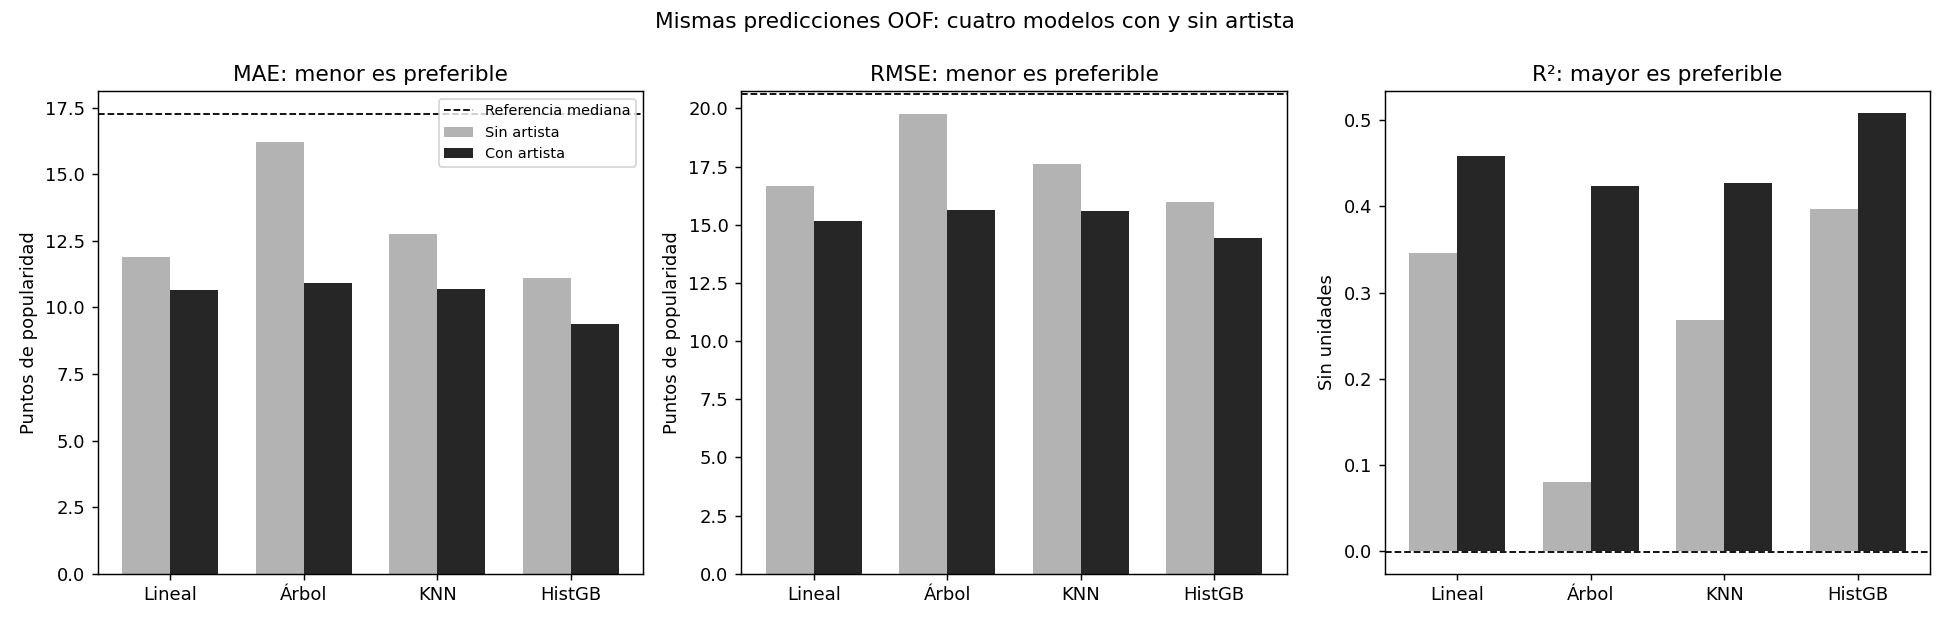

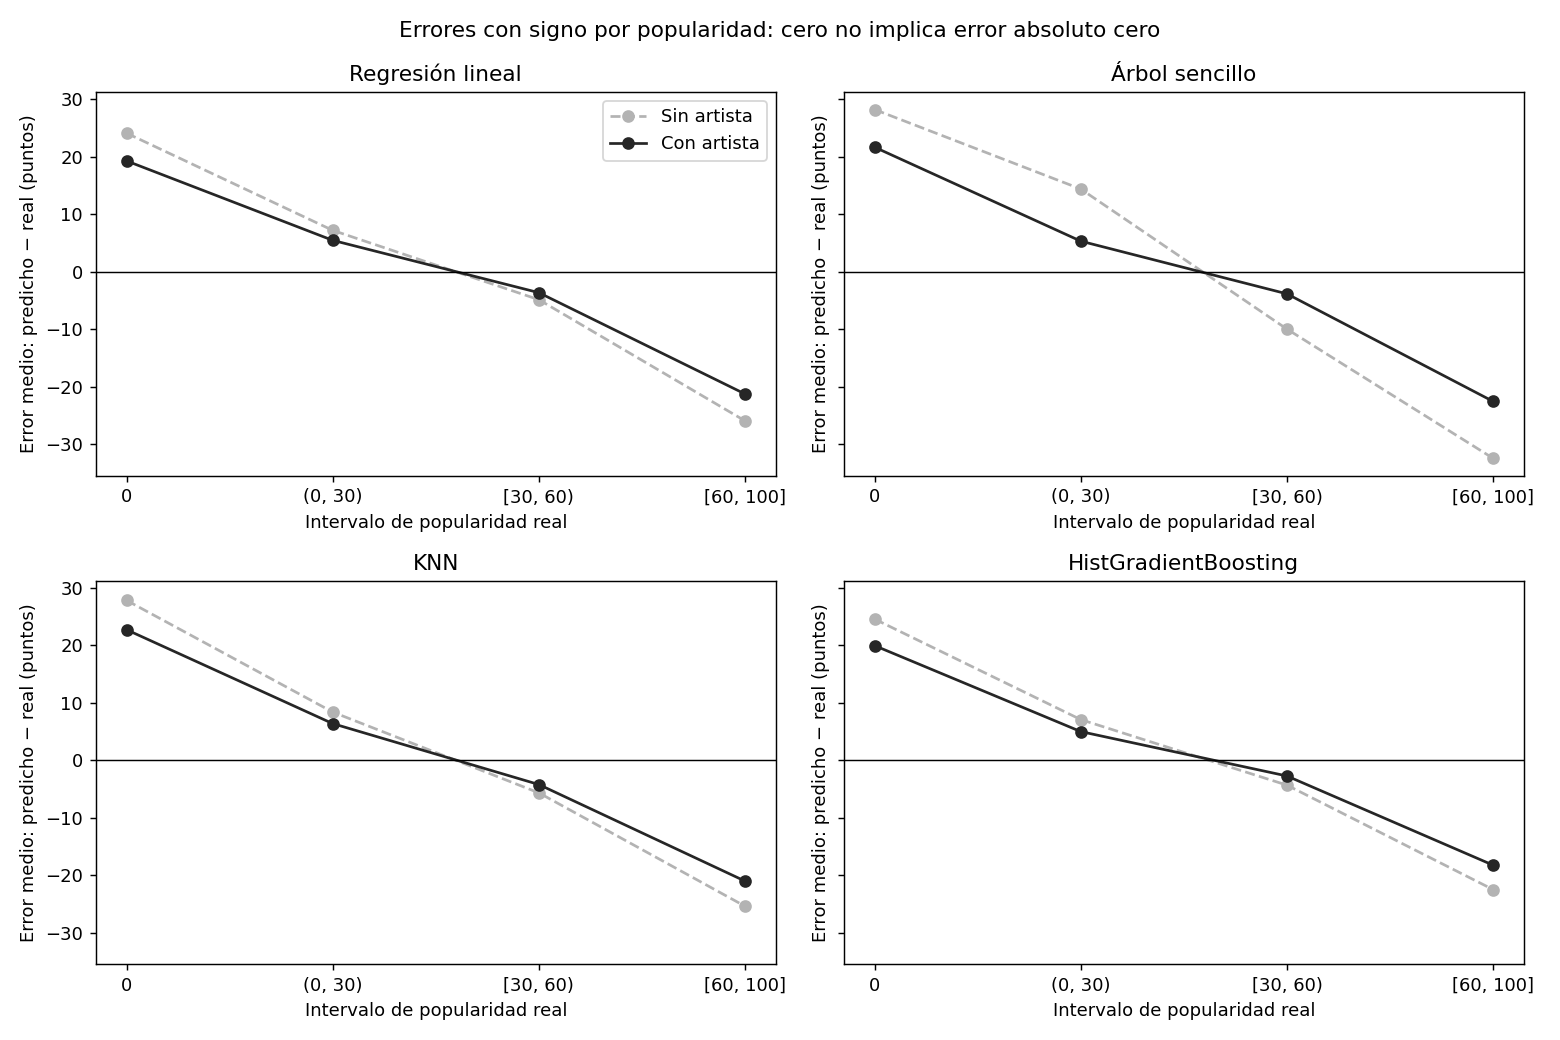

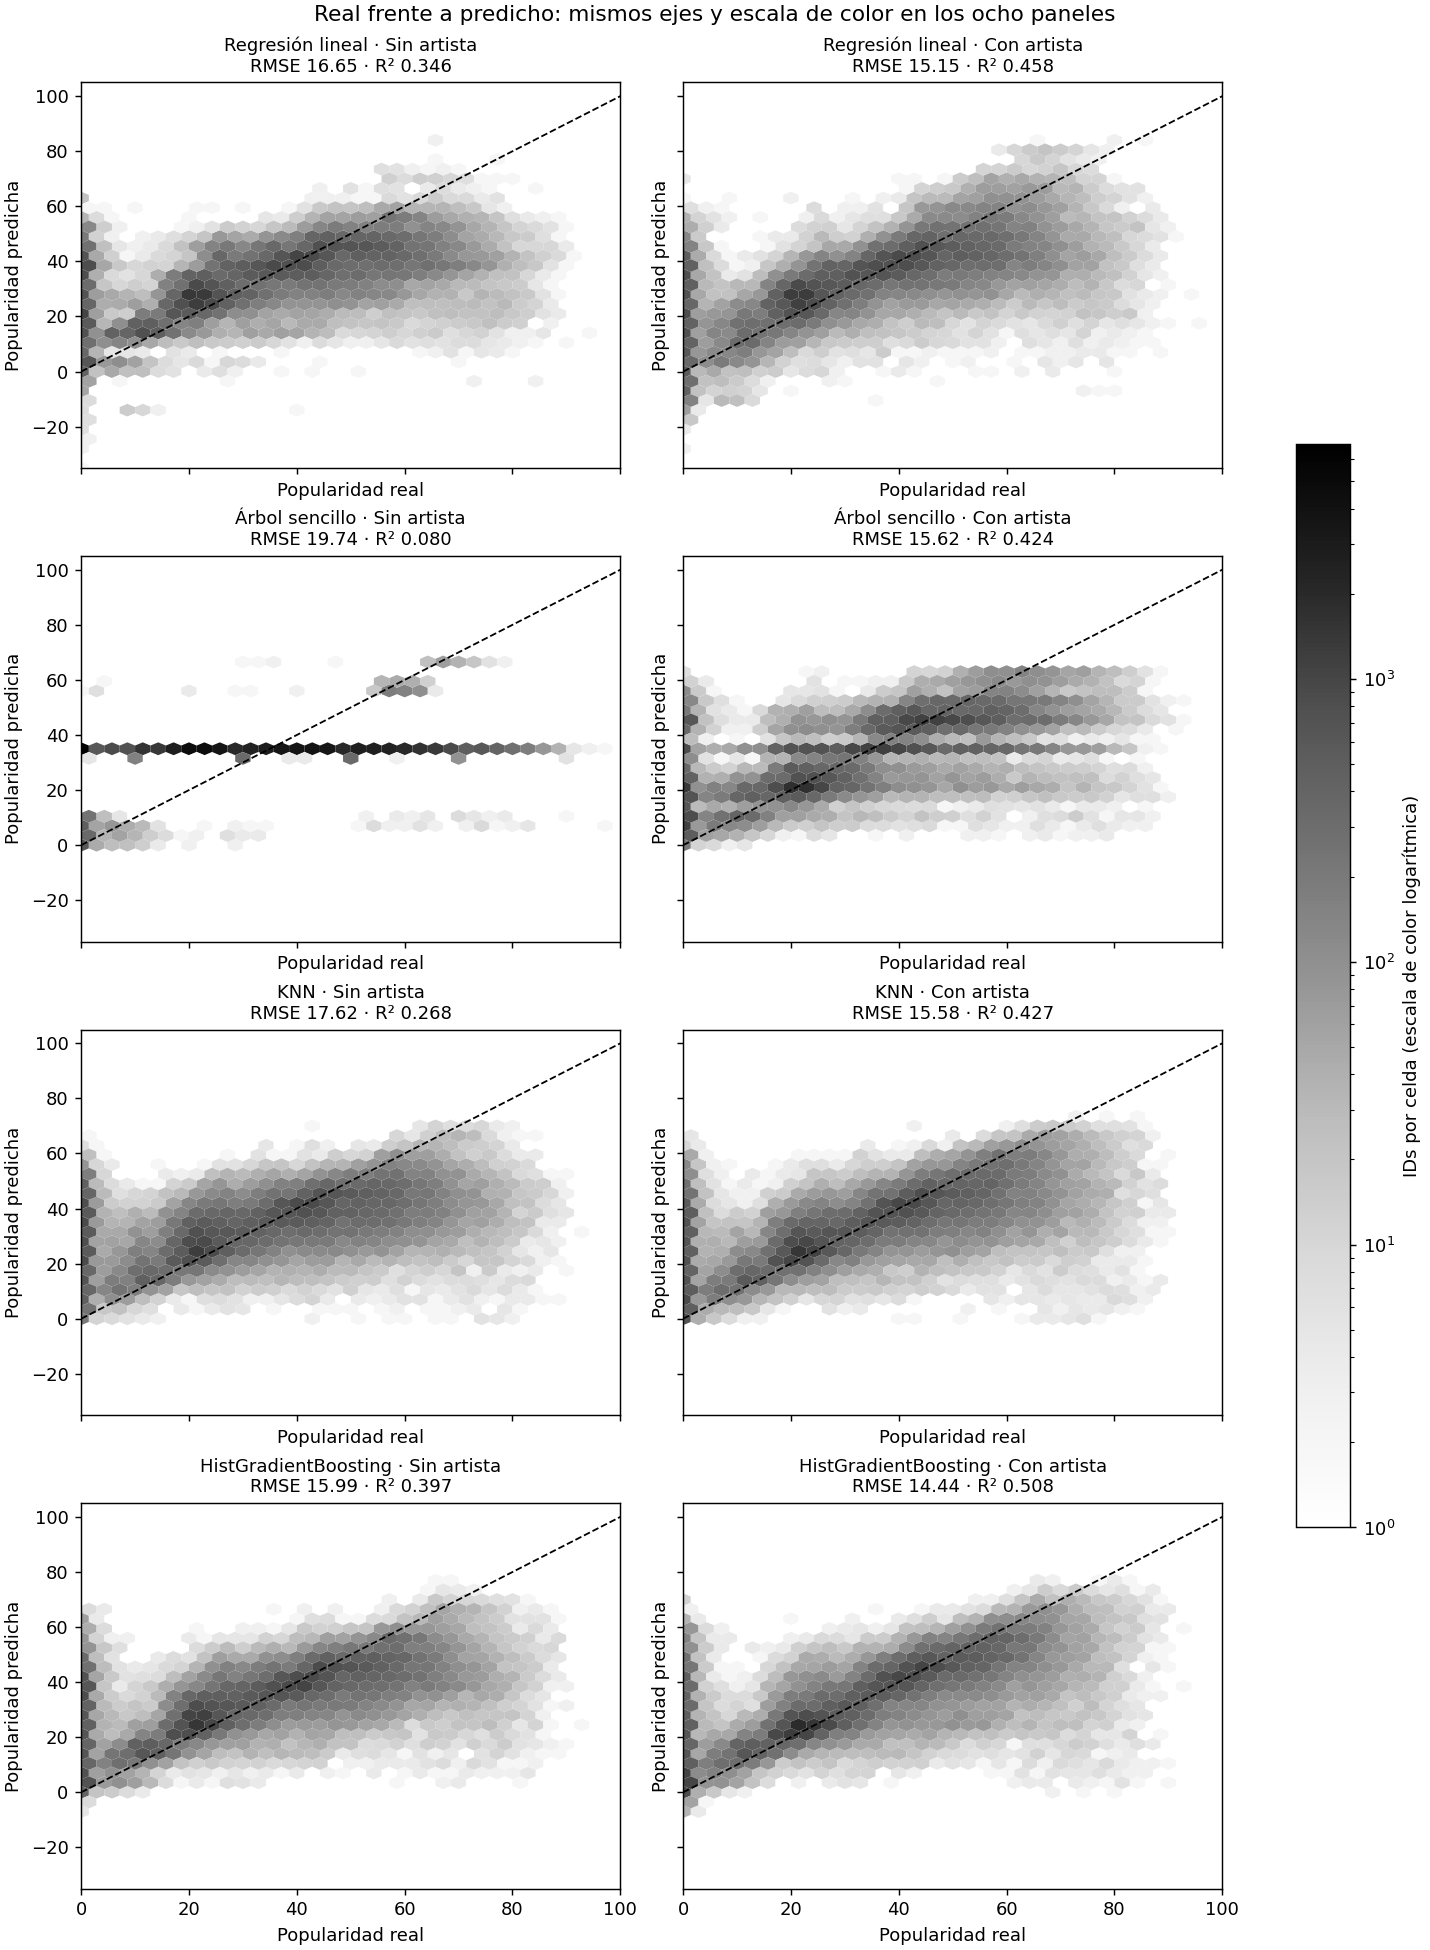

In [21]:
# Figura 1: comparar métricas en unidades separadas
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
orden_modelos = list(predicciones_sin_artista)
colores_escenario = {"Sin artista": "0.70", "Con artista": "0.15"}
fig_metricas, ejes_metricas = plt.subplots(1, 3, figsize=(15, 4.8))
posiciones_modelos = np.arange(len(orden_modelos))
for eje, metrica in zip(ejes_metricas, ["MAE", "RMSE", "R²"]):
    for escenario, desplazamiento in [("Sin artista", -0.18), ("Con artista", 0.18)]:
        valores = [tabla_metricas_oof.loc[(nombre, escenario), metrica] for nombre in orden_modelos]
        eje.bar(posiciones_modelos + desplazamiento, valores, width=0.36, color=colores_escenario[escenario], label=escenario)
    referencia_metrica = tabla_metricas_oof.loc[("Referencia de mediana", "Referencia"), metrica]
    eje.axhline(referencia_metrica, color="black", linestyle="--", linewidth=1, label="Referencia mediana")
    eje.set_xticks(posiciones_modelos, ["Lineal", "Árbol", "KNN", "HistGB"])
    eje.set_ylabel("Puntos de popularidad" if metrica != "R²" else "Sin unidades")
    eje.set_title(metrica + (": menor es preferible" if metrica != "R²" else ": mayor es preferible"))
ejes_metricas[0].legend(fontsize=8)
fig_metricas.suptitle("Mismas predicciones OOF: cuatro modelos con y sin artista")
fig_metricas.tight_layout()
display(fig_metricas)
plt.close(fig_metricas)

# Figura 2: identificar sobreestimación y subestimación por popularidad
fig_sesgo, ejes_sesgo = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for eje, nombre in zip(ejes_sesgo.flat, orden_modelos):
    for escenario in ["Sin artista", "Con artista"]:
        filtro = tabla_errores_grupos["Modelo"].eq(nombre) & tabla_errores_grupos["Escenario"].eq(escenario) & tabla_errores_grupos["Criterio"].eq("Intervalo")
        resumen = tabla_errores_grupos.loc[filtro].set_index("Grupo").reindex(etiquetas_popularidad)
        eje.plot(etiquetas_popularidad, resumen["Error medio con signo"], marker="o", color=colores_escenario[escenario], linestyle="--" if escenario == "Sin artista" else "-", label=escenario)
    eje.axhline(0, color="black", linewidth=0.8)
    eje.set_title(nombre)
    eje.set_xlabel("Intervalo de popularidad real")
    eje.set_ylabel("Error medio: predicho − real (puntos)")
ejes_sesgo[0, 0].legend()
fig_sesgo.suptitle("Errores con signo por popularidad: cero no implica error absoluto cero")
fig_sesgo.tight_layout()
display(fig_sesgo)
plt.close(fig_sesgo)

# Figura 3: todas las canciones, resumidas visualmente en celdas hexagonales
minimo_predicho = min(float(pred.min()) for clave, pred in predicciones_evaluacion.items() if clave[1] != "Referencia")
maximo_predicho = max(float(pred.max()) for clave, pred in predicciones_evaluacion.items() if clave[1] != "Referencia")
limites_prediccion = (min(-5, np.floor(minimo_predicho / 5) * 5), max(105, np.ceil(maximo_predicho / 5) * 5))
fig_real_pred, ejes_real_pred = plt.subplots(4, 2, figsize=(11, 15), sharex=True, sharey=True, constrained_layout=True)
colecciones_hex = []
for fila, nombre in enumerate(orden_modelos):
    for columna, escenario in enumerate(["Sin artista", "Con artista"]):
        eje = ejes_real_pred[fila, columna]
        pred = predicciones_evaluacion[(nombre, escenario)]
        hexagonos = eje.hexbin(y_train.to_numpy(), pred.to_numpy(), gridsize=35, extent=(0, 100, *limites_prediccion), mincnt=1, cmap="Greys", linewidths=0)
        colecciones_hex.append(hexagonos)
        eje.plot([0, 100], [0, 100], color="black", linestyle="--", linewidth=1)
        eje.set_xlim(0, 100)
        eje.set_ylim(*limites_prediccion)
        eje.set_xlabel("Popularidad real")
        eje.set_ylabel("Popularidad predicha")
        metricas_panel = tabla_metricas_oof.loc[(nombre, escenario)]
        eje.set_title(f"{nombre} · {escenario}\nRMSE {metricas_panel['RMSE']:.2f} · R² {metricas_panel['R²']:.3f}", fontsize=10)
maximo_conteo = max(float(coleccion.get_array().max()) for coleccion in colecciones_hex)
normalizacion_conteos = LogNorm(vmin=1, vmax=maximo_conteo)
for coleccion in colecciones_hex:
    coleccion.set_norm(normalizacion_conteos)
fig_real_pred.colorbar(colecciones_hex[0], ax=ejes_real_pred.ravel().tolist(), shrink=0.6, label="IDs por celda (escala de color logarítmica)")
fig_real_pred.suptitle("Real frente a predicho: mismos ejes y escala de color en los ocho paneles")
display(fig_real_pred)
plt.close(fig_real_pred)


### Hallazgos de las métricas y del diagnóstico

- **Sin artista:** el menor MAE corresponde a HistGradientBoosting: MAE 11,0990 puntos, RMSE 15,9904 puntos y R² 0,3967. El menor RMSE corresponde a HistGradientBoosting.
- **Con artista:** el menor MAE corresponde a HistGradientBoosting: MAE 9,3711 puntos, RMSE 14,4388 puntos y R² 0,5081. El menor RMSE corresponde a HistGradientBoosting.
- Para **HistGradientBoosting con artista**, R² 0,5081 equivale a una reducción de aproximadamente 50,81% en suma de errores cuadrados respecto de la constante media de las respuestas evaluadas. No es un porcentaje de canciones acertadas.
- En esa variante, el error medio con signo es 0,6193 puntos; la mediana del error absoluto es 5,3547 y su P90 es 23,8859. El 13,22% de IDs supera 20 puntos de error absoluto. Estos valores describen aspectos diferentes y no son intercambiables.

- Popularidad **0**: 7,499 IDs; MAE 20,1007 y error medio con signo 19,9657 puntos.
- Popularidad **(0, 30)**: 24,805 IDs; MAE 6,5180 y error medio con signo 5,0041 puntos.
- Popularidad **[30, 60)**: 31,563 IDs; MAE 6,7735 y error medio con signo -2,7254 puntos.
- Popularidad **[60, 100]**: 7,861 IDs; MAE 18,5675 y error medio con signo -18,2425 puntos.

Para la misma variante, según disponibilidad del artista:
- **Algunos conocidos**: 7,118 IDs; MAE 10,2110 y RMSE 14,9406 puntos.
- **Ninguno conocido**: 8,348 IDs; MAE 11,3525 y RMSE 15,6640 puntos.
- **Todos conocidos**: 56,262 IDs; MAE 8,9708 y RMSE 14,1825 puntos.

**Cómo leer el alcance:** son resultados internos de desarrollo, calculados con predicciones OOF de las mismas canciones. No se reentrenaron ni cambiaron parámetros para estas métricas. La coincidencia de un ranking en MAE, RMSE o R² se informa como descripción; no demuestra una ventaja estadística ni garantiza el resultado de prueba.

No se eliminan canciones difíciles ni se ajustan umbrales después de inspeccionar errores para presentar mejores números. Las dificultades en los extremos y en artistas sin información se documentan como limitaciones. El error promedio global no sustituye esta revisión por grupos.

**Estado de los KPI:** se conserva la meta inicial de mejora de MAE del 10% frente a mediana y los controles de separación. RMSE, R², P90 y el corte de 20 puntos amplían el diagnóstico; no se presentan como metas aprobadas retrospectivamente. La comprobación en prueba permanece pendiente.


### Elección del procedimiento en desarrollo, antes de evaluar prueba

**Criterio principal conservado:** escoger la variante con menor **MAE OOF**, entre los cuatro modelos con y sin artista y sobre las mismas canciones. RMSE, R², errores por grupos y complejidad aportan contexto; no se cambia el criterio después de ver sus valores. La referencia de mediana no compite como uno de los cuatro modelos, pero permite medir si hay mejora útil respecto de una predicción sencilla.

La elección provisional es **HistGradientBoosting con artista**, con MAE **9,3711 puntos**. Su RMSE es **14,4388** y R² **0,5081**. En estas mismas observaciones, MAE y RMSE menores son preferibles; R² mayor es preferible. La coincidencia de las métricas respalda la elección descriptiva, sin demostrar superioridad estadística.

**Justificación de las decisiones:**

- Se mantienen las mismas particiones agrupadas y una predicción OOF por ID. No elegimos otro reparto de canciones ni una ronda particularmente favorable.
- Se añade artista porque su variante reduce el MAE respecto del mismo modelo sin artista en **1,7280 puntos**. El mapa se calcula con exclusión de la propia clave en ajuste y solo con ajuste para validación. Usar esta información exige disponer de respuestas de otras canciones permitidas; no es evidencia de predicción temporal de lanzamientos.
- Frente a la regresión lineal con artista, el procedimiento elegido reduce MAE en **1,2873 puntos**. Se conserva el modelo lineal como alternativa más sencilla de explicar; no se mide aquí una ventaja de tiempo o de costo operativo.
- Se acepta la mayor complejidad del ensamble a cambio del menor error observado. Los 600 pasos, tasa 0,03 y máximo de 63 hojas permanecen como configuración fija de referencia, sin búsqueda nueva ni selección de etapas por validación.
- Se mantienen canciones difíciles y predicciones fuera de rango sin recortes posteriores. El análisis muestra dificultades en popularidad cero, éxitos y artistas desconocidos; un buen promedio no las resuelve.

**Qué significa «provisional»:** elegimos un procedimiento (preparación + codificación del artista + configuración del modelo), no un archivo ya listo para uso final. Los tres modelos ajustados por ronda sirven para validar; no se escoge el de la ronda con menor error como modelo final. Todavía no se ha ajustado una versión única con todo el entrenamiento ni se ha verificado su desempeño en prueba.

La misma validación se ha utilizado para comparar variantes y guiar el desarrollo; su mejor resultado puede ser optimista. Además, la unidad 1 exploró la fuente completa. El resultado debe describirse como evidencia interna de desarrollo, no como una evaluación externa completamente ciega.

**Lectura del código:**

1. `.reset_index()` convierte modelo y escenario en columnas. `.isin` conserva solo variantes con o sin artista, excluyendo la referencia.
2. `.sort_values("MAE", kind="stable")` ordena por el criterio principal sin alterar métricas. `.iloc[0]` recupera la variante de menor MAE. Si hubiera un empate exacto, habría que explicitar una decisión adicional; aquí no lo hay.
3. La fila de mediana proporciona la referencia ya calculada. Se comprueba que su MAE es positivo antes de dividir.
4. La reducción absoluta resta MAE modelo a MAE referencia; la mejora relativa divide esa reducción por el MAE referencia y multiplica por cien.
5. `mejora_objetivo` conserva el 10% del bloque 4. Multiplicar la referencia por `1 − mejora_objetivo` obtiene el MAE máximo compatible con esa meta en esta validación.
6. `get_params()` recupera la configuración de la plantilla del estimador elegido. No llama a `.fit`, `.predict` ni modifica sus parámetros. `especificacion_provisional` deja identificados modelo, escenario, preparación y alcance.
7. `display` muestra el ranking y la justificación numérica. Los cálculos usan precisión completa; `.round(4)` solo facilita leer las tablas.


In [22]:
# Ordenar las ocho variantes por el criterio principal previamente fijado
candidatos_provisionales = tabla_metricas_oof.reset_index()
candidatos_provisionales = candidatos_provisionales.loc[candidatos_provisionales["Escenario"].isin(["Sin artista", "Con artista"])].copy()
ranking_provisional = candidatos_provisionales.sort_values("MAE", kind="stable").reset_index(drop=True)
assert len(ranking_provisional) == 8
assert ranking_provisional["IDs"].eq(len(y_train)).all()
eleccion_provisional = ranking_provisional.iloc[0].copy()
nombre_elegido = eleccion_provisional["Modelo"]
escenario_elegido = eleccion_provisional["Escenario"]
mae_elegido = float(eleccion_provisional["MAE"])

# Mantener la misma referencia y meta, sin incorporar respuestas de prueba
mae_referencia_cierre = float(tabla_metricas_oof.loc[("Referencia de mediana", "Referencia"), "MAE"])
if mae_referencia_cierre <= 0:
    raise ValueError("La mejora relativa requiere un MAE de referencia positivo.")
reduccion_absoluta_elegido = mae_referencia_cierre - mae_elegido
mejora_relativa_elegido = reduccion_absoluta_elegido / mae_referencia_cierre * 100
mae_limite_cierre = mae_referencia_cierre * (1 - mejora_objetivo)
cumple_meta_validacion = mejora_relativa_elegido >= mejora_objetivo * 100

# Registrar un procedimiento, sin reentrenar ni escoger un modelo de una ronda
parametros_estimador_elegido = plantillas_artista[nombre_elegido].named_steps["regresion"].get_params()
especificacion_provisional = {
    "Modelo": nombre_elegido,
    "Escenario": escenario_elegido,
    "Criterio principal": "Menor MAE OOF de entrenamiento",
    "Particiones externas": numero_pliegues,
    "Preparación": "Pipeline correspondiente al modelo; parámetros aprendidos solo en ajuste",
    "Artista": "Suavizado 10, cinco particiones internas agrupadas y media de colaboradores" if escenario_elegido == "Con artista" else "No utilizado como predictor",
    "Configuración del estimador": parametros_estimador_elegido,
    "Alcance": "Elección provisional; evaluación final pendiente"
}
resumen_eleccion = pd.Series({"MAE referencia OOF": mae_referencia_cierre, "MAE elegido OOF": mae_elegido, "Reducción absoluta (puntos)": reduccion_absoluta_elegido, "Mejora relativa (%)": mejora_relativa_elegido, "Meta inicial (%)": mejora_objetivo * 100, "MAE máximo para cumplir meta": mae_limite_cierre, "Cumple meta en validación": cumple_meta_validacion})
display(ranking_provisional[["Modelo", "Escenario", "IDs", "MAE", "RMSE", "R²"]].round(4))
display(resumen_eleccion)
display(pd.Series(especificacion_provisional))


,Modelo,Escenario,IDs,MAE,RMSE,R²
0,HistGradientBoosting,Con artista,71728,9.3711,14.4388,0.5081
1,Regresión lineal,Con artista,71728,10.6583,15.1516,0.4584
2,KNN,Con artista,71728,10.6813,15.5815,0.4272
3,Árbol sencillo,Con artista,71728,10.9302,15.6250,0.4240
4,HistGradientBoosting,Sin artista,71728,11.0990,15.9904,0.3967
5,Regresión lineal,Sin artista,71728,11.8942,16.6482,0.3461
6,KNN,Sin artista,71728,12.7768,17.6174,0.2677
7,Árbol sencillo,Sin artista,71728,16.2101,19.7428,0.0804


MAE referencia OOF              17.251826
MAE elegido OOF                   9.37105
Reducción absoluta (puntos)      7.880776
Mejora relativa (%)             45.680822
Meta inicial (%)                     10.0
MAE máximo para cumplir meta    15.526644
Cumple meta en validación            True
dtype: object

Modelo                                                      HistGradientBoosting
Escenario                                                            Con artista
Criterio principal                                Menor MAE OOF de entrenamiento
Particiones externas                                                           3
Preparación                    Pipeline correspondiente al modelo; parámetros...
Artista                        Suavizado 10, cinco particiones internas agrup...
Configuración del estimador    {'categorical_features': None, 'early_stopping...
Alcance                         Elección provisional; evaluación final pendiente
dtype: object

### Cierre de KPI de desarrollo: estado anterior a evaluar prueba

Se reúnen **los cuatro indicadores definidos al inicio**. No se añaden metas retrospectivas de RMSE, R² o errores por grupos. Cumplir los controles de separación significa que el reparto satisface esas reglas; no garantiza que todas las posibles fuentes de fuga hayan sido eliminadas.

| Indicador original | Cómo se calcula | Qué significa cumplirlo |
|---|---|---|
| IDs compartidos | Cantidad de IDs presentes simultáneamente en entrenamiento y prueba, calculada al separar | El mismo ID no aparece a ambos lados |
| Claves compartidas | Cantidad de claves artista + título presentes en ambos conjuntos | Las versiones identificadas por esa clave permanecen juntas; no separa artistas completos ni detecta toda reedición posible |
| Cobertura | IDs distintos asignados / IDs de la base preparada × 100, acompañada de controles de unicidad y suma de filas | Todos los IDs se asignaron sin pérdidas, adiciones o duplicaciones entre conjuntos |
| Mejora de MAE | `(MAE mediana OOF − MAE elegido OOF) / MAE mediana OOF × 100` | La variante reduce al menos el 10% del error medio de la referencia **dentro de entrenamiento** |

Los tres primeros indicadores reutilizan **los controles estructurales del reparto ya calculados**, sin consultar respuestas de prueba ni producir predicciones para ese conjunto. El indicador predictivo utiliza únicamente OOF.

**Lectura del código:**

1. `comprobaciones_particion` aporta conteos y cobertura del bloque 3. `int` y `float` permiten presentar tipos numéricos sencillos; no cambian el indicador.
2. `cobertura_correcta` verifica 100% junto con unicidad, igualdad de IDs y suma de filas. Una cobertura de 100% por sí sola no bastaría para descartar duplicaciones.
3. La lista de diccionarios construye una fila por KPI con meta, resultado, unidad, cumplimiento, alcance y evidencia. `pd.DataFrame` la convierte en una tabla.
4. La columna `Cumple en su alcance` contiene verdaderos o falsos, no un promedio de calidad del modelo. No se mezclan los cuatro indicadores para crear una nota o un porcentaje de cumplimiento global.
5. `controles_cierre` comprueba consistencia de validación, cobertura OOF, igualdad de referencia y meta. `raise` detiene el cierre si algo no coincide; un resultado predictivo que no alcanzara el KPI se informaría como tal, no se ocultaría.
6. La Serie final registra **«Pendiente: no evaluada»** para prueba. No copia el MAE OOF como si fuera un resultado de test.

**Resultado del cierre:** la mejora es **45,68%**, equivalente a reducir el MAE en **7,8808 puntos**. La meta del 10% exigía MAE como máximo **15,5266** en esta validación; la variante elegida obtiene **9,3711**. Esto cumple la meta inicial de desarrollo, que sigue siendo una meta académica de trabajo y no una exigencia de rúbrica confirmada.

**Lo pendiente:** cuando corresponda la evaluación final, se fijará el procedimiento, se ajustará una versión con todo el entrenamiento y se evaluará una sola vez en prueba junto a una mediana aprendida con todo ese entrenamiento. Las referencias y métricas de esa etapa se calcularán para dicha etapa; no se reutilizará el 17,2518 OOF como si fuera el MAE de referencia en test. No se ejecuta ninguno de esos pasos ahora.


In [23]:
# Reutilizar controles estructurales existentes, sin volver a consultar prueba
ids_repetidos_cierre = int(comprobaciones_particion["IDs compartidos"])
claves_repetidas_cierre = int(comprobaciones_particion["Claves compartidas"])
cobertura_cierre = float(comprobaciones_particion["Cobertura de IDs (%)"])
cobertura_correcta = bool(np.isclose(cobertura_cierre, 100) and comprobaciones_particion["IDs únicos en cada conjunto"] and comprobaciones_particion["Todos los IDs asignados sin adiciones"] and comprobaciones_particion["Suma de filas coincide con base"])

# Reunir los cuatro KPI originales con sus metas, alcance y evidencia
tabla_cierre_kpi_u2 = pd.DataFrame([
    {"KPI": "IDs compartidos", "Meta": "0", "Resultado": ids_repetidos_cierre, "Unidad": "IDs", "Cumple en su alcance": ids_repetidos_cierre == 0, "Alcance": "Control estructural de partición", "Evidencia": "comprobaciones_particion: intersección de IDs"},
    {"KPI": "Claves compartidas", "Meta": "0", "Resultado": claves_repetidas_cierre, "Unidad": "Claves artista + título", "Cumple en su alcance": claves_repetidas_cierre == 0, "Alcance": "Control estructural de partición", "Evidencia": "comprobaciones_particion: intersección de claves"},
    {"KPI": "Cobertura de IDs preparados", "Meta": "100% y asignación sin duplicaciones", "Resultado": cobertura_cierre, "Unidad": "%", "Cumple en su alcance": cobertura_correcta, "Alcance": "Control estructural de partición", "Evidencia": "Cobertura, unicidad, conjunto de IDs y suma de filas"},
    {"KPI": "Mejora de MAE frente a mediana", "Meta": f">= {mejora_objetivo * 100:.0f}%", "Resultado": mejora_relativa_elegido, "Unidad": "% de reducción de MAE", "Cumple en su alcance": bool(cumple_meta_validacion), "Alcance": "Solo validación OOF dentro de entrenamiento", "Evidencia": "tabla_metricas_oof y resumen_eleccion"}
]).set_index("KPI")

# Verificar consistencia del cierre, sin cambiar metas por el resultado
controles_cierre = pd.Series({
    "Controles de validación agrupada correctos": controles_validacion.all(),
    "Controles de referencia OOF correctos": controles_oof.all(),
    "Todas las variantes evaluaron los mismos IDs": tabla_metricas_oof["IDs"].eq(len(y_train)).all(),
    "Referencia coincide con la ya calculada": np.isclose(mae_referencia_cierre, mae_referencia_oof),
    "Se conserva la meta inicial del 10%": np.isclose(mejora_objetivo, 0.10),
    "Regla porcentual equivale al límite de MAE": bool(cumple_meta_validacion) == bool(mae_elegido <= mae_limite_cierre)
})
if not controles_cierre.all():
    raise ValueError("Revisar la consistencia de la evaluación antes de cerrar los KPI.")
estado_evaluacion_final = pd.Series({"Elección del procedimiento": "Provisional, basada en OOF", "KPI predictivo en validación": "Cumple" if cumple_meta_validacion else "No cumple", "Evaluación final en prueba": "Pendiente: no evaluada", "Modelo único ajustado con todo entrenamiento": "Pendiente"})
display(tabla_cierre_kpi_u2.round({"Resultado": 4}))
display(controles_cierre)
display(estado_evaluacion_final)


,Meta,Resultado,Unidad,Cumple en su alcance,Alcance,Evidencia
KPI,,,,,,
IDs compartidos,0,0.0000,IDs,True,Control estructural de partición,comprobaciones_particion: intersección de IDs
Claves compartidas,0,0.0000,Claves artista + título,True,Control estructural de partición,comprobaciones_particion: intersección de claves
Cobertura de IDs preparados,100% y asignación sin duplicaciones,100.0000,%,True,Control estructural de partición,"Cobertura, unicidad, conjunto de IDs y suma de..."
Mejora de MAE frente a mediana,>= 10%,45.6808,% de reducción de MAE,True,Solo validación OOF dentro de entrenamiento,tabla_metricas_oof y resumen_eleccion


Controles de validación agrupada correctos      True
Controles de referencia OOF correctos           True
Todas las variantes evaluaron los mismos IDs    True
Referencia coincide con la ya calculada         True
Se conserva la meta inicial del 10%             True
Regla porcentual equivale al límite de MAE      True
dtype: bool

Elección del procedimiento                      Provisional, basada en OOF
KPI predictivo en validación                                        Cumple
Evaluación final en prueba                          Pendiente: no evaluada
Modelo único ajustado con todo entrenamiento                     Pendiente
dtype: object

### Síntesis al terminar validación, antes de abrir test

Se elige provisionalmente **HistGradientBoosting con artista** porque obtiene el menor MAE de las ocho variantes comparadas, **9,3711 puntos**. RMSE **14,4388** y R² **0,5081** complementan el resultado. Frente a la mediana OOF, la reducción de MAE es **45,68%**, por encima de la meta inicial de 10%.

Los controles estructurales reportan **0 IDs compartidos, 0 claves compartidas y 100% de cobertura**, con verificaciones de unicidad y asignación. El cumplimiento predictivo corresponde **solo a validación dentro del entrenamiento**. La tabla de KPI muestra evidencia y alcance para no confundir ambas cosas.

La elección tiene límites prácticos: el ensamble es más complejo de interpretar que la regresión lineal; la variable de artista requiere respuestas de otras canciones permitidas; los artistas desconocidos tienen menos información y persisten errores importantes en los extremos de popularidad. Para la variante elegida, el MAE cuando no conoce a ningún artista es **11,3525 puntos**, frente a **8,9708** cuando conoce a todos. Esta diferencia es descriptiva, no un efecto causal ni un resultado de una separación por artistas completos.

No se considera terminado todo el contenido de unidad 2 por cerrar esta etapa de regresión. Clasificación y aprendizaje no supervisado requieren preguntas propias y un alcance acorde con la pauta cuando esté disponible. La conexión con boosting pertenece también al recorrido de ensambles de unidad 3.

**Estado final de esta etapa:** procedimiento elegido provisionalmente y KPI de desarrollo documentados. La prueba permanece reservada, sin predicciones ni métricas de evaluación; el ajuste de una versión única y la verificación final quedan pendientes. No se cambia esa decisión ni se presenta una nota final sin esa evidencia.


El estado anterior documenta el cierre del desarrollo. A continuación se fija ese procedimiento y se realiza la evaluación final en prueba.


### Evaluación final en prueba: fijar el procedimiento y ajustar con todo el entrenamiento

**Momento de abrir test:** la elección ya se realizó mediante validación OOF. Se evalúa solamente **HistGradientBoosting con artista** frente a una mediana de referencia. No se comparan ahora los otros modelos ni se modifican parámetros, variables, reglas de artista o límites de predicción según el resultado de prueba.

**Procedimiento fijado:** tasa 0,03; 600 etapas; máximo de 63 hojas por árbol; mínimo de 20 IDs por hoja; error cuadrático como función de entrenamiento; sin parada temprana; semilla 42. El artista conserva suavizado 10, cinco particiones internas agrupadas y media entre colaboradores. Se mantiene la preparación numérica, categórica y Multi-Hot, con matriz densa. La versión de scikit-learn verificada es 1.6.1.

Ahora se usan **todos los 71.728 IDs de entrenamiento** para ajustar una única versión del modelo. Los modelos de las tres rondas anteriores no se promedian ni se selecciona el de mejor ronda.

**Cómo se evita fuga al preparar el artista:**

1. Para las filas de entrenamiento se construyen codificaciones cruzadas con cinco grupos internos de claves. Cada fila recibe un valor calculado sin sus propias respuestas ni las versiones de su clave.
2. Por separado se aprende un mapa con todo el entrenamiento para transformar test. Las respuestas de test no entran en ese mapa ni en la media de respaldo.
3. Se recuperan los artistas de test desde la parte de artista de la clave. El título solo conserva su función de agrupación y no entra como predictor. Un artista desconocido recibe la media del entrenamiento; las colaboraciones conservan la media de sus artistas.
4. La preparación del pipeline aprende medianas, escalas y categorías con las filas de entrenamiento. Test solo se transforma y se predice. Usar un nombre de artista para consultar un mapa permitido no utiliza su respuesta de test.

**Lectura del código, paso a paso:**

- `assert` comprueba la elección ya fijada y recupera los parámetros de su plantilla. `decision_final_fijada` registra el procedimiento antes de calcular métricas de prueba.
- `codificar_ajuste_cruzado` reutiliza la regla agrupada para el entrenamiento completo; `ajustar_mapa_artistas` crea el mapa permitido y su media. Ninguna función recibe `y_test`.
- `.copy()` conserva las matrices anteriores; añadir `historial_artista` crea la misma característica que se evaluó antes.
- La mediana de referencia se aprende solo con `y_train`. `pd.Series` la repite para cada ID de test; no es la media de test ni el MAE OOF de mediana anterior.
- `clone` crea un pipeline limpio. Se añade la nueva característica a la selección del bloque numérico, igual que en validación, sin cambiar el estimador.
- `.fit(X_entrenamiento_final, y_train)` realiza el ajuste único. `.predict(X_prueba_final)` genera las predicciones finales para los 18.012 IDs, sin recibir respuestas de prueba. No se recortan salidas a 0–100.
- Se comprueban parámetros, las 600 etapas, filas vistas por el escalador, medianas de imputación y media de la característica del artista. Estos controles verifican reglas concretas de preparación, no demuestran ausencia de cualquier fuga imaginable.
- La cobertura de artistas describe qué fracción de test tiene información permitida de todos, algunos o ninguno de sus artistas. No se usa para cambiar el modelo.

La variable se llama «historial» por continuidad, pero faltan fechas para verificar que las otras canciones fueran anteriores. Es información de popularidad disponible en esta partición, no una simulación temporal de lanzamientos futuros.


In [24]:
# Registrar la decisión antes de evaluar las respuestas de prueba
assert nombre_elegido == "HistGradientBoosting" and escenario_elegido == "Con artista"
parametros_finales_fijados = modelo_hgb_base.named_steps["regresion"].get_params().copy()
assert parametros_finales_fijados == parametros_estimador_elegido
assert parametros_finales_fijados["max_iter"] == 600 and parametros_finales_fijados["early_stopping"] is False
assert np.isclose(suavizado_artista, 10.0)
decision_final_fijada = {"Modelo": nombre_elegido, "Escenario": escenario_elegido, "Criterio de elección": "MAE OOF de entrenamiento", "Parámetros": parametros_finales_fijados, "Suavizado artista": suavizado_artista, "Particiones internas del artista": 5, "Colaboraciones": "Media", "Recorte de predicciones": False}

# Preparar el artista sin respuestas de test
codigo_artista_entrenamiento_final = codificar_ajuste_cruzado(artistas_entrenamiento, y_train, claves_artista, suavizado_artista)
mapa_artista_final, media_artista_final = ajustar_mapa_artistas(artistas_entrenamiento, y_train, suavizado_artista)
artistas_prueba_final = recuperar_artistas(datos_prueba["clave_cancion"])
if artistas_prueba_final.map(len).eq(0).any():
    raise ValueError("Revisar artistas faltantes antes de transformar prueba.")
codigo_artista_prueba_final = aplicar_mapa_artistas(artistas_prueba_final, mapa_artista_final, media_artista_final)
X_entrenamiento_final = X_train.copy()
X_prueba_final = X_test.copy()
X_entrenamiento_final["historial_artista"] = codigo_artista_entrenamiento_final
X_prueba_final["historial_artista"] = codigo_artista_prueba_final
assert X_entrenamiento_final.columns.equals(X_prueba_final.columns)
assert X_entrenamiento_final.index.intersection(X_prueba_final.index).empty
assert set(claves_artista).isdisjoint(set(datos_prueba["clave_cancion"]))

# Aprender la mediana de referencia solo con entrenamiento
mediana_entrenamiento_final = float(y_train.median())
predicciones_mediana_test = pd.Series(mediana_entrenamiento_final, index=X_prueba_final.index, name="mediana_test")

# Ajustar un solo modelo final con el mismo procedimiento ya elegido
modelo_final_hgb_artista = clone(modelo_hgb_base)
preparador_final = modelo_final_hgb_artista.named_steps["preparar"]
preparador_final.transformers = [(bloque, transformacion, columnas_numericas_modelo + ["historial_artista"] if bloque == "numericas" else columnas) for bloque, transformacion, columnas in preparador_final.transformers]
modelo_final_hgb_artista.fit(X_entrenamiento_final, y_train)
predicciones_hgb_test = pd.Series(modelo_final_hgb_artista.predict(X_prueba_final), index=X_prueba_final.index, name="histgradientboosting_test")

# Verificar la preparación y cobertura antes de interpretar errores
numericas_finales = modelo_final_hgb_artista.named_steps["preparar"].named_transformers_["numericas"]
assert int(numericas_finales.named_steps["escalar"].n_samples_seen_) == len(y_train)
assert np.allclose(numericas_finales.named_steps["imputar"].statistics_, X_entrenamiento_final[columnas_numericas_modelo + ["historial_artista"]].median())
assert np.isclose(numericas_finales.named_steps["escalar"].mean_[-1], codigo_artista_entrenamiento_final.mean())
assert modelo_final_hgb_artista.named_steps["regresion"].get_params() == parametros_finales_fijados
assert modelo_final_hgb_artista.named_steps["regresion"].n_iter_ == 600
assert predicciones_hgb_test.index.equals(X_prueba_final.index) and np.isfinite(predicciones_hgb_test).all()
cantidad_artistas_conocidos_test = artistas_prueba_final.map(lambda nombres: sum(a in mapa_artista_final for a in nombres))
estado_artista_test = pd.Series(np.select([cantidad_artistas_conocidos_test.eq(0), cantidad_artistas_conocidos_test.eq(artistas_prueba_final.map(len))], ["Ninguno conocido", "Todos conocidos"], default="Algunos conocidos"), index=X_prueba_final.index)
display(pd.Series(decision_final_fijada))
display(pd.Series({"IDs usados para ajuste final": len(y_train), "IDs predichos en prueba": len(predicciones_hgb_test), "Mediana aprendida en entrenamiento": mediana_entrenamiento_final, "Media de respaldo para artista desconocido": media_artista_final, "Etapas del ensamble": modelo_final_hgb_artista.named_steps["regresion"].n_iter_}))
display(estado_artista_test.value_counts().rename("IDs de prueba por información del artista"))


Modelo                                                           HistGradientBoosting
Escenario                                                                 Con artista
Criterio de elección                                         MAE OOF de entrenamiento
Parámetros                          {'categorical_features': None, 'early_stopping...
Suavizado artista                                                                10.0
Particiones internas del artista                                                    5
Colaboraciones                                                                  Media
Recorte de predicciones                                                         False
dtype: object

IDs usados para ajuste final                  71728.000000
IDs predichos en prueba                       18012.000000
Mediana aprendida en entrenamiento               33.000000
Media de respaldo para artista desconocido       33.236045
Etapas del ensamble                             600.000000
dtype: float64

Todos conocidos      15015
Algunos conocidos     1523
Ninguno conocido      1474
Name: IDs de prueba por información del artista, dtype: int64

### Evaluación en test: comparar con la mediana y contextualizar frente a validación

**Solo ahora se comparan las predicciones finales con `y_test`.** No se usa `y_test` en `.fit`, mapas de artista, imputación, escalamiento ni elección de parámetros.

**Lectura del código:**

1. Las métricas se calculan para dos predicciones sobre los mismos IDs: mediana de entrenamiento e HistGradientBoosting con artista. `assert` comprueba alineación y valores finitos. `mean_absolute_error`, `root_mean_squared_error` y `r2_score` conservan las definiciones ya explicadas.
2. La mejora relativa en test se calcula con el **MAE de la mediana en test**: `(MAE mediana test − MAE modelo test) / MAE mediana test × 100`. No se utiliza el 17,2518 de la referencia OOF como denominador.
3. `comparacion_desarrollo_test` muestra ambos escenarios de evaluación. El modelo final se ajustó con más datos que cada modelo de las rondas OOF; no son exactamente el mismo ajuste ni las mismas canciones. La diferencia test menos OOF se informa, sin buscar parámetros que la reduzcan.
4. La tabla de ejemplos conserva los primeros cinco IDs de test, sin elegir aciertos. La convención del error es predicho menos real. La media con signo puede cancelar errores; no reemplaza MAE ni RMSE.
5. Se muestran percentil 90, proporción con más de 20 puntos de error y salidas fuera de escala, sin modificar predicciones. `groupby` describe MAE según artistas conocidos, sin seleccionar otro modelo para cada grupo.

**Interpretación:** MAE y RMSE se expresan en puntos de popularidad, no en porcentajes de error. RMSE da mayor peso a errores grandes. R² compara suma de errores cuadrados con la constante media de las respuestas evaluadas, no con la mediana operativa. Su cálculo utiliza `y_test` para evaluar, no para entrenar una constante disponible de antemano. El R² de la mediana puede ser ligeramente negativo.

Una diferencia pequeña entre desarrollo y prueba es compatible con desempeño similar en este reparto, pero no demuestra que no haya sobreajuste ni fuga. Tampoco vuelve esta muestra una prueba externa ciega: la fuente ya se exploró en unidad 1 y se tomó una configuración de un proyecto previo sobre ella.


In [25]:
# Evaluar una vez las dos predicciones finales en las mismas respuestas de test
registros_test_final = []
for procedimiento, pred in {"Mediana de entrenamiento": predicciones_mediana_test, "HistGradientBoosting con artista": predicciones_hgb_test}.items():
    assert pred.index.equals(y_test.index) and np.isfinite(pred).all()
    registros_test_final.append({"Procedimiento": procedimiento, "IDs test": len(y_test), "MAE": mean_absolute_error(y_test, pred), "RMSE": root_mean_squared_error(y_test, pred), "R²": r2_score(y_test, pred)})
tabla_evaluacion_test = pd.DataFrame(registros_test_final).set_index("Procedimiento")
mae_mediana_test = float(tabla_evaluacion_test.loc["Mediana de entrenamiento", "MAE"])
mae_hgb_test = float(tabla_evaluacion_test.loc["HistGradientBoosting con artista", "MAE"])
if mae_mediana_test <= 0:
    raise ValueError("La mejora relativa requiere un MAE de referencia positivo.")
reduccion_mae_test = mae_mediana_test - mae_hgb_test
mejora_mae_test = reduccion_mae_test / mae_mediana_test * 100
limite_mae_test = mae_mediana_test * (1 - mejora_objetivo)

# Distinguir desempeño de desarrollo y prueba, sin modificar el procedimiento
comparacion_desarrollo_test = pd.DataFrame([
    {"Evaluación": "Validación OOF de entrenamiento", "IDs evaluados": len(y_train), "MAE modelo": float(eleccion_provisional["MAE"]), "RMSE modelo": float(eleccion_provisional["RMSE"]), "R² modelo": float(eleccion_provisional["R²"]), "MAE referencia propia": mae_referencia_cierre, "Mejora vs referencia propia (%)": mejora_relativa_elegido},
    {"Evaluación": "Prueba del modelo final", "IDs evaluados": len(y_test), "MAE modelo": mae_hgb_test, "RMSE modelo": float(tabla_evaluacion_test.loc["HistGradientBoosting con artista", "RMSE"]), "R² modelo": float(tabla_evaluacion_test.loc["HistGradientBoosting con artista", "R²"]), "MAE referencia propia": mae_mediana_test, "Mejora vs referencia propia (%)": mejora_mae_test}
]).set_index("Evaluación")

# Revisar ejemplos y límites sin recortar ni corregir el resultado
revision_test_final = pd.DataFrame({"Real": y_test, "Mediana": predicciones_mediana_test, "HistGradientBoosting": predicciones_hgb_test, "Estado artista": estado_artista_test})
revision_test_final["Error con signo"] = revision_test_final["HistGradientBoosting"] - revision_test_final["Real"]
revision_test_final["Error absoluto"] = revision_test_final["Error con signo"].abs()
diagnostico_test_final = pd.Series({"Error medio con signo (puntos)": revision_test_final["Error con signo"].mean(), "P90 del error absoluto (puntos)": revision_test_final["Error absoluto"].quantile(0.90), "Error absoluto >20 puntos (%)": revision_test_final["Error absoluto"].gt(20).mean() * 100, "Predicciones menores que 0": int(predicciones_hgb_test.lt(0).sum()), "Predicciones mayores que 100": int(predicciones_hgb_test.gt(100).sum()), "MAE test menos MAE OOF (puntos)": mae_hgb_test - float(eleccion_provisional["MAE"])})
error_por_artista_test = revision_test_final.groupby("Estado artista").agg(IDs=("Real", "size"), MAE=("Error absoluto", "mean"), error_medio=("Error con signo", "mean"))
display(tabla_evaluacion_test.round(4))
display(comparacion_desarrollo_test.round(4))
display(revision_test_final.head(5).round(4))
display(diagnostico_test_final.round(4))
display(error_por_artista_test.round(4))


,IDs test,MAE,RMSE,R²
Procedimiento,,,,
Mediana de entrenamiento,18012,17.1629,20.5370,-0.0000
HistGradientBoosting con artista,18012,9.1251,14.1016,0.5285


,IDs evaluados,MAE modelo,RMSE modelo,R² modelo,MAE referencia propia,Mejora vs referencia propia (%)
Evaluación,,,,,,
Validación OOF de entrenamiento,71728,9.3711,14.4388,0.5081,17.2518,45.6808
Prueba del modelo final,18012,9.1251,14.1016,0.5285,17.1629,46.8322


,Real,Mediana,HistGradientBoosting,Estado artista,Error con signo,Error absoluto
track_id,,,,,,
0000vdREvCVMxbQTkS888c,44.0,33.0,37.7224,Ninguno conocido,-6.2776,6.2776
002qpSULhHAw6DGqFxbaO1,17.0,33.0,19.4381,Ninguno conocido,2.4381,2.4381
005NLlv3rClEVqeoSyYTHU,20.0,33.0,23.6639,Todos conocidos,3.6639,3.6639
005U5ZHLoA4OEkWewAa32S,14.0,33.0,15.1233,Todos conocidos,1.1233,1.1233
006Bi4j0yzwOc3y69GOlYV,36.0,33.0,43.0676,Todos conocidos,7.0676,7.0676


Error medio con signo (puntos)      0.7095
P90 del error absoluto (puntos)    23.1098
Error absoluto >20 puntos (%)      12.8748
Predicciones menores que 0         83.0000
Predicciones mayores que 100        0.0000
MAE test menos MAE OOF (puntos)    -0.2459
dtype: float64

,IDs,MAE,error_medio
Estado artista,,,
Algunos conocidos,1523,9.7268,1.2494
Ninguno conocido,1474,11.9450,0.9075
Todos conocidos,15015,8.7873,0.6353


### Cierre final de los KPI de regresión

Se conservan los mismos cuatro KPI. Los tres indicadores de partición no cambian: abrir test para evaluarlo no altera sus IDs ni sus claves. El indicador predictivo se verifica ahora con la referencia y el modelo evaluados **en test**.

**Lectura del código:**

- `.copy(deep=True)` conserva la tabla de desarrollo como evidencia y crea una tabla final independiente.
- La fila de mejora de MAE se actualiza con `mejora_mae_test`, su unidad, alcance y evidencia. Se utiliza la misma meta del 10%; no se agregan retrospectivamente umbrales de RMSE o R².
- Se comprueba que la comparación porcentaje/límite de MAE sea consistente y que ambas predicciones cubran todos los IDs de prueba.
- `.all()` resume el cumplimiento de estos cuatro indicadores, pero no convierte sus resultados en una nota académica ni garantiza calidad suficiente para cualquier uso.
- `estado_evaluacion_final` sustituye el estado pendiente anterior. El cierre informa el resultado real aunque no se cumpla la meta; un fallo de meta no provoca buscar otro modelo en test.

**Resultado:** mediana de entrenamiento **33,0**; MAE de referencia en test **17,1629**; MAE del modelo **9,1251**. La reducción es **8,0377 puntos**, equivalente a **46,83%**, frente a una meta del 10%. Por tanto, el KPI predictivo **cumple** en este conjunto de prueba. El MAE máximo para cumplir esa meta era **15,4466**.


In [26]:
# Mantener evidencia de desarrollo y actualizar el alcance del cierre final
tabla_kpi_final_test = tabla_cierre_kpi_u2.copy(deep=True)
tabla_kpi_final_test.loc["Mejora de MAE frente a mediana", "Resultado"] = mejora_mae_test
tabla_kpi_final_test.loc["Mejora de MAE frente a mediana", "Cumple en su alcance"] = bool(mejora_mae_test >= mejora_objetivo * 100)
tabla_kpi_final_test.loc["Mejora de MAE frente a mediana", "Alcance"] = "Evaluación final en prueba del procedimiento fijado"
tabla_kpi_final_test.loc["Mejora de MAE frente a mediana", "Evidencia"] = "tabla_evaluacion_test: mediana de entrenamiento y modelo final"
assert bool(mejora_mae_test >= mejora_objetivo * 100) == bool(mae_hgb_test <= limite_mae_test)
assert tabla_evaluacion_test["IDs test"].eq(len(y_test)).all()
assert np.isclose(mae_hgb_test, revision_test_final["Error absoluto"].mean())
estado_evaluacion_final = pd.Series({"Procedimiento evaluado": "HistGradientBoosting con artista, configuración fijada en desarrollo", "Modelo único ajustado con todo entrenamiento": "Realizado", "Evaluación en prueba": "Realizada sin seleccionar otros modelos", "KPI predictivo en prueba": "Cumple" if mejora_mae_test >= mejora_objetivo * 100 else "No cumple", "Cuatro KPI en su alcance": "Cumplen" if tabla_kpi_final_test["Cumple en su alcance"].all() else "Revisar indicadores no cumplidos", "Uso de prueba en cambios futuros": "Ya observada; no es evidencia independiente para cambios guiados por ella"})
display(tabla_kpi_final_test.round({"Resultado": 4}))
display(estado_evaluacion_final)


,Meta,Resultado,Unidad,Cumple en su alcance,Alcance,Evidencia
KPI,,,,,,
IDs compartidos,0,0.0000,IDs,True,Control estructural de partición,comprobaciones_particion: intersección de IDs
Claves compartidas,0,0.0000,Claves artista + título,True,Control estructural de partición,comprobaciones_particion: intersección de claves
Cobertura de IDs preparados,100% y asignación sin duplicaciones,100.0000,%,True,Control estructural de partición,"Cobertura, unicidad, conjunto de IDs y suma de..."
Mejora de MAE frente a mediana,>= 10%,46.8322,% de reducción de MAE,True,Evaluación final en prueba del procedimiento f...,tabla_evaluacion_test: mediana de entrenamient...


Procedimiento evaluado                          HistGradientBoosting con artista, configuració...
Modelo único ajustado con todo entrenamiento                                            Realizado
Evaluación en prueba                                      Realizada sin seleccionar otros modelos
KPI predictivo en prueba                                                                   Cumple
Cuatro KPI en su alcance                                                                  Cumplen
Uso de prueba en cambios futuros                Ya observada; no es evidencia independiente pa...
dtype: object

### Conclusión de la evaluación final de regresión

Se evaluó **HistGradientBoosting con artista**, elegido mediante validación OOF, sobre **18.012 IDs de test** después de ajustarlo con los **71.728 IDs de entrenamiento**. Se mantuvieron parámetros, variables, codificación y predicciones sin recortes.

| Procedimiento en test | MAE | RMSE | R² |
|---|---:|---:|---:|
| Mediana de entrenamiento | 17,1629 | 20,5370 | ≈ 0 |
| HistGradientBoosting con artista | 9,1251 | 14,1016 | 0,5285 |

La mejora de MAE es **46,83%** frente a la mediana evaluada en esas mismas canciones. El KPI inicial del 10% **cumple**. Los controles estructurales conservan 0 IDs y 0 claves compartidos y cobertura del 100%, con controles de unicidad. No se establecieron metas nuevas para RMSE o R².

El MAE de test menos el MAE OOF es **-0,2459 puntos**. El resultado describe este reparto y no prueba por sí solo ausencia de sobreajuste, fuga o sesgos. R² **0,5285** equivale a aproximadamente **52,85%** de reducción en suma de errores cuadrados frente a la constante media de las respuestas de test; no es un porcentaje de canciones acertadas ni una medida causal.

Persisten limitaciones: exposición exploratoria de la fuente en unidad 1, configuración de referencia de un proyecto previo, falta de fechas, posibles reediciones no detectadas y menor información para artistas desconocidos. La popularidad no mide calidad musical. Las tablas de diagnóstico ayudan a valorar estos límites sin cambiar el procedimiento tras observar test.

**Esta evaluación cierra la comprobación de la regresión elegida, no todos los contenidos de unidad 2.** Cualquier cambio posterior inspirado en estos errores debe tratar este test como ya observado y requerirá nueva evidencia independiente para una confirmación final. No se reelige el modelo ni se ajustan sus parámetros con este resultado.


<a id="bloque-9"></a>
## 9. Clasificación: identificar canciones con popularidad de 60 o más

### Objetivo y decisiones iniciales

**Objetivo:** identificar si el puntaje de popularidad registrado de una canción es **mayor o igual a 60**, utilizando características musicales, categorías y géneros. En este escenario académico, interesa priorizar canciones para revisión; no se afirma que el sistema pueda anticipar éxitos futuros ni medir calidad artística.

La regresión estima un número, por ejemplo 57,4. Esta clasificación responde una pregunta de dos opciones: **¿cumple el corte de 60?** Se construye una respuesta binaria a partir de la popularidad preparada en unidad 1, sin reemplazarla ni modificarla.

| Clase | Regla sobre la popularidad preparada | Interpretación |
|---|---|---|
| `0` — negativa | Menor que 60 | No cumple este corte de popularidad |
| `1` — positiva | Mayor o igual a 60 | Cumple este corte de popularidad |

**Por qué 60:** se adopta un corte de trabajo explícito para esta pregunta académica. No es una definición oficial o universal de «éxito» ni una cifra derivada para maximizar el resultado de un clasificador. La pauta aún no confirma una exigencia de este valor. Se fija antes de entrenar clasificación y se conserva aunque los resultados no sean favorables.

**Qué se pierde al convertir el número en una etiqueta:** una canción con 0 y otra con 59,5 pertenecen a clase 0, aunque sus puntajes sean muy distintos. Una canción con 59,5 y otra con 60 quedan en clases distintas pese a estar muy cerca. Los medios puntos pueden aparecer porque la base resume discrepancias por ID mediante la mediana. Aquí se usa esa misma respuesta preparada, no una popularidad nueva.

**Alcance de datos:** este bloque utiliza exclusivamente **los 71.728 IDs de entrenamiento** y las mismas tres particiones agrupadas por artista + título. No se vuelve a repartir el dataset, no se crean etiquetas de test y no se consultan sus respuestas para definir clases, metas o distribución. Test ya fue observado en regresión; una futura evaluación de clasificación no podría presentarlo como una muestra completamente nueva y ciega.

**Primera preparación prevista:** comenzar con `X_train`, las mismas 127 características sin artista. La popularidad, la nueva etiqueta, el ID y la clave no entran como predictores. No se reutiliza el mapa final de artista de regresión para validar clasificación, porque ese mapa conoce respuestas de todo el entrenamiento, incluidas las futuras validaciones internas. Si se incorpora artista después, deberá aprenderse de nuevo dentro de cada ajuste con exclusión de la propia clave.

### Código para construir las clases y revisar su distribución

1. `corte_popularidad_clasificacion = 60.0` deja visible la regla elegida. Se verifica que `y_train` tenga valores válidos antes de comparar: una ausencia no debe convertirse silenciosamente en clase 0.
2. `.ge(60)` devuelve verdadero para popularidad mayor o igual a 60. `.astype("int8")` convierte verdadero en 1 y falso en 0; es una representación compacta de la etiqueta, no un orden de calidad musical. `.rename` identifica la nueva Serie. No se altera `y_train`.
3. Se comprueba que índices y cantidad de filas coincidan con `X_train`, que solo existan 0 y 1 y que ninguna columna de respuesta o auxiliar aparezca entre las entradas.
4. `.value_counts()` cuenta canciones por clase; `.reindex([0, 1], fill_value=0)` conserva ambas filas y el orden aun si alguna clase faltara. Dividir por el total y multiplicar por 100 obtiene la proporción.
5. `pd.crosstab` cuenta clases por partición de validación; se suma 1 al código de pliegue solo para mostrar rondas 1, 2 y 3. Restar sus conteos del total obtiene cuántas filas de cada clase quedarían en ajuste. No se aprende un modelo.
6. Los controles comprueban ambas clases en cada ajuste y validación, cobertura y agrupación. Un ID aparece como validación una vez, y todas las versiones de su clave permanecen en el mismo pliegue. `raise` detiene el bloque si falla la estructura.
7. `exactitud_regla_siempre_cero` calcula cuántas etiquetas acertaría la regla fija «ninguna canción cumple». Es una descripción en entrenamiento, **no el resultado OOF de un clasificador entrenado**.


In [27]:
# Construir una respuesta binaria sin alterar la popularidad original
corte_popularidad_clasificacion = 60.0
if not (y_train.notna().all() and np.isfinite(y_train).all() and y_train.between(0, 100).all()):
    raise ValueError("Revisar popularidades faltantes o fuera de rango antes de crear clases.")
y_clasificacion_train = y_train.ge(corte_popularidad_clasificacion).astype("int8").rename("clase_popularidad_60")
columnas_prohibidas_clasificacion = ["popularity", "clase_popularidad_60", "track_id", "clave_cancion", "historial_artista"]
assert y_clasificacion_train.index.equals(X_train.index)
assert len(y_clasificacion_train) == len(y_train)
assert y_clasificacion_train.isin([0, 1]).all()
assert all(columna not in X_train.columns for columna in columnas_prohibidas_clasificacion)

# Describir cantidades y proporciones de las dos clases, solo en entrenamiento
conteos_clases_train = y_clasificacion_train.value_counts().reindex([0, 1], fill_value=0)
distribucion_clases_train = pd.DataFrame({"Interpretación": ["Popularidad <60", "Popularidad >=60"], "IDs": conteos_clases_train, "Porcentaje de entrenamiento": conteos_clases_train / len(y_clasificacion_train) * 100})
distribucion_clases_train.index.name = "Clase"

# Revisar la presencia de ambas clases con las mismas particiones agrupadas
conteos_clases_por_ronda = pd.crosstab(pliegue_por_id + 1, y_clasificacion_train).reindex(index=range(1, numero_pliegues + 1), columns=[0, 1], fill_value=0)
resumen_clases_por_ronda = pd.DataFrame({"Ajuste clase 0": int(conteos_clases_train.loc[0]) - conteos_clases_por_ronda[0], "Ajuste clase 1": int(conteos_clases_train.loc[1]) - conteos_clases_por_ronda[1], "Validación clase 0": conteos_clases_por_ronda[0], "Validación clase 1": conteos_clases_por_ronda[1]})
resumen_clases_por_ronda.index.name = "Ronda"
resumen_clases_por_ronda["Clase 1 en validación (%)"] = conteos_clases_por_ronda[1] / conteos_clases_por_ronda.sum(axis=1) * 100
claves_por_pliegue_clasificacion = pd.DataFrame({"Clave": datos_entrenamiento["clave_cancion"], "Pliegue": pliegue_por_id}).groupby("Clave")["Pliegue"].nunique()
controles_inicio_clasificacion = pd.Series({
    "Etiquetas válidas y alineadas": y_clasificacion_train.notna().all() and y_clasificacion_train.isin([0, 1]).all() and y_clasificacion_train.index.equals(X_train.index),
    "Dos clases en entrenamiento": conteos_clases_train.gt(0).all(),
    "Ambas clases en cada ajuste y validación": resumen_clases_por_ronda[["Ajuste clase 0", "Ajuste clase 1", "Validación clase 0", "Validación clase 1"]].gt(0).all().all(),
    "Validaciones cubren entrenamiento": int(conteos_clases_por_ronda.to_numpy().sum()) == len(y_clasificacion_train),
    "Cada clave pertenece a un único pliegue": claves_por_pliegue_clasificacion.eq(1).all(),
    "Se conservan los tres pliegues válidos": pliegue_por_id.notna().all() and pliegue_por_id.isin(range(numero_pliegues)).all()
})
if not controles_inicio_clasificacion.all():
    raise ValueError("Revisar etiquetas y particiones antes de entrenar clasificación.")

# Advertir con números por qué accuracy no basta para esta pregunta
prevalencia_clase_1_train = float(y_clasificacion_train.mean())
exactitud_regla_siempre_cero = float(y_clasificacion_train.eq(0).mean())
display(distribucion_clases_train.round(4))
display(resumen_clases_por_ronda.round(4))
display(controles_inicio_clasificacion)
display(pd.Series({"Accuracy descriptiva de decir siempre clase 0 (%)": exactitud_regla_siempre_cero * 100, "Recall de clase 1 con esa regla (%)": 0.0, "F1 de clase 1 con esa regla": 0.0}))


,Interpretación,IDs,Porcentaje de entrenamiento
Clase,,,
0,Popularidad <60,63867,89.0405
1,Popularidad >=60,7861,10.9595


,Ajuste clase 0,Ajuste clase 1,Validación clase 0,Validación clase 1,Clase 1 en validación (%)
Ronda,,,,,
1,42625,5190,21242,2671,11.1697
2,42378,5246,21489,2615,10.8488
3,42731,5286,21136,2575,10.8599


Etiquetas válidas y alineadas               True
Dos clases en entrenamiento                 True
Ambas clases en cada ajuste y validación    True
Validaciones cubren entrenamiento           True
Cada clave pertenece a un único pliegue     True
Se conservan los tres pliegues válidos      True
dtype: bool

Accuracy descriptiva de decir siempre clase 0 (%)    89.040542
Recall de clase 1 con esa regla (%)                   0.000000
F1 de clase 1 con esa regla                           0.000000
dtype: float64

### Interpretación de la distribución de entrenamiento

Hay **63.867 canciones de clase 0 (89,04%)** y **7.861 de clase 1 (10,96%)**. La clase de interés es minoritaria, por lo que una exactitud global elevada puede ocultar que casi no se detectan canciones que cumplen el corte.

La regla fija «todas son clase 0» acertaría **89,04%** de estas etiquetas de entrenamiento, pero encontraría **cero canciones de clase 1**: recall 0 y F1 positivo 0. Su precisión positiva queda indefinida porque nunca predice positivos; cuando se evalúe una referencia, se explicitará si el reporte la representa como 0 por convención. Este cálculo descriptivo no es una validación ni una prueba de un modelo.

Las tres rondas conservan ambas clases en ajuste y validación. Sus proporciones no tienen que ser exactamente iguales: se mantiene el agrupamiento de canciones, sin forzar una estratificación que reparta versiones de la misma clave entre partes. Se informarán las cantidades y las métricas de cada ronda.

**Decisión inicial:** no aplicar balanceo ni descartar canciones en este bloque. Primero necesitamos una referencia y un clasificador sencillo para entender sus errores. Si más adelante se prueba ponderación o remuestreo, se aplicará solo dentro del ajuste de cada ronda, nunca sobre la validación ni antes de dividir.


### Métricas, KPI y regla de comparación fijados antes de entrenar

La clase positiva siempre será **1: popularidad >=60**. Las métricas positivas no se confunden con un promedio entre clases.

| Resultado | Qué significa en este proyecto |
|---|---|
| Verdadero positivo (TP) | Cumple el corte y el modelo lo identifica |
| Falso negativo (FN) | Cumple el corte, pero el modelo no lo identifica |
| Falso positivo (FP) | No cumple el corte, pero el modelo lo señala como si lo cumpliera |
| Verdadero negativo (TN) | No cumple el corte y el modelo lo identifica como clase 0 |

- **Recall de clase 1 = TP / (TP + FN):** de todas las canciones que realmente cumplen el corte, cuántas encontramos. Se prioriza su revisión porque dejar muchas fuera contradice el objetivo de identificación.
- **Precisión de clase 1 = TP / (TP + FP):** de todas las que señalamos, cuántas realmente cumplen. Evita que una estrategia que marca prácticamente todas como positivas parezca suficiente solo por su recall.
- **F1 de clase 1 = 2 × precisión × recall / (precisión + recall):** combina ambos en un número entre 0 y 1. Será el criterio principal de comparación entre procedimientos que cumplan las dos metas predictivas. Si ninguno las cumple, se informará el incumplimiento; no se bajarán las metas para declarar éxito. No se fija un umbral extra de F1 sin una necesidad justificada.
- **Accuracy:** proporción global de etiquetas correctas. Se reportará como complemento, sin usarla sola para escoger el modelo ni darle una meta basada en el resultado de la regla mayoritaria.

| KPI | Meta inicial | Justificación |
|---|---|---|
| Recall de clase 1 | **>=60%** | Encontrar al menos 6 de cada 10 canciones que realmente cumplen el corte |
| Precisión de clase 1 | **>=30%** | Que al menos 3 de cada 10 señaladas realmente cumplan; pone un límite mínimo a falsas alarmas |
| Etiquetas de entrenamiento válidas y alineadas | **100%** | Cada ID conserva una etiqueta coherente con la regla >=60 |
| Claves compartidas entre ajuste y validación | **0** en cada ronda | Evitar que versiones identificadas de la misma canción crucen esa separación |
| Cobertura de predicciones OOF de clasificación | **100%** | Evaluar una predicción por cada ID de entrenamiento, cuando se entrenen los modelos |

**Origen y alcance de las metas:** 60% de recall y 30% de precisión son metas académicas iniciales, fijadas ahora antes de obtener predicciones de clasificación. No provienen de una rúbrica confirmada ni de costos comerciales medidos. Favorecen encontrar canciones de interés aceptando falsas alarmas, pero no describen un sistema listo para operar. La meta de precisión es superior a la proporción observada de clase 1 (10,96%); aun así, permite que hasta el 70% de las canciones señaladas no cumplan el corte. Si ese costo fuera inaceptable, habría que definir el problema y las metas de otra forma antes de una nueva evaluación.

**Ejemplo ficticio:** TP=6, FN=4, FP=14 y TN=76. Recall=6/10=60%; precisión=6/20=30%; F1=0,40 y accuracy=82%. Cumple ambas metas predictivas iniciales aunque su accuracy sea menor que la de decir siempre clase 0 en una muestra con 90% de negativos. Esto muestra por qué las metas responden al objetivo y no solo al porcentaje global de aciertos. No son resultados de un modelo del proyecto.

**Cómo se calcularán los resultados:** cada ajuste aprenderá preparación y modelo solo con sus datos. Se obtendrá una etiqueta fuera de pliegue por cada ID; la matriz de confusión global se construirá con todas esas predicciones. Recall, precisión y F1 globales se calcularán sobre esa matriz, no como un promedio simple de los tres porcentajes. Los reportes por ronda servirán como contexto.

**Lectura del siguiente código:**

1. Las variables `meta_recall_clasificacion` y `meta_precision_clasificacion` expresan las metas como proporciones: 0,60 y 0,30. Multiplicar por 100 solo cambia su presentación a porcentaje.
2. La cobertura de etiquetas compara los índices con `X_train` y mide valores válidos y alineados. La regla se contrasta explícitamente con `y_train >=60`.
3. `claves_compartidas_clasificacion` calcula intersecciones de claves entre ajuste y validación para cada ronda, usando las máscaras existentes.
4. La tabla registra metas, resultados disponibles y pendientes. `np.nan` representa que aún no hay un resultado predictivo; no equivale a cero ni a incumplimiento.
5. No se calcula recall, precisión o F1 de un clasificador real, porque todavía no hay predicciones de clasificación. La distribución de clases y los controles estructurales sí se pueden comprobar ahora.


In [28]:
# Fijar metas de clasificación antes de entrenar cualquier clasificador
meta_recall_clasificacion = 0.60
meta_precision_clasificacion = 0.30
assert (y_clasificacion_train == y_train.ge(corte_popularidad_clasificacion).astype("int8")).all()
cobertura_etiquetas_clasificacion = float(y_clasificacion_train.notna().mean() * 100) if y_clasificacion_train.index.equals(X_train.index) else 0.0
claves_compartidas_clasificacion = {}
for ronda in range(numero_pliegues):
    mascara_validacion = pliegue_por_id.eq(ronda)
    claves_ajuste_clasificacion = set(datos_entrenamiento.loc[~mascara_validacion, "clave_cancion"])
    claves_validacion_clasificacion = set(datos_entrenamiento.loc[mascara_validacion, "clave_cancion"])
    claves_compartidas_clasificacion[ronda + 1] = len(claves_ajuste_clasificacion & claves_validacion_clasificacion)
maximo_claves_compartidas_clasificacion = max(claves_compartidas_clasificacion.values())

# Documentar resultados metodológicos disponibles y resultados predictivos pendientes
tabla_kpi_inicio_clasificacion = pd.DataFrame([
    {"KPI": "Recall clase 1", "Meta": f">= {meta_recall_clasificacion * 100:.0f}%", "Resultado": np.nan, "Unidad": "%", "Estado": "Pendiente: sin predicciones de clasificación"},
    {"KPI": "Precisión clase 1", "Meta": f">= {meta_precision_clasificacion * 100:.0f}%", "Resultado": np.nan, "Unidad": "%", "Estado": "Pendiente: sin predicciones de clasificación"},
    {"KPI": "Etiquetas válidas y alineadas", "Meta": "100%", "Resultado": cobertura_etiquetas_clasificacion, "Unidad": "%", "Estado": "Cumple" if np.isclose(cobertura_etiquetas_clasificacion, 100) else "Revisar"},
    {"KPI": "Claves compartidas ajuste/validación", "Meta": "0 en cada ronda", "Resultado": maximo_claves_compartidas_clasificacion, "Unidad": "Máximo de claves compartidas por ronda", "Estado": "Cumple" if maximo_claves_compartidas_clasificacion == 0 else "Revisar"},
    {"KPI": "Cobertura de predicciones OOF", "Meta": "100%", "Resultado": np.nan, "Unidad": "%", "Estado": "Pendiente: aún no hay predicciones OOF de clasificación"}
]).set_index("KPI")
criterio_comparacion_clasificacion = "Entre procedimientos que cumplan recall >=60% y precisión >=30%, comparar F1 positivo; si ninguno cumple, informar incumplimiento."
display(tabla_kpi_inicio_clasificacion)
display(pd.Series(claves_compartidas_clasificacion, name="Claves compartidas por ronda"))
display(pd.Series({"Criterio previsto": criterio_comparacion_clasificacion, "Primer modelo previsto": "Regresión logística sin artista, dentro de las tres rondas agrupadas", "Estado actual": "Objetivo, clases y metas definidos; ningún clasificador entrenado en este bloque"}))


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,NaN,%,Pendiente: sin predicciones de clasificación
Precisión clase 1,>= 30%,NaN,%,Pendiente: sin predicciones de clasificación
Etiquetas válidas y alineadas,100%,100.0,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,NaN,%,Pendiente: aún no hay predicciones OOF de clas...


1    0
2    0
3    0
Name: Claves compartidas por ronda, dtype: int64

Criterio previsto         Entre procedimientos que cumplan recall >=60% ...
Primer modelo previsto    Regresión logística sin artista, dentro de las...
Estado actual             Objetivo, clases y metas definidos; ningún cla...
dtype: object

### Estado al definir clases y KPI, antes de entrenar

Se definió una pregunta binaria con corte fijo en 60, se construyeron las etiquetas solo en entrenamiento y se verificó que cada ronda contiene ambas clases y mantiene juntas las versiones identificadas de una canción. El desbalance explica por qué accuracy no será suficiente.

**Todavía no hay resultados de clasificadores.** Recall, precisión, F1 y cobertura OOF de predicciones reales están pendientes. Los resultados de regresión, incluidos los de test, no se convierten en resultados de clasificación ni se usan para ajustar sus metas.

**Siguiente paso:** construir una referencia de clasificación y una regresión logística sin artista dentro de estas tres rondas, explicar la matriz de confusión y calcular las métricas OOF. La preparación se ajustará solo con ajuste; no se cambiarán clases o metas en función de test.


La sección anterior documenta el estado inicial; a continuación se realizan la referencia y la regresión logística previstas.


### Referencia de clasificación y primera regresión logística sin artista

**Regla de referencia:** en cada ronda se aprende la clase más frecuente **solo en ajuste** y se repite para toda la validación. Es la **moda de las etiquetas**, no la mediana de popularidad ni la mayoría calculada con validación. `.mode().iloc[0]` elegiría 0 ante un empate exacto; se fija esa regla sin consultar resultados. La referencia no usa características.

**Regresión logística:** combina características mediante coeficientes y transforma esa combinación en una probabilidad estimada de clase 1. Aunque se llame regresión, aquí clasifica si la popularidad registrada cumple >=60. No estima el puntaje de popularidad. La probabilidad estimada no es una garantía de frecuencia real ni de éxito futuro; no se ha estudiado su calibración.

| Decisión fijada antes del ajuste | Significado |
|---|---|
| `penalty="l2"`, `C=1.0` | Regularización para moderar coeficientes. `C` es intensidad inversa: menor C implica más penalización; no es precisión ni probabilidad |
| `solver="lbfgs"` | Método numérico para aprender coeficientes minimizando la pérdida logística con penalización |
| `max_iter=2000`, `tol=1e-6` | Límite y tolerancia de la optimización, no un número de árboles ni una meta de acierto |
| `class_weight=None` | Cada observación conserva su peso; todavía no se compensa el desbalance |
| Umbral de probabilidad `0.50` | Predecir clase 1 si la probabilidad estimada es >=0,50; si es menor, clase 0 |

**Dos cortes diferentes:** popularidad **60** construye la respuesta real; probabilidad **0,50** transforma una salida del modelo en etiqueta. No son la misma escala y ninguno se ajusta para hacer cumplir los KPI en esta etapa. La configuración es inicial, no una elección óptima demostrada. El solucionador utilizado no necesita una semilla para muestrear los datos.

**Preparación:** se clona la del modelo lineal: diez medidas con imputación por mediana y estandarización; tres categorías con etiquetado fijo y One-Hot; 114 géneros Multi-Hot. Se conserva la categoría de referencia omitida en One-Hot y la regla de compás documentada. Todo se aprende de nuevo dentro de ajuste. No se añade artista ni se usan mapas, predicciones o modelos finales de regresión.

**Código, en orden:**

1. Las importaciones aportan `LogisticRegression`, control de advertencias y `ConvergenceWarning`. `Pipeline` une un clon del preprocesador con el clasificador. La plantilla no conoce datos aún.
2. Se reservan Series OOF con valores ausentes para referencia, probabilidades y etiquetas. La Serie de visitas empieza en cero y contará cuántas veces cada ID se valida. El diccionario conservará modelos por ronda para inspección, sin elegir una ronda como modelo final.
3. El bucle recorre los tres pliegues existentes. `.eq` marca validación; `~` marca ajuste. Se verifica que sus claves no se crucen. `.loc` conserva alineación entre X y etiquetas.
4. `.mode().iloc[0]` aprende la mayoría de ajuste; se rellena la referencia de esa validación y se guarda qué clase se eligió.
5. `clone` crea un clasificador limpio. `.fit` aprende preparación y coeficientes con ajuste. `catch_warnings` registra advertencias de convergencia; si existen, se detiene el bloque para revisar la solución antes de interpretar resultados. No se busca otro C por su métrica.
6. `classes_` permite localizar la columna de clase 1 en `.predict_proba`, sin suponer silenciosamente el orden. Las probabilidades se guardan por ID; `.ge(0.50)` crea etiquetas 0/1. Se incrementan las visitas de esos IDs.
7. Se comprueba que las medianas del imputador coincidan con ajuste, que el escalador haya visto sus filas y que el solucionador no haya alcanzado el límite. `n_iter_` describe el cálculo, no la calidad predictiva.
8. Los controles OOF verifican índices, finitud, rango de probabilidades, etiquetas válidas y exactamente una visita por ID. Solo después se convierten las Series de etiquetas a `int8`; convertirlas antes ocultaría huecos o provocaría errores.

El preprocesador reconoce categorías solo de ajuste; los niveles desconocidos se gestionan con la regla ya documentada. La agrupación por artista + título no excluye canciones distintas de un mismo artista, pero el nombre del artista no entra como predictor.

Referencia del estimador: [LogisticRegression en scikit-learn 1.6](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.LogisticRegression.html).


In [29]:
# Fijar la primera configuración, sin balanceo ni búsqueda de umbral
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
import warnings
umbral_probabilidad_logistica = 0.50
modelo_logistico_base = Pipeline([
    ("preparar", clone(preprocesador_lineal)),
    ("clasificar", LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", max_iter=2000, tol=1e-6, class_weight=None))
])

# Reservar una salida por cada ID de entrenamiento
predicciones_mayoria_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="referencia_mayoria_oof")
probabilidades_logistica_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="probabilidad_clase_1_oof")
predicciones_logistica_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="logistica_oof")
visitas_clasificacion_oof = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
modelos_logisticos_por_ronda = {}
registros_ajuste_logistica = []

for ronda in range(numero_pliegues):
    validar_clasificacion = pliegue_por_id.eq(ronda)
    ajustar_clasificacion = ~validar_clasificacion
    assert set(datos_entrenamiento.loc[ajustar_clasificacion, "clave_cancion"]).isdisjoint(set(datos_entrenamiento.loc[validar_clasificacion, "clave_cancion"]))
    X_ajuste_clasificacion = X_train.loc[ajustar_clasificacion]
    X_validacion_clasificacion = X_train.loc[validar_clasificacion]
    y_ajuste_clasificacion = y_clasificacion_train.loc[ajustar_clasificacion]
    y_validacion_clasificacion = y_clasificacion_train.loc[validar_clasificacion]

    # Referencia aprendida exclusivamente con las etiquetas de ajuste
    clase_mayoritaria_ajuste = int(y_ajuste_clasificacion.mode().iloc[0])
    predicciones_mayoria_oof.loc[y_validacion_clasificacion.index] = clase_mayoritaria_ajuste

    # Aprender preparación y clasificador solo con ajuste
    modelo_logistico_ronda = clone(modelo_logistico_base)
    with warnings.catch_warnings(record=True) as advertencias_logistica:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo_logistico_ronda.fit(X_ajuste_clasificacion, y_ajuste_clasificacion)
    if any(issubclass(aviso.category, ConvergenceWarning) for aviso in advertencias_logistica):
        raise ValueError("Revisar convergencia del cálculo antes de interpretar la regresión logística.")
    clasificador_ajustado = modelo_logistico_ronda.named_steps["clasificar"]
    posicion_clase_1 = list(clasificador_ajustado.classes_).index(1)
    probabilidades_ronda = modelo_logistico_ronda.predict_proba(X_validacion_clasificacion)[:, posicion_clase_1]
    probabilidades_logistica_oof.loc[y_validacion_clasificacion.index] = probabilidades_ronda
    predicciones_logistica_oof.loc[y_validacion_clasificacion.index] = (probabilidades_ronda >= umbral_probabilidad_logistica).astype("int8")
    visitas_clasificacion_oof.loc[y_validacion_clasificacion.index] += 1
    modelos_logisticos_por_ronda[ronda] = modelo_logistico_ronda

    # Verificar qué aprendió el preprocesador y registrar tamaños de la ronda
    numericas_logistica = modelo_logistico_ronda.named_steps["preparar"].named_transformers_["numericas"]
    assert np.allclose(numericas_logistica.named_steps["imputar"].statistics_, X_ajuste_clasificacion[columnas_numericas_modelo].median())
    assert int(numericas_logistica.named_steps["escalar"].n_samples_seen_) == len(y_ajuste_clasificacion)
    iteraciones_logistica = int(clasificador_ajustado.n_iter_[0])
    assert iteraciones_logistica < 2000
    registros_ajuste_logistica.append({"Ronda": ronda + 1, "IDs ajuste": len(y_ajuste_clasificacion), "IDs validación": len(y_validacion_clasificacion), "Clase mayoritaria de ajuste": clase_mayoritaria_ajuste, "Iteraciones del cálculo": iteraciones_logistica})

controles_logistica_oof = pd.Series({
    "Una validación por ID": visitas_clasificacion_oof.eq(1).all(),
    "Referencia completa y binaria": predicciones_mayoria_oof.notna().all() and predicciones_mayoria_oof.isin([0, 1]).all(),
    "Logística completa y binaria": predicciones_logistica_oof.notna().all() and predicciones_logistica_oof.isin([0, 1]).all(),
    "Probabilidades finitas entre 0 y 1": np.isfinite(probabilidades_logistica_oof).all() and probabilidades_logistica_oof.between(0, 1).all(),
    "Índices alineados": predicciones_logistica_oof.index.equals(y_clasificacion_train.index) and predicciones_mayoria_oof.index.equals(y_clasificacion_train.index) and probabilidades_logistica_oof.index.equals(y_clasificacion_train.index)
})
if not controles_logistica_oof.all():
    raise ValueError("Revisar cobertura OOF antes de calcular métricas de clasificación.")
predicciones_mayoria_oof = predicciones_mayoria_oof.astype("int8")
predicciones_logistica_oof = predicciones_logistica_oof.astype("int8")
tabla_ajuste_logistica = pd.DataFrame(registros_ajuste_logistica)
display(tabla_ajuste_logistica)
display(controles_logistica_oof)


,Ronda,IDs ajuste,IDs validación,Clase mayoritaria de ajuste,Iteraciones del cálculo
0,1,47815,23913,0,162
1,2,47624,24104,0,179
2,3,48017,23711,0,194


Una validación por ID                 True
Referencia completa y binaria         True
Logística completa y binaria          True
Probabilidades finitas entre 0 y 1    True
Índices alineados                     True
dtype: bool

### Matriz de confusión y métricas de todas las predicciones OOF

La matriz reúne las **71.728 predicciones de validación**, una por ID. Cada predicción procede de un ajuste que no utilizó la respuesta de esa canción ni las versiones de su clave. No son predicciones del modelo sobre las mismas filas con las que fue entrenado.

Con `labels=[0, 1]`, las **filas son las clases reales** y las **columnas las predichas**:

| | Predice 0: <60 | Predice 1: >=60 |
|---|---|---|
| Real 0: <60 | TN: negativos correctos | FP: falsas alarmas |
| Real 1: >=60 | FN: canciones de interés no detectadas | TP: canciones de interés detectadas |

Por tanto, `.ravel()` devuelve **TN, FP, FN, TP**, en ese orden. Cambiar filas y columnas alteraría la lectura de precisión y recall.

**Cómo leer los denominadores:**

- Recall positivo: `TP / (TP + FN)`; divide por las **7.861 canciones reales de clase 1**.
- Precisión positiva: `TP / (TP + FP)`; divide por las canciones **señaladas como clase 1**.
- F1 positivo: `2 × TP / (2 × TP + FP + FN)`; no es el promedio simple de precisión y recall.
- Accuracy: `(TP + TN) / total`; puede ser alta aunque no se detecte casi ningún positivo.

**Código, en orden:**

1. Se importan las funciones de métricas y matriz. `resumir_clasificacion` devuelve una matriz y un diccionario con conteos y métricas; `pos_label=1` mantiene explícita la clase de interés.
2. `zero_division=0` evita una división indefinida al reportar precisión sin predicciones positivas. Ese cero es una convención de reporte, no evidencia de una precisión definida. Se añade una columna que indica si hubo positivos predichos.
3. Se recorren referencia y logística con las mismas etiquetas. La suma de la matriz debe coincidir con la cantidad de IDs. Se guardan matrices globales y métricas, y después se repite el cálculo por ronda para contextualizar variación.
4. `pd.DataFrame` etiqueta filas y columnas de cada matriz. `set_index` organiza resultados por procedimiento y ronda. `.round(4)` solo cambia presentación; precisión, recall, F1 y accuracy se almacenan como proporciones entre 0 y 1.
5. Se verifican las métricas con las fórmulas manuales. Los valores globales se calculan con las matrices completas; no se promedian porcentajes de rondas con tamaños distintos.
6. El gráfico muestra los conteos y el porcentaje dentro de cada **clase real**. Cada fila suma 100%. El color usa esa proporción entre 0 y 1, con la misma escala en ambas matrices. La esquina inferior derecha colorea el recall, pero el porcentaje de esa celda no es la precisión: esta última usa otro denominador.
7. `imshow` dibuja la matriz, `text` escribe conteo y porcentaje, las etiquetas aclaran orientación y `colorbar` muestra la escala. `display` inserta la figura y `close` libera sus recursos.

Referencia de orientación: [confusion_matrix de scikit-learn](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.confusion_matrix.html).


,Predice 0: <60,Predice 1: >=60
Referencia: mayoría de ajuste,,
Real 0: <60,63867,0
Real 1: >=60,7861,0


,Predice 0: <60,Predice 1: >=60
"Logística sin artista, umbral 0.50",,
Real 0: <60,63135,732
Real 1: >=60,6890,971


,IDs,TN,FP,FN,TP,Positivos predichos,Precisión positiva definida,Precisión clase 1,Recall clase 1,F1 clase 1,Accuracy
Procedimiento,,,,,,,,,,,
Referencia: mayoría de ajuste,71728,63867,0,7861,0,0,False,0.0000,0.0000,0.0000,0.8904
"Logística sin artista, umbral 0.50",71728,63135,732,6890,971,1703,True,0.5702,0.1235,0.2031,0.8937


IDs     TN  ...  F1 clase 1  Accuracy
Procedimiento                      Ronda                ...                      
Referencia: mayoría de ajuste      1      23913  21242  ...      0.0000    0.8883
                                   2      24104  21489  ...      0.0000    0.8915
                                   3      23711  21136  ...      0.0000    0.8914
Logística sin artista, umbral 0.50 1      23913  20986  ...      0.2076    0.8918
                                   2      24104  21201  ...      0.2086    0.8936
                                   3      23711  20948  ...      0.1923    0.8959

[6 rows x 11 columns]

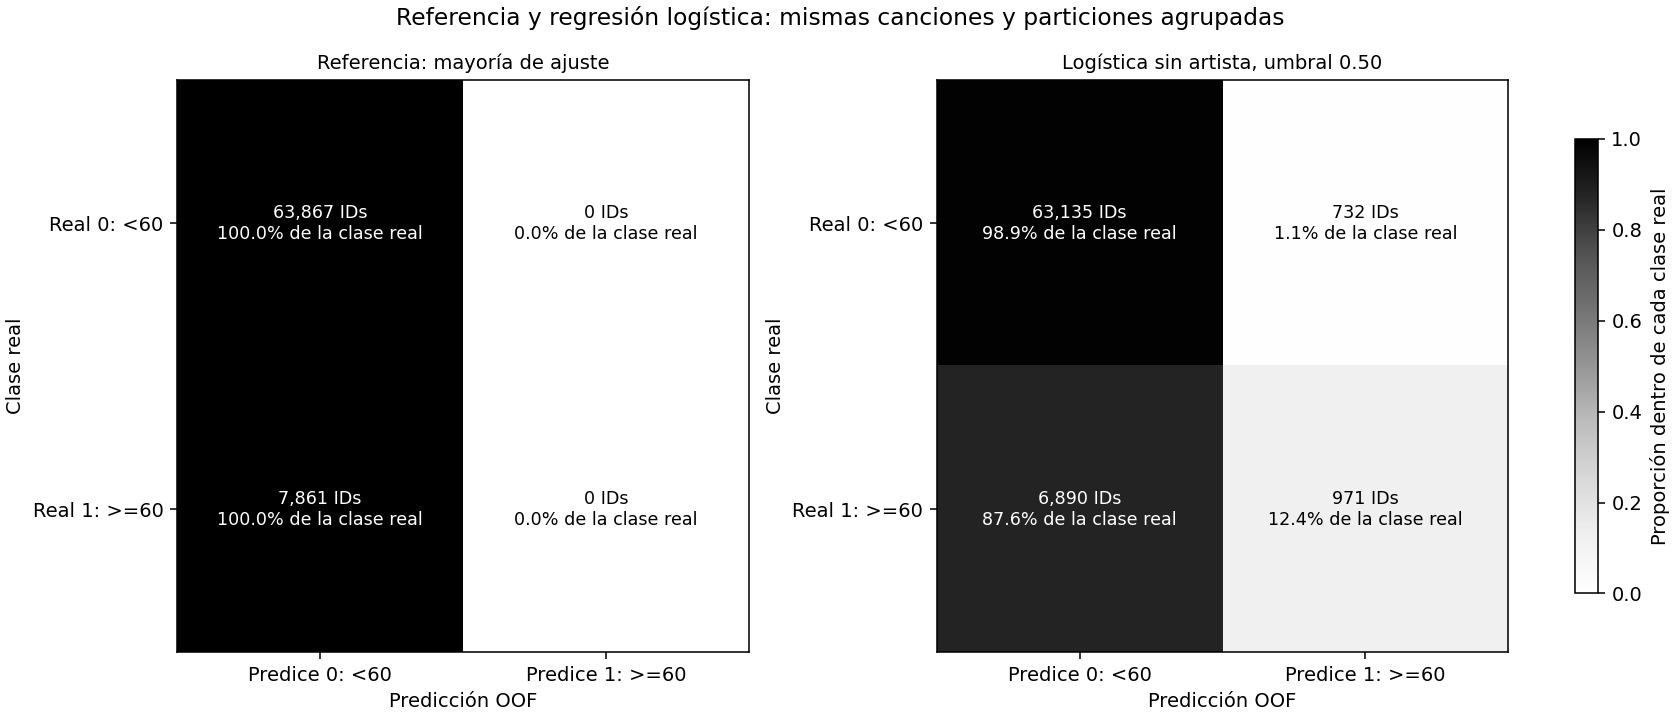

In [30]:
# Calcular métricas de la clase positiva con denominadores explícitos
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
import matplotlib.pyplot as plt

def resumir_clasificacion(real, pred):
    matriz = confusion_matrix(real, pred, labels=[0, 1])
    tn, fp, fn, tp = (int(valor) for valor in matriz.ravel())
    resumen = {"IDs": len(real), "TN": tn, "FP": fp, "FN": fn, "TP": tp, "Positivos predichos": tp + fp, "Precisión positiva definida": (tp + fp) > 0, "Precisión clase 1": precision_score(real, pred, pos_label=1, zero_division=0), "Recall clase 1": recall_score(real, pred, pos_label=1, zero_division=0), "F1 clase 1": f1_score(real, pred, pos_label=1, zero_division=0), "Accuracy": accuracy_score(real, pred)}
    assert int(matriz.sum()) == len(real)
    assert np.isclose(resumen["Recall clase 1"], tp / (tp + fn) if tp + fn else 0)
    assert np.isclose(resumen["Precisión clase 1"], tp / (tp + fp) if tp + fp else 0)
    assert np.isclose(resumen["F1 clase 1"], 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0)
    assert np.isclose(resumen["Accuracy"], (tn + tp) / len(real))
    return matriz, resumen

predicciones_clasificacion_oof = {"Referencia: mayoría de ajuste": predicciones_mayoria_oof, "Logística sin artista, umbral 0.50": predicciones_logistica_oof}
matrices_clasificacion_oof = {}
metricas_clasificacion_globales = []
metricas_clasificacion_por_ronda = []
for nombre, pred in predicciones_clasificacion_oof.items():
    assert pred.index.equals(y_clasificacion_train.index)
    matriz, resumen = resumir_clasificacion(y_clasificacion_train, pred)
    matrices_clasificacion_oof[nombre] = matriz
    metricas_clasificacion_globales.append({"Procedimiento": nombre, **resumen})
    display(pd.DataFrame(matriz, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(nombre))
    for ronda in range(numero_pliegues):
        validar_ronda = pliegue_por_id.eq(ronda)
        _, resumen_ronda = resumir_clasificacion(y_clasificacion_train.loc[validar_ronda], pred.loc[validar_ronda])
        metricas_clasificacion_por_ronda.append({"Procedimiento": nombre, "Ronda": ronda + 1, **resumen_ronda})
tabla_metricas_clasificacion_oof = pd.DataFrame(metricas_clasificacion_globales).set_index("Procedimiento")
tabla_metricas_clasificacion_ronda = pd.DataFrame(metricas_clasificacion_por_ronda).set_index(["Procedimiento", "Ronda"])
display(tabla_metricas_clasificacion_oof.round(4))
display(tabla_metricas_clasificacion_ronda.round(4))

# Mostrar cantidades y porcentajes por clase real en las dos matrices
fig_matrices_clasificacion, ejes_matrices_clasificacion = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for eje, (nombre, matriz) in zip(ejes_matrices_clasificacion, matrices_clasificacion_oof.items()):
    proporciones_fila = matriz / matriz.sum(axis=1, keepdims=True)
    imagen_matriz = eje.imshow(proporciones_fila, vmin=0, vmax=1, cmap="Greys")
    for fila in range(2):
        for columna in range(2):
            texto = f"{matriz[fila, columna]:,} IDs\n{proporciones_fila[fila, columna] * 100:.1f}% de la clase real"
            eje.text(columna, fila, texto, ha="center", va="center", color="white" if proporciones_fila[fila, columna] > 0.5 else "black", fontsize=9)
    eje.set_xticks([0, 1], ["Predice 0: <60", "Predice 1: >=60"])
    eje.set_yticks([0, 1], ["Real 0: <60", "Real 1: >=60"])
    eje.set_xlabel("Predicción OOF")
    eje.set_ylabel("Clase real")
    eje.set_title(nombre, fontsize=10)
fig_matrices_clasificacion.colorbar(imagen_matriz, ax=ejes_matrices_clasificacion, shrink=0.7, label="Proporción dentro de cada clase real")
fig_matrices_clasificacion.suptitle("Referencia y regresión logística: mismas canciones y particiones agrupadas")
display(fig_matrices_clasificacion)
plt.close(fig_matrices_clasificacion)


### Interpretar los resultados y comprobar los KPI iniciales

**Referencia:** en las tres rondas la clase más frecuente de ajuste fue 0. Sus predicciones globales son TN=63.867, FP=0, FN=7.861, TP=0. Tiene accuracy **89,04%**, pero recall positivo **0%** y F1 **0**. La precisión positiva es indefinida al no señalar positivos; la tabla la muestra como 0 mediante la convención declarada. No cumple el objetivo de identificar canciones de clase 1.

**Logística sin artista, umbral fijo 0,50:**

- **TP=971:** canciones de popularidad >=60 correctamente identificadas.
- **FN=6.890:** canciones de popularidad >=60 que no se detectaron.
- **FP=732:** canciones de popularidad <60 que se señalaron como positivas.
- **TN=63.135:** canciones de popularidad <60 correctamente reconocidas como negativas.
- De las **7.861** positivas reales, identifica **971**: recall **12,35%**.
- Señala **1.703** canciones; de ellas **971** cumplen: precisión **57,02%**.
- F1 positivo **0,2031** y accuracy **89,37%** describen aspectos distintos. No se comparan numéricamente con MAE, RMSE o R² de regresión porque son otra tarea y otra escala.

**Código del cierre, en orden:** se seleccionan las métricas de cada procedimiento, se comparan con las metas fijadas antes de entrenar y se calcula cobertura OOF mediante valores presentes y exactamente una visita por ID. Los resultados de recall y precisión se multiplican por 100 para mostrarlos en porcentaje; el F1 se mantiene entre 0 y 1. Se conserva la tabla de metas inicial y se crea una actualización para la logística. Un KPI que falle se marca «No cumple»; no se oculta ni se modifica su meta.

La cobertura de etiquetas y los controles de claves conservan su evidencia anterior. La precisión de referencia sin positivos no se considera definida por haber elegido `zero_division=0` en el reporte. El cuadro comparativo informa cuáles procedimientos cumplen ambos KPI predictivos; solo entre procedimientos que los cumplan se utilizaría F1 como criterio principal.

Los cinco ejemplos del código son las primeras observaciones, sin seleccionar aciertos ni errores llamativos. Muestran probabilidad estimada y etiqueta producida con 0,50; el código no busca otro umbral ni recalibra probabilidades.


In [31]:
# Contrastar cada procedimiento con las metas previamente fijadas
comparacion_kpi_clasificacion = tabla_metricas_clasificacion_oof[["Recall clase 1", "Precisión clase 1", "F1 clase 1", "Accuracy", "Precisión positiva definida"]].copy()
comparacion_kpi_clasificacion["Cumple recall >=60%"] = comparacion_kpi_clasificacion["Recall clase 1"].ge(meta_recall_clasificacion)
comparacion_kpi_clasificacion["Cumple precisión >=30%"] = comparacion_kpi_clasificacion["Precisión clase 1"].ge(meta_precision_clasificacion) & comparacion_kpi_clasificacion["Precisión positiva definida"]
comparacion_kpi_clasificacion["Cumple ambos KPI predictivos"] = comparacion_kpi_clasificacion["Cumple recall >=60%"] & comparacion_kpi_clasificacion["Cumple precisión >=30%"]
resultado_logistica = tabla_metricas_clasificacion_oof.loc["Logística sin artista, umbral 0.50"]
cobertura_oof_logistica = float((predicciones_logistica_oof.notna() & visitas_clasificacion_oof.eq(1)).mean() * 100)
tabla_kpi_logistica_oof = tabla_kpi_inicio_clasificacion.copy(deep=True)
for indicador, valor, cumple in [
    ("Recall clase 1", float(resultado_logistica["Recall clase 1"]) * 100, resultado_logistica["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", float(resultado_logistica["Precisión clase 1"]) * 100, bool(resultado_logistica["Precisión positiva definida"]) and resultado_logistica["Precisión clase 1"] >= meta_precision_clasificacion),
    ("Cobertura de predicciones OOF", cobertura_oof_logistica, np.isclose(cobertura_oof_logistica, 100))
]:
    tabla_kpi_logistica_oof.loc[indicador, "Resultado"] = valor
    tabla_kpi_logistica_oof.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"

ejemplos_logistica_oof = pd.DataFrame({"Clase real": y_clasificacion_train, "Referencia OOF": predicciones_mayoria_oof, "Probabilidad estimada clase 1": probabilidades_logistica_oof, "Etiqueta logística OOF": predicciones_logistica_oof})
display(comparacion_kpi_clasificacion.round(4))
display(tabla_kpi_logistica_oof.round({"Resultado": 4}))
display(ejemplos_logistica_oof.head(5).round(4))


,Recall clase 1,Precisión clase 1,F1 clase 1,Accuracy,Precisión positiva definida,Cumple recall >=60%,Cumple precisión >=30%,Cumple ambos KPI predictivos
Procedimiento,,,,,,,,
Referencia: mayoría de ajuste,0.0000,0.0000,0.0000,0.8904,False,False,False,False
"Logística sin artista, umbral 0.50",0.1235,0.5702,0.2031,0.8937,True,False,True,False


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,12.3521,%,No cumple
Precisión clase 1,>= 30%,57.0170,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


,Clase real,Referencia OOF,Probabilidad estimada clase 1,Etiqueta logística OOF
track_id,,,,
000CC8EParg64OmTxVnZ0p,0,0,0.0090,0
000Iz0K615UepwSJ5z2RE5,0,0,0.0205,0
000RDCYioLteXcutOjeweY,1,0,0.2946,0
000qpdoc97IMTBvF8gwcpy,0,0,0.0163,0
0017XiMkqbTfF2AUOzlhj6,0,0,0.0090,0


### Resultado inicial de clasificación con umbral fijo 0,50

La regresión logística mejora la identificación de la clase positiva respecto de la referencia, que no identifica ninguna. Con el umbral fijo 0,50, su recall es **12,35%**, precisión **57,02%** y F1 **0,2031**. La meta de recall **no cumple** y la de precisión **cumple**. **No cumple todavía ambas metas predictivas iniciales; se conserva el resultado sin cambiar la configuración.**

Las 71.728 canciones de entrenamiento tienen una predicción OOF, manteniendo las mismas tres particiones y sin compartir claves entre ajuste y validación. Los parámetros, las metas y el umbral no se modificaron en función del resultado. Se comenzó sin ponderar clases, sin remuestreo y sin artista para conservar una primera referencia comprensible.

Las métricas son de desarrollo interno: no demuestran causas, no garantizan identificación de futuros éxitos y no son una evaluación de clasificación en test. La prueba previamente evaluada para regresión no se consulta en este bloque.

**Continuidad:** analizar el efecto de la decisión 0,50 y del desbalance antes de añadir complejidad. Si después se estudian otros umbrales, ponderación o modelos, se hará dentro de entrenamiento con una comparación explícita y sin cambiar las metas para declarar éxito. El resultado inicial se conserva como evidencia.


El resultado anterior se conserva como referencia. A continuación se analiza el efecto de otros umbrales con las mismas probabilidades OOF.


### Análisis de umbrales con las probabilidades OOF de la logística

**Pregunta:** sin cambiar el modelo, ¿qué ocurre si exigimos otra probabilidad para señalar una canción como clase 1? Se reutilizan exactamente las probabilidades fuera de pliegue de las 71.728 canciones, obtenidas con las mismas tres particiones agrupadas. No hay nuevos ajustes del modelo, balanceo, características ni consulta de test.

**Se mantiene la respuesta real:** clase 1 sigue significando popularidad >=60. Solo se estudia la regla de decisión `probabilidad estimada >= umbral`. El umbral 0,20 significa exigir al menos una probabilidad estimada de 20%; no significa bajar la popularidad real a 20 ni garantizar 20% de precisión.

- Al **bajar** el umbral se señalan más canciones o la misma cantidad; TP y FP no disminuyen y los FN no aumentan. El recall no disminuye.
- Al **subirlo** se señalan menos canciones o la misma cantidad y el recall no aumenta. Puede haber menos falsas alarmas, pero se dejan fuera más canciones positivas.
- La **precisión no está garantizada como monótona** al variar el umbral en una muestra real. Hay que leer los resultados, sin prometer que cada aumento la mejore.
- F1 combina precisión y recall. El umbral de mayor F1 no necesariamente cumple el recall >=60% y precisión >=30% exigidos.

**Comparación fijada para este análisis:** umbrales 0; 0,05; 0,10; 0,15; 0,20; 0,25; 0,30; 0,35; 0,40; 0,45; 0,50; 0,60; 0,70; 0,80; 0,90 y 1. El cero ilustra señalar todas las canciones; el uno señala únicamente probabilidades estimadas iguales a 1, si las hubiera. Es una lista de trabajo, no una búsqueda de todos los valores posibles ni una prueba de optimalidad universal.

**Regla de decisión conservada:** se consideran elegibles solo los umbrales que cumplen **ambos** KPI predictivos globales. Entre ellos se compara F1 positivo. Si hay empate exacto de F1, se prefiere el umbral mayor como regla explícita de desempate; no implica superioridad demostrada. Si no hay elegibles, se informa que ninguno de los umbrales analizados cumple ambos; no se cambian metas ni se elige un incumplimiento como si fuera éxito.

**Alcance de esta selección:** cada probabilidad es OOF, pero el umbral provisional se elige mirando estas mismas etiquetas de entrenamiento. Sus métricas son de **desarrollo del umbral**, no una estimación independiente del procedimiento completo ya afinado. Para una confirmación adicional habría que separar la selección y la evaluación del umbral, por ejemplo con una validación interna adicional agrupada. No se utiliza test para resolverlo; ese conjunto ya fue observado en regresión.

**Código, en orden:**

1. `np.array` escribe la lista de umbrales antes de calcular sus métricas. Se comprueban índice, finitud y rango de las probabilidades OOF disponibles.
2. El bucle transforma las mismas probabilidades con `.ge(umbral).astype("int8")`. No llama a `.fit` ni a `.predict_proba`: el modelo y sus probabilidades no cambian.
3. `resumir_clasificacion` reutiliza la matriz y las fórmulas ya verificadas. Se añaden indicadores de cumplimiento con las metas originales, manteniendo la convención de precisión no definida cuando no se predicen positivos.
4. `pd.DataFrame` reúne una fila por umbral. La tabla mostrada multiplica precisión y recall por 100; F1 conserva su escala 0–1. Las métricas se calculan con precisión completa, sin redondear para decidir el cumplimiento.
5. Los controles de monotonía comprueban que aumentar el umbral no incremente cantidad de positivos ni recall. No se impone monotonía de precisión.
6. Se comprueba que el umbral 0,50 reproduzca exactamente las etiquetas y métricas de la logística anterior. Esto confirma que estamos cambiando solo la regla de decisión.


In [32]:
# Fijar los umbrales de trabajo y conservar las metas anteriores
umbrales_logistica = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00])
assert probabilidades_logistica_oof.index.equals(y_clasificacion_train.index)
assert np.isfinite(probabilidades_logistica_oof).all() and probabilidades_logistica_oof.between(0, 1).all()
assert np.isclose(meta_recall_clasificacion, 0.60) and np.isclose(meta_precision_clasificacion, 0.30)
registros_umbrales = []
for umbral in umbrales_logistica:
    etiquetas_umbral = probabilidades_logistica_oof.ge(umbral).astype("int8")
    _, resumen_umbral = resumir_clasificacion(y_clasificacion_train, etiquetas_umbral)
    cumple_recall_umbral = resumen_umbral["Recall clase 1"] >= meta_recall_clasificacion
    cumple_precision_umbral = resumen_umbral["Precisión positiva definida"] and resumen_umbral["Precisión clase 1"] >= meta_precision_clasificacion
    registros_umbrales.append({"Umbral": float(umbral), **resumen_umbral, "Cumple recall": bool(cumple_recall_umbral), "Cumple precisión": bool(cumple_precision_umbral), "Cumple ambos KPI": bool(cumple_recall_umbral and cumple_precision_umbral)})
tabla_umbrales_logistica = pd.DataFrame(registros_umbrales).set_index("Umbral").sort_index()
tabla_umbrales_lectura = tabla_umbrales_logistica[["Positivos predichos", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple precisión", "Cumple recall", "Cumple ambos KPI"]].copy()
tabla_umbrales_lectura["Precisión clase 1"] *= 100
tabla_umbrales_lectura["Recall clase 1"] *= 100
tabla_umbrales_lectura = tabla_umbrales_lectura.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)"})
assert tabla_umbrales_logistica["Positivos predichos"].diff().dropna().le(0).all()
assert tabla_umbrales_logistica["Recall clase 1"].diff().dropna().le(1e-12).all()
assert probabilidades_logistica_oof.ge(0.50).astype("int8").equals(predicciones_logistica_oof)
for metrica in ["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]:
    assert np.isclose(tabla_umbrales_logistica.loc[0.50, metrica], tabla_metricas_clasificacion_oof.loc["Logística sin artista, umbral 0.50", metrica])
display(tabla_umbrales_lectura.round(4))


,Positivos predichos,Precisión (%),Recall (%),F1 clase 1,Cumple precisión,Cumple recall,Cumple ambos KPI
Umbral,,,,,,,
0.00,71728,10.9595,100.0000,0.1975,False,True,False
0.05,35632,20.8941,94.7081,0.3424,False,True,False
0.10,27599,24.7183,86.7829,0.3848,False,True,False
0.15,19968,29.5072,74.9523,0.4234,False,True,False
0.20,13854,34.6759,61.1118,0.4425,True,True,True
0.25,9759,39.9221,49.5611,0.4422,True,False,False
0.30,6812,44.1867,38.2903,0.4103,True,False,False
0.35,4776,48.5553,29.5001,0.3670,True,False,False
0.40,3395,51.8704,22.4017,0.3129,True,False,False


### Selección provisional, matriz de confusión y resultados por ronda

**Código, en orden:**

1. Se filtran filas con `Cumple ambos KPI`. `.sort_values` ordena por F1 descendente y, solo ante empate exacto, por umbral descendente. Se guarda `None` si no hay elegibles; no se sustituye por un resultado que falle una meta.
2. También se muestra el umbral de mayor F1 **sin filtrar** para explicar si el mejor balance numérico coincide con los requisitos. Ese resultado no reemplaza la regla de selección.
3. Para 0,50 y el umbral provisional, si existe, se crean etiquetas a partir de las probabilidades OOF. Se imprimen sus matrices con filas reales y columnas predichas. El título distingue ambas reglas.
4. La comparación por ronda reutiliza `pliegue_por_id`: no vuelve a partir ni baraja canciones. Se muestran precisión, recall, F1 y cumplimiento con cada umbral en las mismas rondas. Los KPI se definieron sobre el resultado global; posibles incumplimientos por ronda se informan como variación y no se esconden.
5. La tabla de KPI del umbral provisional copia la evidencia anterior y actualiza únicamente las métricas que cambiaron con la regla. Si no existe elegible, no se declara una selección cumplidora ni se sustituyen los pendientes por un éxito.
6. La cobertura vuelve a verificar una etiqueta por cada ID. No se modifican probabilidades, modelos ni etiquetas reales.

**Importante:** reducir el umbral puede recuperar canciones positivas y añadir simultáneamente falsas alarmas. La explicación debe comparar **TP, FN y FP**, no solo celebrar el aumento de recall. La distribución minoritaria de clase 1 y la separación imperfecta de las probabilidades condicionan esa compensación, pero estas cifras no identifican por sí solas una causa musical o social.


In [33]:
# Aplicar la regla de elección sin cambiar los KPI
elegibles_umbrales = tabla_umbrales_logistica.reset_index().loc[lambda tabla: tabla["Cumple ambos KPI"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
mejor_f1_sin_restriccion = tabla_umbrales_logistica.reset_index().sort_values(["F1 clase 1", "Umbral"], ascending=[False, False]).iloc[0]
umbral_provisional_logistica = None if elegibles_umbrales.empty else float(elegibles_umbrales.iloc[0]["Umbral"])
display(elegibles_umbrales[["Umbral", "Precisión clase 1", "Recall clase 1", "F1 clase 1"]].round(4))
display(mejor_f1_sin_restriccion[["Umbral", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple ambos KPI"]])

# Conservar 0,50 como referencia y comparar el provisional, si existe
umbrales_detalle = [0.50]
if umbral_provisional_logistica is not None and not np.isclose(umbral_provisional_logistica, 0.50):
    umbrales_detalle.append(umbral_provisional_logistica)
registros_umbrales_por_ronda = []
for umbral in umbrales_detalle:
    pred_detalle = probabilidades_logistica_oof.ge(umbral).astype("int8")
    matriz_detalle, _ = resumir_clasificacion(y_clasificacion_train, pred_detalle)
    display(pd.DataFrame(matriz_detalle, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(f"OOF: umbral {umbral:.2f}"))
    for ronda in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(ronda)
        _, resumen_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred_detalle.loc[en_ronda])
        registros_umbrales_por_ronda.append({"Umbral": umbral, "Ronda": ronda + 1, "IDs": int(en_ronda.sum()), "Precisión (%)": resumen_ronda["Precisión clase 1"] * 100, "Recall (%)": resumen_ronda["Recall clase 1"] * 100, "F1": resumen_ronda["F1 clase 1"], "Cumple ambos KPI": resumen_ronda["Precisión positiva definida"] and resumen_ronda["Precisión clase 1"] >= meta_precision_clasificacion and resumen_ronda["Recall clase 1"] >= meta_recall_clasificacion})
tabla_umbrales_por_ronda = pd.DataFrame(registros_umbrales_por_ronda).set_index(["Umbral", "Ronda"])
display(tabla_umbrales_por_ronda.round(4))

# Actualizar evidencia del umbral elegido, si cumple las dos metas globales
tabla_kpi_umbral_provisional = None
predicciones_umbral_provisional_oof = None
if umbral_provisional_logistica is None:
    display("Ningún umbral de la lista cumple ambas metas. No se elige un umbral cumplidor ni se cambian los KPI.")
else:
    fila_provisional = tabla_umbrales_logistica.loc[umbral_provisional_logistica]
    predicciones_umbral_provisional_oof = probabilidades_logistica_oof.ge(umbral_provisional_logistica).astype("int8")
    assert predicciones_umbral_provisional_oof.index.equals(y_clasificacion_train.index)
    assert len(predicciones_umbral_provisional_oof) == len(y_clasificacion_train) and predicciones_umbral_provisional_oof.isin([0, 1]).all()
    tabla_kpi_umbral_provisional = tabla_kpi_logistica_oof.copy(deep=True)
    tabla_kpi_umbral_provisional.loc["Recall clase 1", "Resultado"] = float(fila_provisional["Recall clase 1"]) * 100
    tabla_kpi_umbral_provisional.loc["Precisión clase 1", "Resultado"] = float(fila_provisional["Precisión clase 1"]) * 100
    tabla_kpi_umbral_provisional.loc["Recall clase 1", "Estado"] = "Cumple" if fila_provisional["Cumple recall"] else "No cumple"
    tabla_kpi_umbral_provisional.loc["Precisión clase 1", "Estado"] = "Cumple" if fila_provisional["Cumple precisión"] else "No cumple"
    tabla_kpi_umbral_provisional.loc["Cobertura de predicciones OOF", "Resultado"] = float(predicciones_umbral_provisional_oof.notna().mean() * 100)
    display(tabla_kpi_umbral_provisional.round({"Resultado": 4}))


,Umbral,Precisión clase 1,Recall clase 1,F1 clase 1
4,0.2,0.3468,0.6111,0.4425


Umbral                    0.2
Precisión clase 1    0.346759
Recall clase 1       0.611118
F1 clase 1           0.442459
Cumple ambos KPI         True
Name: 4, dtype: object

,Predice 0: <60,Predice 1: >=60
OOF: umbral 0.50,,
Real 0: <60,63135,732
Real 1: >=60,6890,971


,Predice 0: <60,Predice 1: >=60
OOF: umbral 0.20,,
Real 0: <60,54817,9050
Real 1: >=60,3057,4804


IDs  Precisión (%)  Recall (%)      F1  Cumple ambos KPI
Umbral Ronda                                                            
0.5    1      23913        56.9748     12.6919  0.2076             False
       2      24104        53.9936     12.9254  0.2086             False
       3      23711        60.9959     11.4175  0.1923             False
0.2    1      23913        35.0122     59.0790  0.4397             False
       2      24104        33.5918     62.9446  0.4381              True
       3      23711        35.5296     61.3592  0.4500              True

,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,61.1118,%,Cumple
Precisión clase 1,>= 30%,34.6759,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


### Visualizar el efecto del umbral

El panel izquierdo compara precisión y recall; las líneas horizontales indican metas diferentes. El derecho muestra F1 y marca los umbrales elegibles. La línea vertical de 0,50 conserva la regla inicial; si existe una selección provisional se identifica aparte.

**Lectura del código:** `plt.subplots` crea dos paneles. `.plot` conecta únicamente los umbrales calculados; las líneas no prueban el resultado de todos los valores intermedios. `axhline` representa las metas y `axvline` los umbrales de referencia. `scatter` destaca los valores que cumplen ambas metas. Los ejes van de 0 a 1 y los títulos recuerdan qué representa cada escala. `legend` identifica líneas y marcadores; `display` inserta el gráfico y `close` libera la figura.

Los umbrales 0 y 1 ayudan a leer los extremos, pero en ausencia de predicciones positivas la precisión no está definida: se muestra como 0 por convención y debe interpretarse con el conteo de positivos. El gráfico no valida calibración de probabilidades ni demuestra qué ocurrirá en canciones nuevas.


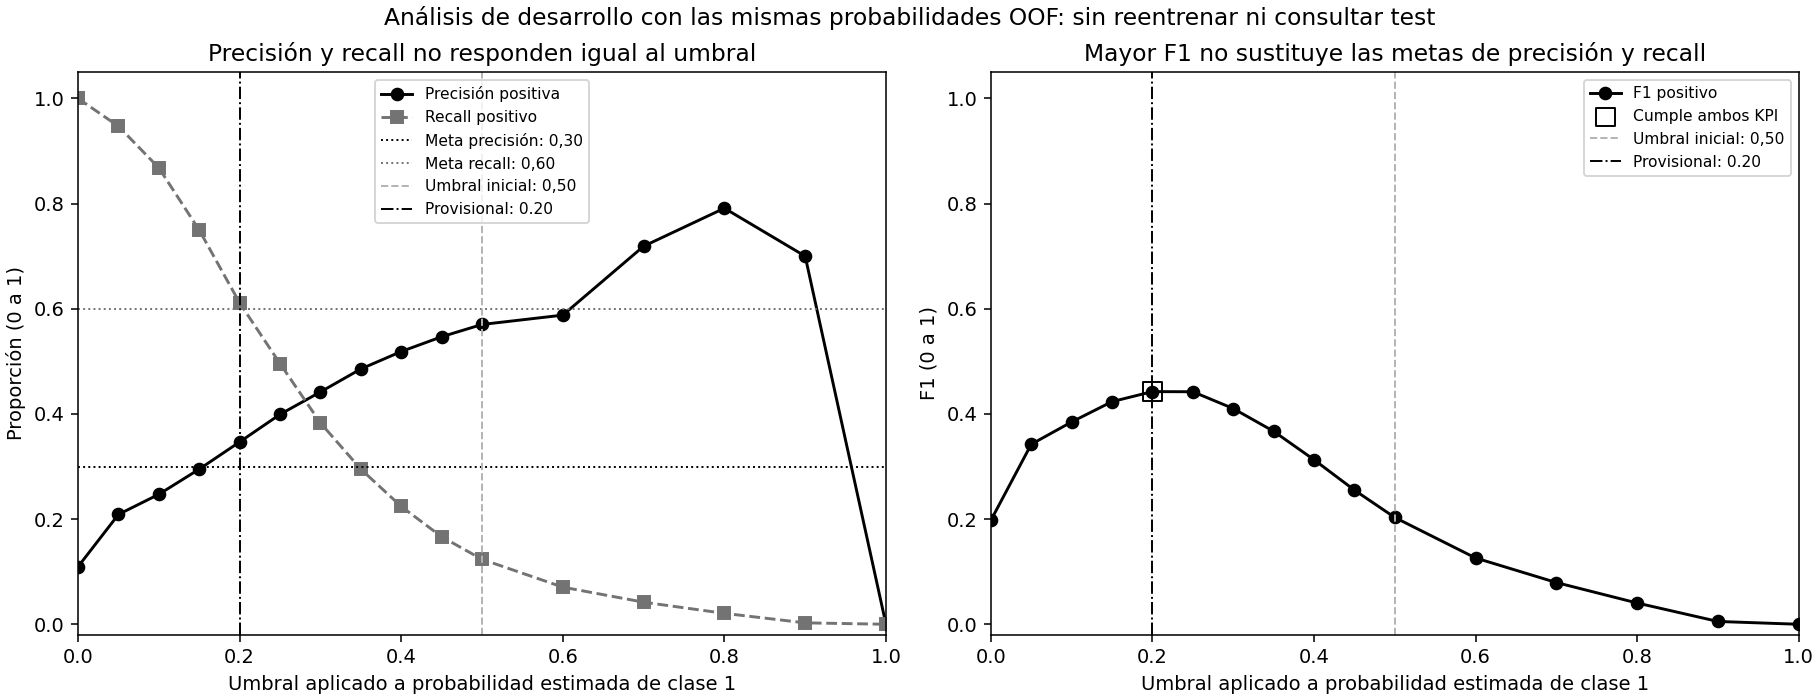

In [34]:
# Dibujar la compensación entre métricas con el modelo y sus probabilidades fijos
import matplotlib.pyplot as plt
fig_umbrales, ejes_umbrales = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
ejes_umbrales[0].plot(tabla_umbrales_logistica.index, tabla_umbrales_logistica["Precisión clase 1"], color="black", marker="o", label="Precisión positiva")
ejes_umbrales[0].plot(tabla_umbrales_logistica.index, tabla_umbrales_logistica["Recall clase 1"], color="0.45", linestyle="--", marker="s", label="Recall positivo")
ejes_umbrales[0].axhline(meta_precision_clasificacion, color="black", linestyle=":", linewidth=1, label="Meta precisión: 0,30")
ejes_umbrales[0].axhline(meta_recall_clasificacion, color="0.45", linestyle=":", linewidth=1, label="Meta recall: 0,60")
ejes_umbrales[0].set_title("Precisión y recall no responden igual al umbral")
ejes_umbrales[0].set_ylabel("Proporción (0 a 1)")
ejes_umbrales[1].plot(tabla_umbrales_logistica.index, tabla_umbrales_logistica["F1 clase 1"], color="black", marker="o", label="F1 positivo")
filas_elegibles = tabla_umbrales_logistica.loc[tabla_umbrales_logistica["Cumple ambos KPI"]]
ejes_umbrales[1].scatter(filas_elegibles.index, filas_elegibles["F1 clase 1"], marker="s", s=90, facecolors="none", edgecolors="black", label="Cumple ambos KPI")
ejes_umbrales[1].set_title("Mayor F1 no sustituye las metas de precisión y recall")
ejes_umbrales[1].set_ylabel("F1 (0 a 1)")
for eje in ejes_umbrales:
    eje.axvline(0.50, color="0.7", linestyle="--", linewidth=1, label="Umbral inicial: 0,50")
    if umbral_provisional_logistica is not None:
        eje.axvline(umbral_provisional_logistica, color="black", linestyle="-.", linewidth=1, label=f"Provisional: {umbral_provisional_logistica:.2f}")
    eje.set_xlim(0, 1)
    eje.set_ylim(-0.02, 1.05)
    eje.set_xlabel("Umbral aplicado a probabilidad estimada de clase 1")
    eje.legend(fontsize=8)
fig_umbrales.suptitle("Análisis de desarrollo con las mismas probabilidades OOF: sin reentrenar ni consultar test")
display(fig_umbrales)
plt.close(fig_umbrales)


### Resultados, cumplimiento y explicación de los incumplimientos

**Selección provisional entre los umbrales analizados: 0,20.** Precisión **34,68%**, recall **61,11%** y F1 **0,4425**. Cumple las dos metas globales y tiene el mayor F1 entre los elegibles de esta lista. Los umbrales elegibles fueron **0,20**.

- **Umbral 0,50: no cumple ambos KPI.** recall 12,35% <60%: detecta 971 positivas y deja 6.890 sin detectar.
- **Umbral 0,05: no cumple ambos KPI.** precisión 20,89% <30%: hay 28.187 falsas alarmas entre 35.632 canciones señaladas.
- **Umbral 1,00: no cumple ambos KPI.** recall 0,00% <60%: detecta 0 positivas y deja 7.861 sin detectar; precisión no definida al no señalar ninguna positiva; el cero de reporte no representa una precisión estimada.

Al pasar de 0,50 a 0,20, se identifican **4.804** positivas reales en lugar de **971**; los FN pasan de **6.890 a 3.057**. A cambio, los FP pasan de **732 a 9.050**. Se señalan **13.854** canciones en total: mejor recall implica revisar más canciones y aceptar más falsas alarmas en este caso.

**Otros incumplimientos cercanos:** con umbral 0,15, recall=74,95% cumple, pero precisión=29,51% <30% **no cumple**; señalar más canciones incorpora demasiadas falsas alarmas para esa meta. Con umbral 0,25, precisión=39,92% cumple, pero recall=49,56% <60% **no cumple**; la regla deja fuera más de la mitad de las positivas reales.

**Costo de la selección 0,20:** el 65,32% de las canciones señaladas no cumple el corte real de popularidad. Ese porcentaje usa como denominador las canciones señaladas, no todas las negativas reales. Cumplir una meta inicial de precisión del 30% no elimina esta carga de revisión ni garantiza que sea aceptable en un uso real.

**Por qué pasa:** el umbral controla cuántas canciones se aceptan como positivas sobre un orden de probabilidades que no separa perfectamente ambas clases. Una regla exigente como 0,50 deja fuera muchas canciones de clase 1; una regla permisiva puede recuperar más positivas a costa de numerosas falsas alarmas. Los conteos permiten demostrar esta compensación. No se puede concluir solo con ellos que una variable específica o el desbalance sean la causa de cada error.

Con el umbral provisional, **no todas las rondas cumplen ambos KPI**, aunque el conjunto OOF global sí. Fallan las rondas **1**. **En la ronda 1, recall=59,08% <60%: no cumple ese KPI**, aunque precisión=35,01% sí supera 30%. Las rondas 2 y 3 cumplen ambas metas. La variación entre particiones permanece como limitación; no se redondea 59,08% a un cumplimiento.

Se conservaron el corte real de popularidad en 60, las metas de recall >=60% y precisión >=30%, las probabilidades, las características, los modelos por ronda y las particiones. Cambió únicamente el umbral de decisión. El cumplimiento se describe en desarrollo con probabilidades OOF; **el umbral se eligió con estas mismas respuestas y todavía requiere una comprobación independiente de esa elección**. No se presenta como resultado de clasificación en test ni se utiliza la evaluación de regresión para confirmarlo.

Si ningún umbral analizado cumpliera ambas metas, la conclusión sería incumplimiento de esta lista de trabajo, explicando qué métrica limita la decisión; no que sea imposible con cualquier umbral o modelo. No se amplía la lista automáticamente para buscar un éxito ni se reducen metas después de ver los resultados.


### Validación adicional: separar la elección del umbral de su evaluación

El umbral 0,20 cumplió los KPI globales al compararlo con las mismas etiquetas OOF utilizadas para escogerlo. Ahora se comprueba **el procedimiento de seleccionar un umbral** sin permitir que las respuestas que lo evalúan elijan ese umbral.

Se conservan las **tres particiones externas agrupadas existentes**. Dentro del ajuste de cada ronda se crean otras **tres particiones internas**, también agrupadas por la misma clave artista + título. Esta organización se llama **validación anidada**: un nivel elige y otro evalúa.

**Ejemplo de la ronda externa 1:**

1. Sus 23.913 IDs de validación externa quedan fuera de la elección del umbral.
2. Solo los 47.815 IDs de su ajuste externo se subdividen internamente. En cada ronda interna se aprende imputación, escalamiento, categorías y logística con ajuste interno y se predice validación interna.
3. Se reúnen esas probabilidades OOF internas y se comparan los **mismos 16 umbrales**. Se mantienen recall >=60%, precisión >=30%, mayor F1 entre elegibles y desempate por umbral mayor.
4. El umbral se fija con esos datos internos. Después se aplica a la probabilidad de cada ID de validación externa, que ya procede de una logística entrenada solo con el ajuste externo.
5. Se repite para las otras dos rondas externas. Cada ID de entrenamiento recibe una sola etiqueta externa, con un umbral que no se seleccionó con su respuesta.

**Reutilización correcta de probabilidades externas:** las probabilidades guardadas de la primera logística se obtuvieron exactamente con esos mismos ajustes externos, preparación y parámetros. Se reutilizan para no repetir tres ajustes idénticos; nunca entran junto con sus respuestas en la elección interna. Los nueve ajustes nuevos son los tres internos de cada una de las tres rondas externas. Un umbral puede ser distinto en cada ronda: se evalúa el procedimiento de selección, no un 0,20 universal fijado a posteriori.

**Regla explícita si no hay umbral interno elegible:** se registra que la selección interna no encontró uno que cumpla ambas metas y se conserva **0,50 como regla de respaldo** para poder evaluar todos los IDs. No se presenta ese respaldo como un umbral cumplidor ni se cambia la meta. Esta política se fija antes de obtener los resultados externos; evita ocultar rondas difíciles o calcular métricas solo con los casos favorables.

**Lectura del código:**

- `seleccionar_umbral_interno` recibe únicamente X, etiquetas y claves del ajuste externo, la plantilla y las reglas ya fijadas. No recibe respuestas ni probabilidades de validación externa.
- Se ordenan y barajan las claves internas con semilla 42; repartir posiciones módulo 3 mantiene juntas sus versiones. No se utiliza popularidad para decidir el reparto.
- Cada ajuste interno clona el pipeline completo. `.fit` aprende solo del ajuste interno; `.predict_proba` obtiene probabilidades de su validación interna. Se revisan convergencia, medianas, escalador, ambas clases y separación de claves.
- La Serie de visitas comprueba una validación interna por ID. Después, cada umbral transforma las probabilidades internas; las métricas se calculan con las etiquetas internas. El orden de elegibilidad, F1 y desempate conserva la regla anterior.
- El bucle externo llama a la función con `~validar_externo`, fija el umbral y **solo después** aplica la regla a las probabilidades externas ya guardadas. Las etiquetas externas reales se consultan para evaluar en la celda siguiente.
- Los diccionarios conservan tablas internas y sus probabilidades como evidencia. La tabla de selección muestra umbral usado, si hubo elegibles, motivo y métricas internas. Las métricas internas sirven para elegir, no se presentan como resultado externo.
- Los controles de cobertura verifican exactamente una predicción externa por ID y la validez de las probabilidades externas reutilizadas. No se mezcla ajuste interno con validación externa ni se entrenan nuevos modelos sobre test.

**Alcance:** esta separación controla el uso de etiquetas en la elección del umbral para cada ronda. El dataset y las validaciones externas ya se habían examinado durante el desarrollo; por tanto, esto es una validación interna adicional con un protocolo más estricto, **no una muestra inédita o una prueba externa completamente independiente**. No se ajustan C, balanceo, metas o lista de umbrales al observar estos resultados.

Referencia conceptual: [validación anidada y no anidada, scikit-learn](https://scikit-learn.org/1.6/auto_examples/model_selection/plot_nested_cross_validation_iris.html).


In [35]:
# Elegir el umbral solo con las etiquetas y probabilidades del ajuste externo
numero_pliegues_internos_umbral = 3
umbral_respaldo_anidado = 0.50

def seleccionar_umbral_interno(X_ajuste_externo, y_ajuste_externo, claves_ajuste_externo, plantilla, umbrales, meta_recall, meta_precision):
    assert X_ajuste_externo.index.equals(y_ajuste_externo.index)
    assert claves_ajuste_externo.index.equals(y_ajuste_externo.index)
    claves_internas = claves_ajuste_externo.drop_duplicates().sort_values().sample(frac=1, random_state=42).reset_index(drop=True)
    mapa_interno = pd.Series(np.arange(len(claves_internas)) % 3, index=claves_internas)
    pliegue_interno = claves_ajuste_externo.map(mapa_interno)
    probabilidades_internas = pd.Series(index=y_ajuste_externo.index, dtype="float64")
    visitas_internas = pd.Series(0, index=y_ajuste_externo.index, dtype="int8")
    controles_internos = []
    for ronda_interna in range(3):
        validar_interno = pliegue_interno.eq(ronda_interna)
        ajustar_interno = ~validar_interno
        claves_compartidas = set(claves_ajuste_externo.loc[ajustar_interno]) & set(claves_ajuste_externo.loc[validar_interno])
        assert len(claves_compartidas) == 0
        assert y_ajuste_externo.loc[ajustar_interno].nunique() == 2 and y_ajuste_externo.loc[validar_interno].nunique() == 2
        modelo_interno = clone(plantilla)
        with warnings.catch_warnings(record=True) as avisos_internos:
            warnings.simplefilter("always", ConvergenceWarning)
            modelo_interno.fit(X_ajuste_externo.loc[ajustar_interno], y_ajuste_externo.loc[ajustar_interno])
        if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos_internos):
            raise ValueError("Revisar convergencia interna antes de elegir el umbral.")
        clasificador_interno = modelo_interno.named_steps["clasificar"]
        columna_positiva = list(clasificador_interno.classes_).index(1)
        probabilidades_internas.loc[validar_interno] = modelo_interno.predict_proba(X_ajuste_externo.loc[validar_interno])[:, columna_positiva]
        visitas_internas.loc[validar_interno] += 1
        bloque_numerico = modelo_interno.named_steps["preparar"].named_transformers_["numericas"]
        assert np.allclose(bloque_numerico.named_steps["imputar"].statistics_, X_ajuste_externo.loc[ajustar_interno, columnas_numericas_modelo].median())
        assert int(bloque_numerico.named_steps["escalar"].n_samples_seen_) == int(ajustar_interno.sum())
        assert int(clasificador_interno.n_iter_[0]) < 2000
        controles_internos.append({"Ronda interna": ronda_interna + 1, "IDs ajuste interno": int(ajustar_interno.sum()), "IDs validación interna": int(validar_interno.sum()), "Claves compartidas internas": len(claves_compartidas), "Iteraciones": int(clasificador_interno.n_iter_[0])})
    assert visitas_internas.eq(1).all() and probabilidades_internas.notna().all()
    assert np.isfinite(probabilidades_internas).all() and probabilidades_internas.between(0, 1).all()
    filas_umbrales = []
    for umbral in umbrales:
        _, metricas = resumir_clasificacion(y_ajuste_externo, probabilidades_internas.ge(umbral).astype("int8"))
        elegible = metricas["Precisión positiva definida"] and metricas["Precisión clase 1"] >= meta_precision and metricas["Recall clase 1"] >= meta_recall
        filas_umbrales.append({"Umbral": float(umbral), **metricas, "Elegible interno": bool(elegible)})
    tabla_interna = pd.DataFrame(filas_umbrales).set_index("Umbral")
    elegibles = tabla_interna.reset_index().loc[lambda tabla: tabla["Elegible interno"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
    if elegibles.empty:
        umbral_usado = 0.50
        motivo = "Ningún umbral interno cumple ambos KPI; respaldo fijo 0,50"
    else:
        umbral_usado = float(elegibles.iloc[0]["Umbral"])
        motivo = "Mayor F1 interno entre umbrales que cumplen ambos KPI"
    return umbral_usado, not elegibles.empty, motivo, tabla_interna, pd.DataFrame(controles_internos), probabilidades_internas

# Mantener las mismas tres rondas externas y reutilizar sus probabilidades OOF
assert probabilidades_logistica_oof.index.equals(y_clasificacion_train.index)
assert np.isfinite(probabilidades_logistica_oof).all()
predicciones_umbral_anidado_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64")
umbral_asignado_por_id = pd.Series(index=y_clasificacion_train.index, dtype="float64")
visitas_externas_anidadas = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
selecciones_anidadas = []
controles_ajustes_internos = []
evidencia_interna_por_ronda = {}

for ronda_externa in range(numero_pliegues):
    validar_externo = pliegue_por_id.eq(ronda_externa)
    ajustar_externo = ~validar_externo
    claves_ajuste_externo = datos_entrenamiento.loc[ajustar_externo, "clave_cancion"]
    assert set(claves_ajuste_externo).isdisjoint(set(datos_entrenamiento.loc[validar_externo, "clave_cancion"]))
    umbral_usado, hubo_elegible, motivo, tabla_interna, controles_internos, prob_internas = seleccionar_umbral_interno(X_train.loc[ajustar_externo], y_clasificacion_train.loc[ajustar_externo], claves_ajuste_externo, modelo_logistico_base, umbrales_logistica, meta_recall_clasificacion, meta_precision_clasificacion)
    evidencia_interna_por_ronda[ronda_externa + 1] = {"Tabla de umbrales internos": tabla_interna, "Probabilidades internas": prob_internas}
    fila_interna = tabla_interna.loc[umbral_usado]
    selecciones_anidadas.append({"Ronda externa": ronda_externa + 1, "IDs ajuste externo": int(ajustar_externo.sum()), "IDs validación externa": int(validar_externo.sum()), "Umbral usado": umbral_usado, "Hubo umbral interno elegible": hubo_elegible, "Precisión interna (%)": fila_interna["Precisión clase 1"] * 100, "Recall interno (%)": fila_interna["Recall clase 1"] * 100, "F1 interno": fila_interna["F1 clase 1"], "Motivo": motivo})
    controles_internos["Ronda externa"] = ronda_externa + 1
    controles_ajustes_internos.append(controles_internos)
    predicciones_umbral_anidado_oof.loc[validar_externo] = probabilidades_logistica_oof.loc[validar_externo].ge(umbral_usado).astype("int8")
    umbral_asignado_por_id.loc[validar_externo] = umbral_usado
    visitas_externas_anidadas.loc[validar_externo] += 1
assert visitas_externas_anidadas.eq(1).all()
assert predicciones_umbral_anidado_oof.notna().all() and predicciones_umbral_anidado_oof.isin([0, 1]).all()
predicciones_umbral_anidado_oof = predicciones_umbral_anidado_oof.astype("int8")
tabla_seleccion_anidada = pd.DataFrame(selecciones_anidadas).set_index("Ronda externa")
tabla_controles_ajustes_internos = pd.concat(controles_ajustes_internos, ignore_index=True).set_index(["Ronda externa", "Ronda interna"])
display(tabla_seleccion_anidada.round(4))
display(tabla_controles_ajustes_internos)


,IDs ajuste externo,IDs validación externa,Umbral usado,Hubo umbral interno elegible,Precisión interna (%),Recall interno (%),F1 interno,Motivo
Ronda externa,,,,,,,,
1,47815,23913,0.2,True,35.0493,60.2119,0.4431,Mayor F1 interno entre umbrales que cumplen am...
2,47624,24104,0.2,True,34.9546,61.6470,0.4461,Mayor F1 interno entre umbrales que cumplen am...
3,48017,23711,0.2,True,34.3919,60.0265,0.4373,Mayor F1 interno entre umbrales que cumplen am...


IDs ajuste interno  ...  Iteraciones
Ronda externa Ronda interna                      ...             
1             1                           31862  ...          152
              2                           31854  ...          160
              3                           31914  ...          159
2             1                           31821  ...          147
              2                           31752  ...          169
              3                           31675  ...          159
3             1                           32108  ...          159
              2                           32047  ...          159
              3                           31879  ...          153

[9 rows x 4 columns]

### Evaluar únicamente después de fijar el umbral de cada ronda

Ahora sí se comparan las etiquetas externas predichas con las respuestas de su validación externa. Se reúnen las 71.728 observaciones para la matriz global y se muestran las tres rondas por separado.

**Código, en orden:**

1. `resumir_clasificacion` calcula TN, FP, FN, TP y métricas con las predicciones externas del procedimiento anidado. La matriz mantiene filas reales y columnas predichas.
2. El reporte por ronda usa su umbral seleccionado internamente y comprueba las mismas metas. La coincidencia o diferencia entre umbrales no se altera después de mirar estas métricas.
3. La tabla de comparación distingue tres alcances: 0,50 fijo antes de buscar, 0,20 escogido con todas las etiquetas OOF y el procedimiento de selección interna evaluado externamente. No son tres modelos distintos: usan la misma configuración de logística y diferentes protocolos de decisión.
4. La tabla de KPI se copia y se actualiza con las métricas anidadas. Recall y precisión se muestran en porcentaje; F1 conserva escala 0–1. La cobertura exige una predicción externa por ID. Los controles de etiquetas y claves mantienen su evidencia.
5. Si falla una meta, se informa «No cumple». Que el umbral global anterior cumpliera no obliga al protocolo más estricto a cumplir. La tabla interna explica si hubo alguna ronda sin candidato elegible; el respaldo 0,50 permanece visible.

**Qué se está validando:** la capacidad del proceso «aprender logística y elegir umbral con datos internos» para trasladarse a otras canciones de la misma partición de entrenamiento. No se confirma un umbral único para todo uso ni se crea un clasificador final con todo el entrenamiento. El resultado global no es el promedio simple de precisión, recall o F1 de las rondas.


In [36]:
# Calcular la matriz global con predicciones externas del procedimiento anidado
matriz_umbral_anidado, resumen_umbral_anidado = resumir_clasificacion(y_clasificacion_train, predicciones_umbral_anidado_oof)
display(pd.DataFrame(matriz_umbral_anidado, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis("Selección interna de umbral: evaluación externa"))
registros_evaluacion_anidada = []
for ronda_externa in range(numero_pliegues):
    en_externa = pliegue_por_id.eq(ronda_externa)
    _, metricas_externas = resumir_clasificacion(y_clasificacion_train.loc[en_externa], predicciones_umbral_anidado_oof.loc[en_externa])
    registros_evaluacion_anidada.append({"Ronda externa": ronda_externa + 1, "Umbral usado": float(tabla_seleccion_anidada.loc[ronda_externa + 1, "Umbral usado"]), "IDs": int(en_externa.sum()), "TP": metricas_externas["TP"], "FN": metricas_externas["FN"], "FP": metricas_externas["FP"], "Precisión (%)": metricas_externas["Precisión clase 1"] * 100, "Recall (%)": metricas_externas["Recall clase 1"] * 100, "F1": metricas_externas["F1 clase 1"], "Cumple precisión": bool(metricas_externas["Precisión positiva definida"] and metricas_externas["Precisión clase 1"] >= meta_precision_clasificacion), "Cumple recall": bool(metricas_externas["Recall clase 1"] >= meta_recall_clasificacion)})
tabla_evaluacion_anidada = pd.DataFrame(registros_evaluacion_anidada).set_index("Ronda externa")

# Comparar alcances de evaluación, sin elegir otro protocolo por su resultado
fila_inicial = tabla_metricas_clasificacion_oof.loc["Logística sin artista, umbral 0.50"]
fila_global_020 = tabla_umbrales_logistica.loc[0.20]
comparacion_protocolos_umbral = pd.DataFrame([
    {"Protocolo": "0,50 fijado antes del análisis", "Precisión (%)": fila_inicial["Precisión clase 1"] * 100, "Recall (%)": fila_inicial["Recall clase 1"] * 100, "F1": fila_inicial["F1 clase 1"], "Alcance": "Predicciones OOF con umbral inicial fijo"},
    {"Protocolo": "0,20 escogido con etiquetas OOF globales", "Precisión (%)": fila_global_020["Precisión clase 1"] * 100, "Recall (%)": fila_global_020["Recall clase 1"] * 100, "F1": fila_global_020["F1 clase 1"], "Alcance": "Desarrollo del umbral sobre etiquetas utilizadas para escogerlo"},
    {"Protocolo": "Selección interna y evaluación externa agrupadas", "Precisión (%)": resumen_umbral_anidado["Precisión clase 1"] * 100, "Recall (%)": resumen_umbral_anidado["Recall clase 1"] * 100, "F1": resumen_umbral_anidado["F1 clase 1"], "Alcance": "Validación interna adicional con elección y evaluación separadas"}
]).set_index("Protocolo")
tabla_kpi_umbral_anidado = tabla_kpi_logistica_oof.copy(deep=True)
for indicador, valor, cumple in [
    ("Recall clase 1", resumen_umbral_anidado["Recall clase 1"] * 100, resumen_umbral_anidado["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", resumen_umbral_anidado["Precisión clase 1"] * 100, resumen_umbral_anidado["Precisión positiva definida"] and resumen_umbral_anidado["Precisión clase 1"] >= meta_precision_clasificacion),
    ("Cobertura de predicciones OOF", float(visitas_externas_anidadas.eq(1).mean() * 100), visitas_externas_anidadas.eq(1).all())
]:
    tabla_kpi_umbral_anidado.loc[indicador, "Resultado"] = valor
    tabla_kpi_umbral_anidado.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"
assert int(matriz_umbral_anidado.sum()) == len(y_clasificacion_train)
assert np.isclose(resumen_umbral_anidado["Recall clase 1"], tabla_evaluacion_anidada["TP"].sum() / (tabla_evaluacion_anidada["TP"].sum() + tabla_evaluacion_anidada["FN"].sum()))
display(pd.Series(resumen_umbral_anidado))
display(tabla_evaluacion_anidada.round(4))
display(comparacion_protocolos_umbral.round(4))
display(tabla_kpi_umbral_anidado.round({"Resultado": 4}))


,Predice 0: <60,Predice 1: >=60
Selección interna de umbral: evaluación externa,,
Real 0: <60,54817,9050
Real 1: >=60,3057,4804


IDs                               71728
TN                                54817
FP                                 9050
FN                                 3057
TP                                 4804
Positivos predichos               13854
Precisión positiva definida        True
Precisión clase 1              0.346759
Recall clase 1                 0.611118
F1 clase 1                     0.442459
Accuracy                        0.83121
dtype: object

,Umbral usado,IDs,TP,FN,FP,Precisión (%),Recall (%),F1,Cumple precisión,Cumple recall
Ronda externa,,,,,,,,,,
1,0.2,23913,1578,1093,2929,35.0122,59.0790,0.4397,True,False
2,0.2,24104,1646,969,3254,33.5918,62.9446,0.4381,True,True
3,0.2,23711,1580,995,2867,35.5296,61.3592,0.4500,True,True


,Precisión (%),Recall (%),F1,Alcance
Protocolo,,,,
"0,50 fijado antes del análisis",57.0170,12.3521,0.2031,Predicciones OOF con umbral inicial fijo
"0,20 escogido con etiquetas OOF globales",34.6759,61.1118,0.4425,Desarrollo del umbral sobre etiquetas utilizad...
Selección interna y evaluación externa agrupadas,34.6759,61.1118,0.4425,Validación interna adicional con elección y ev...


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,61.1118,%,Cumple
Precisión clase 1,>= 30%,34.6759,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


### Conclusión de la validación adicional del umbral

El procedimiento anidado obtiene **precisión 34,68%**, **recall 61,11%** y **F1 0,4425** sobre las 71.728 predicciones externas. Matriz global: TN=54.817, FP=9.050, FN=3.057, TP=4.804.

- **Ronda externa 1:** umbral usado 0,20; precisión interna 35,05%, recall interno 60,21%. Hubo un umbral interno elegible y se aplicó la regla de mayor F1.
- **Ronda externa 2:** umbral usado 0,20; precisión interna 34,95%, recall interno 61,65%. Hubo un umbral interno elegible y se aplicó la regla de mayor F1.
- **Ronda externa 3:** umbral usado 0,20; precisión interna 34,39%, recall interno 60,03%. Hubo un umbral interno elegible y se aplicó la regla de mayor F1.

- **Evaluación externa de ronda 1:** no cumple ambos KPI; recall 59,08% <60%: identificó 1.578 positivas y dejó 1.093 sin identificar.
- **Evaluación externa de ronda 2:** cumple ambos: precisión 33,59% y recall 62,94%.
- **Evaluación externa de ronda 3:** cumple ambos: precisión 35,53% y recall 61,36%.

**Recall cumple globalmente:** 61,11% supera o iguala 60%.

**Precisión cumple globalmente:** 34,68% supera o iguala 30%.

Los controles de etiquetas, separación agrupada y cobertura del 100% se mantienen. Cumplir controles metodológicos no compensa un incumplimiento predictivo.

**Por qué coinciden las métricas con el análisis anterior:** las tres rondas externas eligieron internamente 0,20 usando únicamente sus ajustes externos. Al aplicar ese mismo valor a las probabilidades externas guardadas, se obtienen las mismas etiquetas y métricas globales que antes. La evidencia nueva es cómo se eligió el umbral sin usar las respuestas de su evaluación externa; no son dos pruebas independientes sobre muestras diferentes.

**Margen de cumplimiento:** el recall global supera la meta en solo 1,11 puntos porcentuales. En las selecciones internas, la ronda externa 3 obtuvo recall interno de 60,03%, apenas por encima del 60%. Son señales para evitar presentar este cumplimiento como robusto en cualquier reparto o población.

**Interpretación de la estabilidad:** si las subdivisiones internas no encuentran siempre un umbral elegible, el cumplimiento observado al elegir 0,20 con todas las etiquetas OOF no basta para asegurar una decisión estable. Si los umbrales internos coinciden, eso es una coincidencia de estas particiones, no una garantía. No se amplía la lista, se cambia el respaldo ni se bajan metas después de ver este resultado.

Se mantuvieron las mismas particiones externas, el agrupamiento por clave también en las internas, la logística sin artista, C=1, el umbral real de popularidad 60 y las metas de recall 60% y precisión 30%. Solo se añadieron los ajustes internos necesarios para separar elección y evaluación. Test no se consultó para clasificación.

Este bloque valida un procedimiento de selección, no certifica una versión final de clasificación ni convierte la fuente ya explorada en una muestra inédita. La evidencia y cualquier incumplimiento quedan documentados antes de considerar otras estrategias dentro de entrenamiento.


### Regresión logística con ponderación de clases: comparación controlada a 0,50

**Pregunta:** manteniendo las mismas características, particiones, parámetros y umbral de probabilidad, ¿qué cambia al dar más peso a la clase minoritaria durante el aprendizaje?

Se compara la logística inicial **`class_weight=None`** con una copia que usa **`class_weight="balanced"`**, ambas **sin artista y con umbral 0,50**. No se compara el resultado principal contra el umbral 0,20 para atribuir al balanceo lo que podría deberse a otra regla de decisión. La popularidad real que define clase 1 sigue siendo >=60.

**Qué hace `balanced`:** aprende pesos inversamente proporcionales a la frecuencia de las clases **en el ajuste de cada ronda**:

`peso de una clase = número de filas de ajuste / (2 × número de filas de esa clase)`

El 2 es la cantidad de clases. Cada positiva tiene un peso mayor porque hay menos positivas; cada negativa tiene un peso menor. La suma de pesos de cada clase queda en la mitad del total de filas de ajuste. Esto equilibra su contribución agregada a la pérdida de entrenamiento, no las cantidades de canciones ni las métricas de validación. No obliga a que el modelo prediga mitad de cada clase ni a que mejore una métrica.

**Ejemplo ficticio:** con 90 negativas y 10 positivas, los pesos serían `100/(2×90)=0,556` y `100/(2×10)=5`. Cada positiva tendría nueve veces el peso de cada negativa. Es un ejemplo didáctico; las tablas siguientes muestran los valores reales de cada ajuste.

**Decisiones conservadas:** C=1, penalización L2, `lbfgs`, tolerancia 1e-6, máximo de 2.000 iteraciones, misma preparación y mismas tres particiones externas agrupadas. No hay sobremuestreo, submuestreo, artista ni búsqueda nueva de parámetros o de umbral. Las filas de validación mantienen la distribución original y las métricas se calculan **sin ponderarlas**.

La ponderación solo modifica la pérdida del clasificador; no se ponderan medianas o escalas del preprocesador. El pipeline aprende ambas cosas solo con ajuste. Las probabilidades estimadas pueden cambiar de escala al ponderar y no se ha verificado su calibración: un valor de 0,50 no garantiza una frecuencia real de 50% en la población original.

**Lectura del código:**

1. `clone(modelo_logistico_base)` conserva la plantilla anterior sin modificarla. `.set_params(clasificar__class_weight="balanced")` cambia únicamente el parámetro del clasificador dentro del pipeline.
2. Se comparan los parámetros del estimador y se verifica que, salvo `class_weight`, coincidan. `umbral_probabilidad_balanced=0.50` mantiene fija la decisión para ambas variantes.
3. Las Series reservan probabilidades y etiquetas OOF por ID; la Serie de visitas contará una validación por ID. El diccionario guarda modelos de cada ronda como evidencia.
4. El bucle separa ajuste y validación con las mismas máscaras. Se comprueba que sus claves no se compartan. `value_counts` obtiene las cantidades de clases únicamente en ajuste. Dividir por `2 × conteo` calcula los pesos esperados que aplica internamente `balanced`.
5. Esos pesos se registran, **no se pasan además como `sample_weight`**: hacerlo duplicaría la ponderación. No se calculan pesos con las etiquetas de validación ni con todo el dataset.
6. `.fit` aprende preparación y logística ponderada con ajuste. Se revisa convergencia antes de interpretar. `.predict_proba` entrega probabilidades para validación y `classes_` localiza la columna de clase 1.
7. `.ge(0.50)` produce la etiqueta y se guardan las salidas por ID. Se incrementan visitas, se comprueban medianas y filas vistas por el escalador y se registra el número de iteraciones.
8. Los controles finales verifican cobertura, rango, índices y etiquetas. Solo después se convierten las etiquetas a `int8`. La tabla de pesos explica el aprendizaje; no es una tabla de métricas de éxito.

Referencia del comportamiento de `class_weight`: [LogisticRegression de scikit-learn 1.6](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.LogisticRegression.html).


In [37]:
# Cambiar solo la ponderación, manteniendo el umbral en 0,50
umbral_probabilidad_balanced = 0.50
modelo_logistico_balanced_base = clone(modelo_logistico_base).set_params(clasificar__class_weight="balanced")
parametros_sin_ponderar = modelo_logistico_base.named_steps["clasificar"].get_params()
parametros_ponderados = modelo_logistico_balanced_base.named_steps["clasificar"].get_params()
assert parametros_sin_ponderar["class_weight"] is None
assert parametros_ponderados["class_weight"] == "balanced"
assert all(parametros_sin_ponderar[clave] == parametros_ponderados[clave] for clave in parametros_sin_ponderar if clave != "class_weight")
assert np.isclose(umbral_probabilidad_balanced, 0.50)
probabilidades_balanced_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="probabilidad_balanced_oof")
predicciones_balanced_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="etiqueta_balanced_oof")
visitas_balanced_oof = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
modelos_balanced_por_ronda = {}
registros_pesos_balanced = []

for ronda in range(numero_pliegues):
    validar_balanced = pliegue_por_id.eq(ronda)
    ajustar_balanced = ~validar_balanced
    assert set(datos_entrenamiento.loc[ajustar_balanced, "clave_cancion"]).isdisjoint(set(datos_entrenamiento.loc[validar_balanced, "clave_cancion"]))
    X_ajuste_balanced = X_train.loc[ajustar_balanced]
    X_validacion_balanced = X_train.loc[validar_balanced]
    y_ajuste_balanced = y_clasificacion_train.loc[ajustar_balanced]
    conteos_ajuste_balanced = y_ajuste_balanced.value_counts().reindex([0, 1], fill_value=0)
    assert conteos_ajuste_balanced.gt(0).all()
    pesos_esperados_balanced = len(y_ajuste_balanced) / (2 * conteos_ajuste_balanced)
    assert np.allclose((pesos_esperados_balanced * conteos_ajuste_balanced).to_numpy(), len(y_ajuste_balanced) / 2)
    modelo_balanced_ronda = clone(modelo_logistico_balanced_base)
    with warnings.catch_warnings(record=True) as avisos_balanced:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo_balanced_ronda.fit(X_ajuste_balanced, y_ajuste_balanced)
    if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos_balanced):
        raise ValueError("Revisar convergencia de la logística ponderada antes de evaluar.")
    clasificador_balanced = modelo_balanced_ronda.named_steps["clasificar"]
    columna_clase_1_balanced = list(clasificador_balanced.classes_).index(1)
    prob_balanced_ronda = modelo_balanced_ronda.predict_proba(X_validacion_balanced)[:, columna_clase_1_balanced]
    probabilidades_balanced_oof.loc[validar_balanced] = prob_balanced_ronda
    predicciones_balanced_oof.loc[validar_balanced] = (prob_balanced_ronda >= umbral_probabilidad_balanced).astype("int8")
    visitas_balanced_oof.loc[validar_balanced] += 1
    modelos_balanced_por_ronda[ronda] = modelo_balanced_ronda
    numericas_balanced = modelo_balanced_ronda.named_steps["preparar"].named_transformers_["numericas"]
    assert np.allclose(numericas_balanced.named_steps["imputar"].statistics_, X_ajuste_balanced[columnas_numericas_modelo].median())
    assert int(numericas_balanced.named_steps["escalar"].n_samples_seen_) == len(y_ajuste_balanced)
    iteraciones_balanced = int(clasificador_balanced.n_iter_[0])
    assert iteraciones_balanced < 2000
    registros_pesos_balanced.append({"Ronda": ronda + 1, "IDs ajuste": len(y_ajuste_balanced), "IDs validación": int(validar_balanced.sum()), "Clase 0 en ajuste": int(conteos_ajuste_balanced.loc[0]), "Clase 1 en ajuste": int(conteos_ajuste_balanced.loc[1]), "Peso esperado clase 0": float(pesos_esperados_balanced.loc[0]), "Peso esperado clase 1": float(pesos_esperados_balanced.loc[1]), "Iteraciones": iteraciones_balanced})

controles_balanced_oof = pd.Series({
    "Una validación por ID": visitas_balanced_oof.eq(1).all(),
    "Probabilidades completas, finitas y en 0–1": np.isfinite(probabilidades_balanced_oof).all() and probabilidades_balanced_oof.between(0, 1).all(),
    "Etiquetas completas y binarias": predicciones_balanced_oof.notna().all() and predicciones_balanced_oof.isin([0, 1]).all(),
    "Índices alineados": probabilidades_balanced_oof.index.equals(y_clasificacion_train.index) and predicciones_balanced_oof.index.equals(y_clasificacion_train.index),
    "Sin artista en entradas": "historial_artista" not in X_train.columns
})
if not controles_balanced_oof.all():
    raise ValueError("Revisar cobertura y alineación de la logística ponderada.")
predicciones_balanced_oof = predicciones_balanced_oof.astype("int8")
tabla_pesos_balanced = pd.DataFrame(registros_pesos_balanced).set_index("Ronda")
display(tabla_pesos_balanced.round(4))
display(controles_balanced_oof)


,IDs ajuste,IDs validación,Clase 0 en ajuste,Clase 1 en ajuste,Peso esperado clase 0,Peso esperado clase 1,Iteraciones
Ronda,,,,,,,
1,47815,23913,42625,5190,0.5609,4.6065,216
2,47624,24104,42378,5246,0.5619,4.5391,237
3,48017,23711,42731,5286,0.5619,4.5419,237


Una validación por ID                         True
Probabilidades completas, finitas y en 0–1    True
Etiquetas completas y binarias                True
Índices alineados                             True
Sin artista en entradas                       True
dtype: bool

### Métricas OOF y matrices: sin ponderación frente a balanced

Las dos variantes se comparan con las mismas 71.728 etiquetas, probabilidades obtenidas fuera de ajuste y decisión en 0,50. El resultado anterior sin ponderar se reutiliza porque su configuración y particiones no cambiaron; no se compara contra su umbral 0,20.

**Lectura del código:**

1. El diccionario reúne las etiquetas OOF de ambas variantes. `resumir_clasificacion` calcula conteos y métricas ordinarias, sin aplicar los pesos de entrenamiento al evaluar.
2. La matriz usa filas reales y columnas predichas: `[[TN, FP], [FN, TP]]`. Su suma debe cubrir todos los IDs. Se conserva una matriz por variante.
3. Se calculan además resultados por ronda con las mismas máscaras. `pos_label=1` permanece fijado dentro de la función de métricas.
4. La tabla mostrada convierte precisión, recall y accuracy a porcentajes para leerlos; F1 conserva su escala 0–1. Las tablas internas conservan proporciones para contrastar metas sin redondear.
5. Se verifica que la fila sin ponderar coincida con sus métricas originales. Así se detecta una comparación accidental con otro umbral o conjunto.
6. El gráfico imprime cantidades y porcentajes dentro de cada clase real. Cada fila suma 100%; el color tiene la misma escala en ambas variantes. La celda TP muestra el recall como porcentaje de positivas reales, no la precisión. Esta última divide TP entre TP+FP.

Un recall mayor puede venir acompañado de más FP y menos precisión. Una accuracy menor no basta para descartar la ponderación: el objetivo es identificar clase 1 con las dos metas fijadas. Tampoco basta un recall elevado si falla la precisión. Los porcentajes globales se calculan con todas las predicciones, no promediando porcentajes por ronda.


,Predice 0: <60,Predice 1: >=60
"Sin ponderación, umbral 0.50",,
Real 0: <60,63135,732
Real 1: >=60,6890,971


,Predice 0: <60,Predice 1: >=60
"Balanced, umbral 0.50",,
Real 0: <60,44460,19407
Real 1: >=60,1177,6684


,TP,FN,FP,TN,Positivos predichos,Precisión (%),Recall (%),F1 clase 1,Accuracy (%)
Variante,,,,,,,,,
"Sin ponderación, umbral 0.50",971,6890,732,63135,1703,57.017,12.3521,0.2031,89.3737
"Balanced, umbral 0.50",6684,1177,19407,44460,26091,25.618,85.0274,0.3937,71.3027


TP    FN  ...  F1 clase 1  Accuracy
Variante                     Ronda              ...                      
Sin ponderación, umbral 0.50 1       339  2332  ...      0.2076    0.8918
                             2       338  2277  ...      0.2086    0.8936
                             3       294  2281  ...      0.1923    0.8959
Balanced, umbral 0.50        1      2235   436  ...      0.4023    0.7223
                             2      2248   367  ...      0.3813    0.6974
                             3      2201   374  ...      0.3983    0.7196

[6 rows x 7 columns]

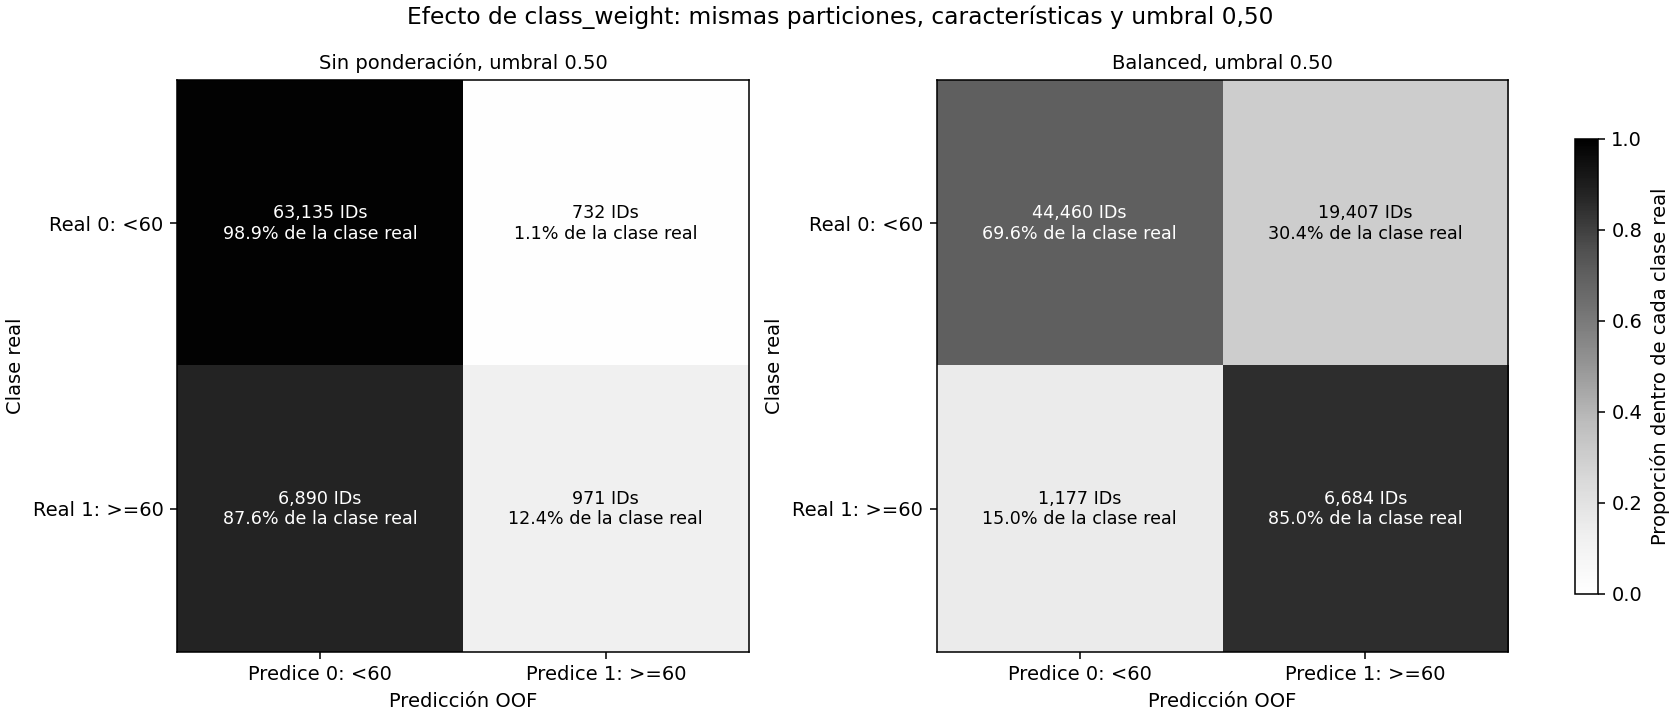

In [38]:
# Comparar ambas variantes al mismo umbral, con métricas sin ponderación
predicciones_comparacion_balanced = {"Sin ponderación, umbral 0.50": predicciones_logistica_oof, "Balanced, umbral 0.50": predicciones_balanced_oof}
matrices_comparacion_balanced = {}
registros_metricas_balanced = []
registros_rondas_balanced = []
for nombre, pred in predicciones_comparacion_balanced.items():
    assert pred.index.equals(y_clasificacion_train.index)
    matriz, resumen = resumir_clasificacion(y_clasificacion_train, pred)
    matrices_comparacion_balanced[nombre] = matriz
    registros_metricas_balanced.append({"Variante": nombre, **resumen})
    display(pd.DataFrame(matriz, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(nombre))
    for ronda in range(numero_pliegues):
        en_validacion = pliegue_por_id.eq(ronda)
        _, resumen_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_validacion], pred.loc[en_validacion])
        registros_rondas_balanced.append({"Variante": nombre, "Ronda": ronda + 1, **resumen_ronda})
tabla_metricas_balanced_oof = pd.DataFrame(registros_metricas_balanced).set_index("Variante")
tabla_rondas_balanced_oof = pd.DataFrame(registros_rondas_balanced).set_index(["Variante", "Ronda"])
for metrica in ["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]:
    assert np.isclose(tabla_metricas_balanced_oof.loc["Sin ponderación, umbral 0.50", metrica], tabla_metricas_clasificacion_oof.loc["Logística sin artista, umbral 0.50", metrica])
tabla_lectura_balanced = tabla_metricas_balanced_oof[["TP", "FN", "FP", "TN", "Positivos predichos", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]].copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    tabla_lectura_balanced[metrica] *= 100
tabla_lectura_balanced = tabla_lectura_balanced.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
display(tabla_lectura_balanced.round(4))
display(tabla_rondas_balanced_oof[["TP", "FN", "FP", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]].round(4))

# Dibujar conteos y porcentajes por clase real con la misma escala
import matplotlib.pyplot as plt
fig_balanced, ejes_balanced = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for eje, (nombre, matriz) in zip(ejes_balanced, matrices_comparacion_balanced.items()):
    proporciones_clase_real = matriz / matriz.sum(axis=1, keepdims=True)
    imagen_balanced = eje.imshow(proporciones_clase_real, vmin=0, vmax=1, cmap="Greys")
    for fila in range(2):
        for columna in range(2):
            texto = f"{matriz[fila, columna]:,} IDs\n{proporciones_clase_real[fila, columna] * 100:.1f}% de la clase real"
            eje.text(columna, fila, texto, ha="center", va="center", fontsize=9, color="white" if proporciones_clase_real[fila, columna] > 0.5 else "black")
    eje.set_xticks([0, 1], ["Predice 0: <60", "Predice 1: >=60"])
    eje.set_yticks([0, 1], ["Real 0: <60", "Real 1: >=60"])
    eje.set_xlabel("Predicción OOF")
    eje.set_ylabel("Clase real")
    eje.set_title(nombre, fontsize=10)
fig_balanced.colorbar(imagen_balanced, ax=ejes_balanced, shrink=0.7, label="Proporción dentro de cada clase real")
fig_balanced.suptitle("Efecto de class_weight: mismas particiones, características y umbral 0,50")
display(fig_balanced)
plt.close(fig_balanced)


### Cumplimiento de KPI y lectura del efecto del balanceo

**Resultados globales al umbral 0,50:**

| Variante | Precisión | Recall | F1 | Accuracy |
|---|---:|---:|---:|---:|
| Sin ponderación, umbral 0.50 | 57,02% | 12,35% | 0,2031 | 89,37% |
| Balanced, umbral 0.50 | 25,62% | 85,03% | 0,3937 | 71,30% |


**Qué cambió en los errores:** los TP pasan de **971 a 6.684**, los FN de **6.890 a 1.177** y los FP de **732 a 19.407**. La variante ponderada señala **26.091** canciones; **6.684** cumplen realmente el corte y **19.407** son falsas alarmas.

**Recall cumple:** 85,03% >=60%. Identifica 6.684 de las 7.861 positivas.

**Precisión no cumple:** 25,62% <30%. De 26.091 canciones señaladas, 19.407 son falsas alarmas. Se detectan más positivas a costa de señalar demasiadas negativas para la meta fijada. El desbalance real de validación no desaparece al ponderar el aprendizaje.

**Código del cierre:** se comparan precisión y recall de cada variante con las mismas metas 30% y 60%. La precisión debe estar definida para considerarla cumplida. La tabla de KPI de la variante ponderada copia los controles previos y actualiza sus resultados predictivos y cobertura. No cambia el corte de popularidad, la meta ni el umbral para declarar éxito. Se muestran también los estados por ronda para no esconder variación.

La Serie de cambios expresa precisión, recall y accuracy en **puntos porcentuales**, no en porcentaje de mejora relativa. Por ejemplo, pasar de 20% a 30% son +10 puntos porcentuales. El cambio de F1 se expresa en unidades de F1. Los conteos mantienen su unidad de canciones por ID.

**Alcance:** este experimento compara dos objetivos de aprendizaje con una regla de decisión numéricamente igual. No demuestra que balanced sea mejor para cualquier umbral o población, ni que sus probabilidades estén calibradas. El estudio previo de 0,20 corresponde a la logística sin ponderar y no se transfiere automáticamente a la ponderada.


In [39]:
# Evaluar ambas variantes contra las metas originales, sin modificarlas
comparacion_kpi_balanced = tabla_metricas_balanced_oof[["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy", "Precisión positiva definida"]].copy()
comparacion_kpi_balanced["Cumple precisión >=30%"] = comparacion_kpi_balanced["Precisión positiva definida"] & comparacion_kpi_balanced["Precisión clase 1"].ge(meta_precision_clasificacion)
comparacion_kpi_balanced["Cumple recall >=60%"] = comparacion_kpi_balanced["Recall clase 1"].ge(meta_recall_clasificacion)
comparacion_kpi_balanced["Cumple ambos KPI"] = comparacion_kpi_balanced["Cumple precisión >=30%"] & comparacion_kpi_balanced["Cumple recall >=60%"]
resultado_balanced = tabla_metricas_balanced_oof.loc["Balanced, umbral 0.50"]
resultado_sin_ponderar = tabla_metricas_balanced_oof.loc["Sin ponderación, umbral 0.50"]
tabla_kpi_balanced_oof = tabla_kpi_logistica_oof.copy(deep=True)
for indicador, valor, cumple in [
    ("Recall clase 1", resultado_balanced["Recall clase 1"] * 100, resultado_balanced["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", resultado_balanced["Precisión clase 1"] * 100, resultado_balanced["Precisión positiva definida"] and resultado_balanced["Precisión clase 1"] >= meta_precision_clasificacion),
    ("Cobertura de predicciones OOF", float(visitas_balanced_oof.eq(1).mean() * 100), visitas_balanced_oof.eq(1).all())
]:
    tabla_kpi_balanced_oof.loc[indicador, "Resultado"] = valor
    tabla_kpi_balanced_oof.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"
cambio_metricas_balanced = pd.Series({"Precisión: cambio en puntos porcentuales": (resultado_balanced["Precisión clase 1"] - resultado_sin_ponderar["Precisión clase 1"]) * 100, "Recall: cambio en puntos porcentuales": (resultado_balanced["Recall clase 1"] - resultado_sin_ponderar["Recall clase 1"]) * 100, "F1: cambio en unidades de F1": resultado_balanced["F1 clase 1"] - resultado_sin_ponderar["F1 clase 1"], "Accuracy: cambio en puntos porcentuales": (resultado_balanced["Accuracy"] - resultado_sin_ponderar["Accuracy"]) * 100})
cumplimiento_rondas_balanced = tabla_rondas_balanced_oof[["Precisión clase 1", "Recall clase 1", "F1 clase 1"]].copy()
cumplimiento_rondas_balanced["Cumple precisión"] = cumplimiento_rondas_balanced["Precisión clase 1"].ge(meta_precision_clasificacion)
cumplimiento_rondas_balanced["Cumple recall"] = cumplimiento_rondas_balanced["Recall clase 1"].ge(meta_recall_clasificacion)
display(comparacion_kpi_balanced.round(4))
display(tabla_kpi_balanced_oof.round({"Resultado": 4}))
display(cambio_metricas_balanced.round(4))
display(cumplimiento_rondas_balanced.round(4))


,Precisión clase 1,Recall clase 1,F1 clase 1,Accuracy,Precisión positiva definida,Cumple precisión >=30%,Cumple recall >=60%,Cumple ambos KPI
Variante,,,,,,,,
"Sin ponderación, umbral 0.50",0.5702,0.1235,0.2031,0.8937,True,True,False,False
"Balanced, umbral 0.50",0.2562,0.8503,0.3937,0.7130,True,False,True,False


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,85.0274,%,Cumple
Precisión clase 1,>= 30%,25.6180,%,No cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


Precisión: cambio en puntos porcentuales   -31.3990
Recall: cambio en puntos porcentuales       72.6752
F1: cambio en unidades de F1                 0.1907
Accuracy: cambio en puntos porcentuales    -18.0710
dtype: float64

Precisión clase 1  ...  Cumple recall
Variante                     Ronda                     ...               
Sin ponderación, umbral 0.50 1                 0.5697  ...          False
                             2                 0.5399  ...          False
                             3                 0.6100  ...          False
Balanced, umbral 0.50        1                 0.2648  ...           True
                             2                 0.2450  ...           True
                             3                 0.2597  ...           True

[6 rows x 5 columns]

### Resultado inicial de balanced con umbral fijo 0,50

La logística con `class_weight="balanced"` al umbral 0,50 obtiene **precisión 25,62%**, **recall 85,03%** y **F1 0,3937**. **No cumple ambas metas predictivas iniciales**; se informa el incumplimiento sin cambiar el umbral o la meta. La ponderación aumenta la importancia de las positivas en la pérdida; los cambios observados de TP y FP explican la compensación entre métricas, sin probar causas musicales o sociales.

- **Ronda 1:** no cumple ambos KPI: precisión 26,48% <30%.
- **Ronda 2:** no cumple ambos KPI: precisión 24,50% <30%.
- **Ronda 3:** no cumple ambos KPI: precisión 25,97% <30%.

**Lo que demuestra esta comparación:** la ponderación cambió la forma de aprender y sus probabilidades; no se añadieron canciones, no se balanceó la validación y no se cambió el umbral. Las probabilidades y etiquetas de ambas variantes se conservan como evidencia.

**Lo que no se declara:** no se escoge un ganador operativo basándose únicamente en accuracy, recall o una métrica que mejore. Se conserva la regla de considerar ambas metas predictivas y comparar F1 entre procedimientos que las cumplan. Un incumplimiento se informa como tal.

Se usaron solo los 71.728 IDs de entrenamiento, las mismas tres particiones externas agrupadas y la misma preparación sin artista. No se consultó test para clasificación. Si después se estudia otro umbral para la variante ponderada, su selección deberá ocurrir dentro de ajuste y su evaluación fuera de esa selección, sin reutilizar como confirmación el mejor resultado escogido con las mismas etiquetas.


El resultado anterior no se sustituye: se conserva para medir qué cambia al analizar otros umbrales de esta misma variante ponderada.


### Umbrales de la regresión logística balanced: precisión, recall y F1

**Objetivo:** estudiar si otra regla de decisión permite a la logística ponderada cumplir precisión >=30% y recall >=60%. Al umbral 0,50 obtuvo recall **85,03%**, pero precisión **25,62%**: detectaba muchas positivas y también demasiadas falsas alarmas para la meta fijada.

Se reutilizan **las probabilidades OOF de la variante balanced**, calculadas con las mismas tres particiones agrupadas. No se vuelven a entrenar los modelos ni se recalculan pesos. Los pesos ya se aprendieron con las frecuencias de ajuste de cada ronda. No se usa test ni se balancea la validación.

**No se transfieren umbrales entre modelos:** el 0,20 estudiado para la logística sin ponderar no se asume adecuado para balanced. La ponderación cambia el aprendizaje y las probabilidades estimadas. Un mismo número de probabilidad no garantiza la misma calibración o frecuencia real en ambas variantes.

Se conserva la lista de **16 umbrales** del análisis anterior: 0; 0,05; 0,10; 0,15; 0,20; 0,25; 0,30; 0,35; 0,40; 0,45; 0,50; 0,60; 0,70; 0,80; 0,90 y 1. También se conserva la regla: entre umbrales que cumplan **ambas metas globales**, comparar F1 positivo y desempatar por umbral mayor. Si ninguno cumple, se informa que ninguno de esta lista es elegible; no se bajan metas ni se presenta otro como cumplidor.

**Cómo esperar que cambien las métricas:** subir el umbral reduce o mantiene los positivos señalados y el recall; bajar el umbral los aumenta o mantiene. La precisión puede mejorar al ser más exigente, pero no está garantizada una mejora monótona en cada paso. F1 depende de la combinación de precisión y recall y puede subir o bajar. La popularidad real que define clase 1 sigue siendo >=60.

**Código, en orden:**

1. Se escribe la misma lista de trabajo y se comprueban índice, finitud y rango de las probabilidades ponderadas. Las metas se contrastan con 0,60 y 0,30 para evitar un cambio accidental.
2. `.ge(umbral).astype("int8")` convierte probabilidades en etiquetas por cada umbral. No cambia el modelo ni la respuesta real.
3. `resumir_clasificacion` calcula matriz y métricas sin pesos de evaluación. Se registra precisión definida, recall, F1 y conteos. El cumplimiento se compara sin redondear.
4. La tabla de lectura expresa precisión y recall en porcentaje, y mantiene F1 entre 0 y 1. Los conteos indican cuántas canciones se tendrían que revisar.
5. Los controles comprueban que al subir el umbral no crezcan positivos predichos ni recall. No se exige monotonía a precisión.
6. Se verifica que 0,50 reproduzca exactamente las etiquetas y métricas originales de **balanced**, no las de la logística sin ponderar.

**Alcance:** se selecciona una regla usando estas mismas etiquetas OOF. Las probabilidades de cada canción se obtuvieron fuera de su ajuste, pero el umbral elegido con todas ellas todavía es una decisión de desarrollo. Su métrica no es una confirmación independiente de esa selección. La validación anidada anterior correspondía a la variante sin ponderar y no confirma automáticamente esta nueva elección.


In [40]:
# Fijar los umbrales de trabajo y conservar las metas anteriores
umbrales_balanced = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00])
assert probabilidades_balanced_oof.index.equals(y_clasificacion_train.index)
assert np.isfinite(probabilidades_balanced_oof).all() and probabilidades_balanced_oof.between(0, 1).all()
assert np.isclose(meta_recall_clasificacion, 0.60) and np.isclose(meta_precision_clasificacion, 0.30)
registros_umbrales_balanced = []
for umbral in umbrales_balanced:
    etiquetas_umbral = probabilidades_balanced_oof.ge(umbral).astype("int8")
    _, resumen_umbral = resumir_clasificacion(y_clasificacion_train, etiquetas_umbral)
    cumple_recall_umbral = resumen_umbral["Recall clase 1"] >= meta_recall_clasificacion
    cumple_precision_umbral = resumen_umbral["Precisión positiva definida"] and resumen_umbral["Precisión clase 1"] >= meta_precision_clasificacion
    registros_umbrales_balanced.append({"Umbral": float(umbral), **resumen_umbral, "Cumple recall": bool(cumple_recall_umbral), "Cumple precisión": bool(cumple_precision_umbral), "Cumple ambos KPI": bool(cumple_recall_umbral and cumple_precision_umbral)})
tabla_umbrales_balanced = pd.DataFrame(registros_umbrales_balanced).set_index("Umbral").sort_index()
tabla_umbrales_balanced_lectura = tabla_umbrales_balanced[["Positivos predichos", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple precisión", "Cumple recall", "Cumple ambos KPI"]].copy()
tabla_umbrales_balanced_lectura["Precisión clase 1"] *= 100
tabla_umbrales_balanced_lectura["Recall clase 1"] *= 100
tabla_umbrales_balanced_lectura = tabla_umbrales_balanced_lectura.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)"})
assert tabla_umbrales_balanced["Positivos predichos"].diff().dropna().le(0).all()
assert tabla_umbrales_balanced["Recall clase 1"].diff().dropna().le(1e-12).all()
assert probabilidades_balanced_oof.ge(0.50).astype("int8").equals(predicciones_balanced_oof)
for metrica in ["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]:
    assert np.isclose(tabla_umbrales_balanced.loc[0.50, metrica], tabla_metricas_balanced_oof.loc["Balanced, umbral 0.50", metrica])
display(tabla_umbrales_balanced_lectura.round(4))


,Positivos predichos,Precisión (%),Recall (%),F1 clase 1,Cumple precisión,Cumple recall,Cumple ambos KPI
Umbral,,,,,,,
0.00,71728,10.9595,100.0000,0.1975,False,True,False
0.05,55964,13.9858,99.5675,0.2453,False,True,False
0.10,47195,16.3979,98.4480,0.2811,False,True,False
0.15,42299,18.1257,97.5321,0.3057,False,True,False
0.20,39086,19.4366,96.6416,0.3236,False,True,False
0.25,36916,20.4193,95.8911,0.3367,False,True,False
0.30,35118,21.2227,94.8098,0.3468,False,True,False
0.35,33411,21.9928,93.4741,0.3561,False,True,False
0.40,31431,22.8564,91.3879,0.3657,False,True,False


### Elegibilidad, matrices y cumplimiento por ronda

**Lectura del código:** se filtran las filas que cumplen ambas metas; se ordenan por F1 y, ante empate exacto, por umbral. Si la tabla está vacía se guarda `None`, sin declarar una selección exitosa. Se muestra además el mayor F1 sin restricciones para distinguir «mejor F1» de «cumple requisitos».

Para 0,50 y el umbral provisional, si existe, las matrices mantienen **filas reales y columnas predichas**: `[[TN, FP], [FN, TP]]`. Se muestran conteos para explicar qué errores se intercambian al cambiar el umbral.

El bucle por ronda utiliza `pliegue_por_id`, sin volver a dividir canciones. Las métricas globales y por ronda se distinguen: cumplir globalmente no implica cumplir en cada una de las tres rondas. Se conserva cualquier incumplimiento como evidencia de variación.

La tabla de KPI del umbral elegido copia la evidencia metodológica y actualiza precisión, recall y cobertura de sus etiquetas. Las metas siguen siendo las iniciales. No se modifica la tabla del umbral fijo ni la del modelo sin ponderar; los resultados del nuevo análisis tienen nombres propios.


In [41]:
# Aplicar la regla de elección sin cambiar los KPI
elegibles_umbrales_balanced = tabla_umbrales_balanced.reset_index().loc[lambda tabla: tabla["Cumple ambos KPI"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
mejor_f1_balanced_sin_restriccion = tabla_umbrales_balanced.reset_index().sort_values(["F1 clase 1", "Umbral"], ascending=[False, False]).iloc[0]
umbral_provisional_balanced = None if elegibles_umbrales_balanced.empty else float(elegibles_umbrales_balanced.iloc[0]["Umbral"])
display(elegibles_umbrales_balanced[["Umbral", "Precisión clase 1", "Recall clase 1", "F1 clase 1"]].round(4))
display(mejor_f1_balanced_sin_restriccion[["Umbral", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple ambos KPI"]])

# Conservar 0,50 como referencia y comparar el provisional, si existe
umbrales_detalle_balanced = [0.50]
if umbral_provisional_balanced is not None and not np.isclose(umbral_provisional_balanced, 0.50):
    umbrales_detalle_balanced.append(umbral_provisional_balanced)
registros_umbrales_balanced_por_ronda = []
for umbral in umbrales_detalle_balanced:
    pred_detalle = probabilidades_balanced_oof.ge(umbral).astype("int8")
    matriz_detalle, _ = resumir_clasificacion(y_clasificacion_train, pred_detalle)
    display(pd.DataFrame(matriz_detalle, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(f"OOF: umbral {umbral:.2f}"))
    for ronda in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(ronda)
        _, resumen_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred_detalle.loc[en_ronda])
        registros_umbrales_balanced_por_ronda.append({"Umbral": umbral, "Ronda": ronda + 1, "IDs": int(en_ronda.sum()), "Precisión (%)": resumen_ronda["Precisión clase 1"] * 100, "Recall (%)": resumen_ronda["Recall clase 1"] * 100, "F1": resumen_ronda["F1 clase 1"], "Cumple ambos KPI": resumen_ronda["Precisión positiva definida"] and resumen_ronda["Precisión clase 1"] >= meta_precision_clasificacion and resumen_ronda["Recall clase 1"] >= meta_recall_clasificacion})
tabla_umbrales_balanced_por_ronda = pd.DataFrame(registros_umbrales_balanced_por_ronda).set_index(["Umbral", "Ronda"])
display(tabla_umbrales_balanced_por_ronda.round(4))

# Actualizar evidencia del umbral elegido, si cumple las dos metas globales
tabla_kpi_umbral_balanced = None
predicciones_umbral_balanced_oof = None
if umbral_provisional_balanced is None:
    display("Ningún umbral de la lista cumple ambas metas. No se elige un umbral cumplidor ni se cambian los KPI.")
else:
    fila_provisional = tabla_umbrales_balanced.loc[umbral_provisional_balanced]
    predicciones_umbral_balanced_oof = probabilidades_balanced_oof.ge(umbral_provisional_balanced).astype("int8")
    assert predicciones_umbral_balanced_oof.index.equals(y_clasificacion_train.index)
    assert len(predicciones_umbral_balanced_oof) == len(y_clasificacion_train) and predicciones_umbral_balanced_oof.isin([0, 1]).all()
    tabla_kpi_umbral_balanced = tabla_kpi_balanced_oof.copy(deep=True)
    tabla_kpi_umbral_balanced.loc["Recall clase 1", "Resultado"] = float(fila_provisional["Recall clase 1"]) * 100
    tabla_kpi_umbral_balanced.loc["Precisión clase 1", "Resultado"] = float(fila_provisional["Precisión clase 1"]) * 100
    tabla_kpi_umbral_balanced.loc["Recall clase 1", "Estado"] = "Cumple" if fila_provisional["Cumple recall"] else "No cumple"
    tabla_kpi_umbral_balanced.loc["Precisión clase 1", "Estado"] = "Cumple" if fila_provisional["Cumple precisión"] else "No cumple"
    tabla_kpi_umbral_balanced.loc["Cobertura de predicciones OOF", "Resultado"] = float(predicciones_umbral_balanced_oof.notna().mean() * 100)
    display(tabla_kpi_umbral_balanced.round({"Resultado": 4}))


,Umbral,Precisión clase 1,Recall clase 1,F1 clase 1
11,0.6,0.3037,0.7372,0.4301


Umbral                    0.7
Precisión clase 1    0.367608
Recall clase 1       0.556672
F1 clase 1           0.442803
Cumple ambos KPI        False
Name: 12, dtype: object

,Predice 0: <60,Predice 1: >=60
OOF: umbral 0.50,,
Real 0: <60,44460,19407
Real 1: >=60,1177,6684


,Predice 0: <60,Predice 1: >=60
OOF: umbral 0.60,,
Real 0: <60,50578,13289
Real 1: >=60,2066,5795


IDs  Precisión (%)  Recall (%)      F1  Cumple ambos KPI
Umbral Ronda                                                            
0.5    1      23913        26.4842     83.6765  0.4023             False
       2      24104        24.4987     85.9656  0.3813             False
       3      23711        25.9674     85.4757  0.3983             False
0.6    1      23913        30.6686     71.9581  0.4301              True
       2      24104        29.6548     75.2199  0.4254             False
       3      23711        30.8215     74.0194  0.4352              True

,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,73.7184,%,Cumple
Precisión clase 1,>= 30%,30.3658,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


### Gráfico del efecto de los umbrales en balanced

El panel izquierdo muestra precisión y recall frente al umbral, con sus metas de 0,30 y 0,60. El derecho muestra F1; los cuadrados vacíos destacan los umbrales elegibles. La línea vertical de 0,50 representa la regla inicial y otra línea identifica el provisional cuando existe.

`subplots` crea los paneles; `plot` dibuja las métricas calculadas; `axhline` y `axvline` indican metas y decisiones, y `scatter` marca cumplimiento. `legend` identifica cada elemento; `display` inserta la figura y `close` libera sus recursos. Las líneas conectan umbrales calculados, no certifican todos los valores intermedios.

En los extremos, umbral 0 señala todas las canciones; umbral 1 solo señala probabilidades iguales a 1, si las hubiera. Sin positivos predichos, precisión es indefinida y se representa como cero por la convención documentada. Ese cero no debe confundirse con una precisión estimada a partir de positivos.


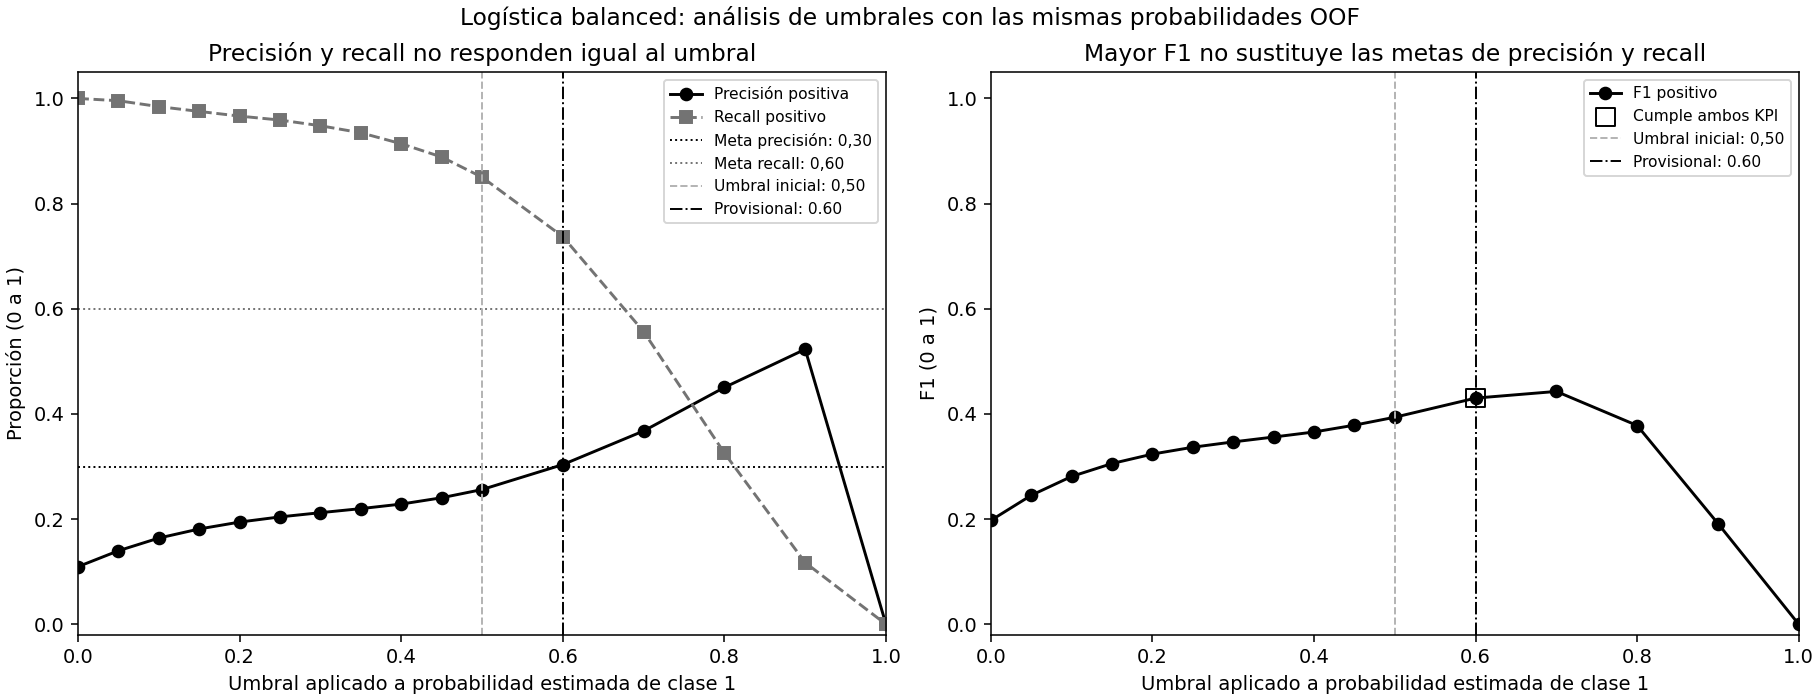

In [42]:
# Dibujar la compensación entre métricas con el modelo y sus probabilidades fijos
import matplotlib.pyplot as plt
fig_umbrales_balanced, ejes_umbrales_balanced = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
ejes_umbrales_balanced[0].plot(tabla_umbrales_balanced.index, tabla_umbrales_balanced["Precisión clase 1"], color="black", marker="o", label="Precisión positiva")
ejes_umbrales_balanced[0].plot(tabla_umbrales_balanced.index, tabla_umbrales_balanced["Recall clase 1"], color="0.45", linestyle="--", marker="s", label="Recall positivo")
ejes_umbrales_balanced[0].axhline(meta_precision_clasificacion, color="black", linestyle=":", linewidth=1, label="Meta precisión: 0,30")
ejes_umbrales_balanced[0].axhline(meta_recall_clasificacion, color="0.45", linestyle=":", linewidth=1, label="Meta recall: 0,60")
ejes_umbrales_balanced[0].set_title("Precisión y recall no responden igual al umbral")
ejes_umbrales_balanced[0].set_ylabel("Proporción (0 a 1)")
ejes_umbrales_balanced[1].plot(tabla_umbrales_balanced.index, tabla_umbrales_balanced["F1 clase 1"], color="black", marker="o", label="F1 positivo")
filas_elegibles_balanced = tabla_umbrales_balanced.loc[tabla_umbrales_balanced["Cumple ambos KPI"]]
ejes_umbrales_balanced[1].scatter(filas_elegibles_balanced.index, filas_elegibles_balanced["F1 clase 1"], marker="s", s=90, facecolors="none", edgecolors="black", label="Cumple ambos KPI")
ejes_umbrales_balanced[1].set_title("Mayor F1 no sustituye las metas de precisión y recall")
ejes_umbrales_balanced[1].set_ylabel("F1 (0 a 1)")
for eje in ejes_umbrales_balanced:
    eje.axvline(0.50, color="0.7", linestyle="--", linewidth=1, label="Umbral inicial: 0,50")
    if umbral_provisional_balanced is not None:
        eje.axvline(umbral_provisional_balanced, color="black", linestyle="-.", linewidth=1, label=f"Provisional: {umbral_provisional_balanced:.2f}")
    eje.set_xlim(0, 1)
    eje.set_ylim(-0.02, 1.05)
    eje.set_xlabel("Umbral aplicado a probabilidad estimada de clase 1")
    eje.legend(fontsize=8)
fig_umbrales_balanced.suptitle("Logística balanced: análisis de umbrales con las mismas probabilidades OOF")
display(fig_umbrales_balanced)
plt.close(fig_umbrales_balanced)


### Conclusión del análisis de umbrales de balanced

**Umbral provisional de balanced: 0,60.** Precisión **30,37%**, recall **73,72%** y F1 **0,4301**. Cumple precisión >=30% y recall >=60% globalmente. Es el mayor F1 entre los elegibles de esta lista: **0,60**. No se afirma optimalidad sobre todos los valores posibles.

Frente al umbral 0,50, los TP pasan de **6.684 a 5.795**, los FN de **1.177 a 2.066** y los FP de **19.407 a 13.289**. Se señalan **19.084** canciones en vez de **26.091**. El **69,63% de las señaladas no cumple el corte real**, aunque se alcance la meta mínima de precisión.

- **Umbral 0,50: no cumple ambos KPI.** precisión 25,62% <30%: 19.407 falsas alarmas entre 26.091 canciones señaladas.
- **Umbral 0,70: no cumple ambos KPI.** recall 55,67% <60%: se detectan 4.376 de 7.861 positivas y se omiten 3.485.
- **Umbral 0,80: no cumple ambos KPI.** recall 32,57% <60%: se detectan 2.560 de 7.861 positivas y se omiten 5.301.

- **Ronda 1, umbral 0,60:** cumple ambos, con precisión 30,67% y recall 71,96%.
- **Ronda 2, umbral 0,60:** no cumple ambos KPI: precisión 29,65% <30%.
- **Ronda 3, umbral 0,60:** cumple ambos, con precisión 30,82% y recall 74,02%.

Los KPI se definieron sobre el conjunto OOF global; los incumplimientos por ronda se informan como variación, sin redondearlos a cumplimiento.

**Mayor F1 no basta:** 0,70 obtiene F1=0,4428, superior al 0,4301 de 0,60, pero su recall es 55,67% <60%. Por eso no es elegible aunque tenga el mayor F1 de la lista.

**Margen y estabilidad:** en 0,60 la precisión global supera la meta por apenas 0,37 puntos porcentuales. La ronda 2, con 29,65%, no se redondea a cumplimiento. El éxito global de desarrollo no implica que las tres particiones cumplan ni garantiza precisión mínima en datos nuevos.

**Por qué cambia el cumplimiento:** subir la exigencia sobre las probabilidades ponderadas puede reducir falsas alarmas, pero también excluye positivas verdaderas. Los conteos y denominadores explican el efecto observado. Un recall alto no compensa incumplir precisión, ni una precisión alta compensa incumplir recall. F1 sirve para comparar solo después de respetar ambas metas, según la regla fijada.

No se reducen metas ni se amplía la lista automáticamente en función de los resultados. Si no hubiera elegibles, la conclusión sería incumplimiento de los umbrales analizados, no imposibilidad para cualquier regla o modelo.

**Estado de esta elección:** análisis de desarrollo con las mismas probabilidades OOF ponderadas, sin nuevos ajustes, sin cambiar pesos o clases y sin consultar test. Una selección provisional deberá comprobarse separando elección y evaluación del umbral para **esta variante balanced**, usando agrupación también dentro de ajuste. No se presenta la validación anidada de la variante sin ponderar como evidencia de este umbral.


### Validación anidada del umbral de la logística balanced

**Objetivo:** comprobar el procedimiento de elegir un umbral para la variante ponderada sin usar las respuestas de la validación externa para escogerlo. El 0,60 del análisis anterior cumplió globalmente, pero se escogió con esas mismas etiquetas OOF y su margen de precisión era pequeño. La validación anidada de la logística sin ponderar no confirma por sí sola esta nueva elección.

Se mantiene exactamente el protocolo ya establecido:

1. **Tres rondas externas agrupadas**, con los mismos IDs de entrenamiento y la misma clave artista + título.
2. **Tres rondas internas agrupadas dentro de cada ajuste externo**, con semilla 42 para distribuir claves. No se subdivide ni consulta test.
3. En cada ajuste interno se clona **la plantilla balanced**. El preprocesamiento aprende solo en ajuste interno. `class_weight="balanced"` calcula automáticamente los pesos a partir de **sus propias etiquetas de ajuste interno**, no de toda la base, ni del ajuste externo completo ni de validación. No se reutilizan manualmente pesos anteriores.
4. Se obtienen probabilidades OOF internas y se compara la misma lista de 16 umbrales, manteniendo recall >=60%, precisión >=30%, mayor F1 entre elegibles y desempate por umbral mayor.
5. Se fija el umbral de esa ronda sin sus respuestas externas. Si no hay elegible, se conserva el **respaldo 0,50**, igual que en el protocolo anterior; se declara la ausencia de candidato que cumpla y no se presenta el respaldo como éxito.
6. Se aplica ese umbral a las probabilidades externas de balanced ya guardadas. Proceden del modelo entrenado con todo el ajuste externo de la misma ronda, con sus pesos aprendidos solo allí. Así no se repiten tres ajustes externos idénticos.
7. Se reúnen las etiquetas externas para calcular métricas ordinarias, sin ponderar la validación ni cambiar su prevalencia.

**Son nueve ajustes internos nuevos**, no un cambio del modelo de regresión ni una búsqueda de otro C o de balanceo. Las características siguen siendo las 127 entradas sin artista. La popularidad real que define clase positiva permanece en >=60.

**Código, en orden:**

- Se verifica que la plantilla pasada a la selección tenga `class_weight="balanced"`, C=1, límite de 2.000 iteraciones y la misma tolerancia. Los pesos se recalculan dentro de cada llamada a `.fit` de esa plantilla.
- Se reutiliza `seleccionar_umbral_interno`, la función ya explicada en el apartado anterior: recibe solo X, etiquetas y claves del ajuste externo, la plantilla y las reglas. Al cambiar la plantilla a balanced, sus clones internos también serán balanced; no se duplica la función ni se repite su lógica.
- Las Series reservan una predicción y un umbral por ID. Las listas y diccionarios guardan decisiones y evidencia interna con nombres distintos de los de la variante sin ponderar.
- El bucle conserva la máscara externa existente. `.loc[~validar_externo]` entrega a la selección únicamente el ajuste externo; se verifica que no comparta claves con validación externa.
- La función devuelve umbral, elegibilidad, motivo, métricas internas y controles. Esas métricas sirven para elegir y no se confunden con las de la evaluación externa posterior.
- Solo después de elegir se consulta la **probabilidad externa** correspondiente y se convierte en etiqueta con `.ge(umbral_usado)`. No se utilizan respuestas externas en ese paso.
- Se comprueba una sola visita por ID, cobertura y etiquetas binarias. Las tablas muestran qué se eligió y los tamaños de los nueve ajustes internos, sin ocultar respaldos ni rondas difíciles.

Las respuestas externas se usan para evaluar en la siguiente celda. Este es un protocolo interno que separa elección y evaluación en cada ronda; **no es una muestra inédita**, porque el dataset y sus validaciones se observaron antes durante el desarrollo. No se cambian las reglas según sus nuevos resultados.


In [43]:
# Mantener la configuración de balanced en todos los clones internos
assert modelo_logistico_balanced_base.named_steps["clasificar"].class_weight == "balanced"
assert modelo_logistico_balanced_base.named_steps["clasificar"].C == 1.0
assert modelo_logistico_balanced_base.named_steps["clasificar"].max_iter == 2000
assert np.isclose(modelo_logistico_balanced_base.named_steps["clasificar"].tol, 1e-6)

# Reutilizar la función de selección con la plantilla balanced y sus probabilidades externas
assert probabilidades_balanced_oof.index.equals(y_clasificacion_train.index)
assert np.isfinite(probabilidades_balanced_oof).all()
predicciones_umbral_balanced_anidado_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64")
umbral_balanced_asignado_por_id = pd.Series(index=y_clasificacion_train.index, dtype="float64")
visitas_externas_balanced_anidadas = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
selecciones_balanced_anidadas = []
controles_ajustes_balanced_internos = []
evidencia_interna_balanced_por_ronda = {}

for ronda_externa in range(numero_pliegues):
    validar_externo = pliegue_por_id.eq(ronda_externa)
    ajustar_externo = ~validar_externo
    claves_ajuste_externo = datos_entrenamiento.loc[ajustar_externo, "clave_cancion"]
    assert set(claves_ajuste_externo).isdisjoint(set(datos_entrenamiento.loc[validar_externo, "clave_cancion"]))
    umbral_usado, hubo_elegible, motivo, tabla_interna, controles_internos, prob_internas = seleccionar_umbral_interno(X_train.loc[ajustar_externo], y_clasificacion_train.loc[ajustar_externo], claves_ajuste_externo, modelo_logistico_balanced_base, umbrales_balanced, meta_recall_clasificacion, meta_precision_clasificacion)
    evidencia_interna_balanced_por_ronda[ronda_externa + 1] = {"Tabla de umbrales internos": tabla_interna, "Probabilidades internas": prob_internas}
    fila_interna = tabla_interna.loc[umbral_usado]
    selecciones_balanced_anidadas.append({"Ronda externa": ronda_externa + 1, "IDs ajuste externo": int(ajustar_externo.sum()), "IDs validación externa": int(validar_externo.sum()), "Umbral usado": umbral_usado, "Hubo umbral interno elegible": hubo_elegible, "Precisión interna (%)": fila_interna["Precisión clase 1"] * 100, "Recall interno (%)": fila_interna["Recall clase 1"] * 100, "F1 interno": fila_interna["F1 clase 1"], "Motivo": motivo})
    controles_internos["Ronda externa"] = ronda_externa + 1
    controles_ajustes_balanced_internos.append(controles_internos)
    predicciones_umbral_balanced_anidado_oof.loc[validar_externo] = probabilidades_balanced_oof.loc[validar_externo].ge(umbral_usado).astype("int8")
    umbral_balanced_asignado_por_id.loc[validar_externo] = umbral_usado
    visitas_externas_balanced_anidadas.loc[validar_externo] += 1
assert visitas_externas_balanced_anidadas.eq(1).all()
assert predicciones_umbral_balanced_anidado_oof.notna().all() and predicciones_umbral_balanced_anidado_oof.isin([0, 1]).all()
predicciones_umbral_balanced_anidado_oof = predicciones_umbral_balanced_anidado_oof.astype("int8")
tabla_seleccion_balanced_anidada = pd.DataFrame(selecciones_balanced_anidadas).set_index("Ronda externa")
tabla_controles_ajustes_balanced_internos = pd.concat(controles_ajustes_balanced_internos, ignore_index=True).set_index(["Ronda externa", "Ronda interna"])
display(tabla_seleccion_balanced_anidada.round(4))
display(tabla_controles_ajustes_balanced_internos)


,IDs ajuste externo,IDs validación externa,Umbral usado,Hubo umbral interno elegible,Precisión interna (%),Recall interno (%),F1 interno,Motivo
Ronda externa,,,,,,,,
1,47815,23913,0.6,True,30.7092,72.8324,0.4320,Mayor F1 interno entre umbrales que cumplen am...
2,47624,24104,0.6,True,30.7809,73.7133,0.4343,Mayor F1 interno entre umbrales que cumplen am...
3,48017,23711,0.6,True,30.0094,72.7582,0.4249,Mayor F1 interno entre umbrales que cumplen am...


IDs ajuste interno  ...  Iteraciones
Ronda externa Ronda interna                      ...             
1             1                           31862  ...          210
              2                           31854  ...          199
              3                           31914  ...          210
2             1                           31821  ...          204
              2                           31752  ...          202
              3                           31675  ...          199
3             1                           32108  ...          195
              2                           32047  ...          210
              3                           31879  ...          215

[9 rows x 4 columns]

### Evaluar las decisiones externas de balanced y revisar los KPI

**Código, en orden:**

1. La matriz global utiliza una etiqueta externa por ID. Filas reales y columnas predichas mantienen `[[TN, FP], [FN, TP]]`. `resumir_clasificacion` calcula precisión, recall, F1 y accuracy sin pesos de evaluación.
2. La tabla por ronda registra umbral usado, TP, FN, FP y cumplimiento de cada meta. El umbral no se corrige después de conocer este resultado externo.
3. La comparación distingue balanced al 0,50 fijo, el 0,60 escogido con etiquetas OOF globales y la selección interna evaluada externamente. La fila de 0,60 anterior es evidencia de desarrollo, no una evaluación independiente de su elección.
4. La tabla de KPI conserva metas y controles metodológicos y actualiza precisión, recall y cobertura del **procedimiento anidado balanced**. Se mantiene separada de la tabla de la variante sin ponderar.
5. Se verifica que todas las observaciones estén en la matriz y que el recall global coincida con la suma de TP dividida por la suma de TP+FN. No se promedian porcentajes de rondas.

**Cómo interpretar un incumplimiento:** si recall queda por debajo de 60%, se informa cuántas positivas no se identifican; si precisión queda por debajo de 30%, se informa cuántas falsas alarmas hay entre las señaladas. Si una selección interna no encuentra un umbral elegible, también se declara y se mantiene el respaldo fijado, sin reinterpretarlo como selección exitosa.

Que alguna métrica mejore frente al 0,50 no basta para declarar cumplimiento. Se exige simultáneamente recall y precisión con los límites iniciales. Tampoco se reemplaza una ronda que falle por otra más favorable.


In [44]:
# Calcular la matriz global con predicciones externas del procedimiento anidado
matriz_umbral_balanced_anidado, resumen_umbral_balanced_anidado = resumir_clasificacion(y_clasificacion_train, predicciones_umbral_balanced_anidado_oof)
display(pd.DataFrame(matriz_umbral_balanced_anidado, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis("Balanced: selección interna de umbral y evaluación externa"))
registros_evaluacion_balanced_anidada = []
for ronda_externa in range(numero_pliegues):
    en_externa = pliegue_por_id.eq(ronda_externa)
    _, metricas_externas = resumir_clasificacion(y_clasificacion_train.loc[en_externa], predicciones_umbral_balanced_anidado_oof.loc[en_externa])
    registros_evaluacion_balanced_anidada.append({"Ronda externa": ronda_externa + 1, "Umbral usado": float(tabla_seleccion_balanced_anidada.loc[ronda_externa + 1, "Umbral usado"]), "IDs": int(en_externa.sum()), "TP": metricas_externas["TP"], "FN": metricas_externas["FN"], "FP": metricas_externas["FP"], "Precisión (%)": metricas_externas["Precisión clase 1"] * 100, "Recall (%)": metricas_externas["Recall clase 1"] * 100, "F1": metricas_externas["F1 clase 1"], "Cumple precisión": bool(metricas_externas["Precisión positiva definida"] and metricas_externas["Precisión clase 1"] >= meta_precision_clasificacion), "Cumple recall": bool(metricas_externas["Recall clase 1"] >= meta_recall_clasificacion)})
tabla_evaluacion_balanced_anidada = pd.DataFrame(registros_evaluacion_balanced_anidada).set_index("Ronda externa")

# Comparar alcances de evaluación, sin elegir otro protocolo por su resultado
fila_inicial = tabla_metricas_balanced_oof.loc["Balanced, umbral 0.50"]
fila_global_balanced_060 = tabla_umbrales_balanced.loc[0.60]
comparacion_protocolos_umbral_balanced = pd.DataFrame([
    {"Protocolo": "Balanced 0,50 fijado antes del análisis", "Precisión (%)": fila_inicial["Precisión clase 1"] * 100, "Recall (%)": fila_inicial["Recall clase 1"] * 100, "F1": fila_inicial["F1 clase 1"], "Alcance": "Predicciones OOF con umbral inicial fijo"},
    {"Protocolo": "Balanced 0,60 escogido con etiquetas OOF globales", "Precisión (%)": fila_global_balanced_060["Precisión clase 1"] * 100, "Recall (%)": fila_global_balanced_060["Recall clase 1"] * 100, "F1": fila_global_balanced_060["F1 clase 1"], "Alcance": "Desarrollo del umbral sobre etiquetas utilizadas para escogerlo"},
    {"Protocolo": "Balanced: selección interna y evaluación externa agrupadas", "Precisión (%)": resumen_umbral_balanced_anidado["Precisión clase 1"] * 100, "Recall (%)": resumen_umbral_balanced_anidado["Recall clase 1"] * 100, "F1": resumen_umbral_balanced_anidado["F1 clase 1"], "Alcance": "Validación interna adicional con elección y evaluación separadas"}
]).set_index("Protocolo")
tabla_kpi_umbral_balanced_anidado = tabla_kpi_balanced_oof.copy(deep=True)
for indicador, valor, cumple in [
    ("Recall clase 1", resumen_umbral_balanced_anidado["Recall clase 1"] * 100, resumen_umbral_balanced_anidado["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", resumen_umbral_balanced_anidado["Precisión clase 1"] * 100, resumen_umbral_balanced_anidado["Precisión positiva definida"] and resumen_umbral_balanced_anidado["Precisión clase 1"] >= meta_precision_clasificacion),
    ("Cobertura de predicciones OOF", float(visitas_externas_balanced_anidadas.eq(1).mean() * 100), visitas_externas_balanced_anidadas.eq(1).all())
]:
    tabla_kpi_umbral_balanced_anidado.loc[indicador, "Resultado"] = valor
    tabla_kpi_umbral_balanced_anidado.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"
assert int(matriz_umbral_balanced_anidado.sum()) == len(y_clasificacion_train)
assert np.isclose(resumen_umbral_balanced_anidado["Recall clase 1"], tabla_evaluacion_balanced_anidada["TP"].sum() / (tabla_evaluacion_balanced_anidada["TP"].sum() + tabla_evaluacion_balanced_anidada["FN"].sum()))
display(pd.Series(resumen_umbral_balanced_anidado))
display(tabla_evaluacion_balanced_anidada.round(4))
display(comparacion_protocolos_umbral_balanced.round(4))
display(tabla_kpi_umbral_balanced_anidado.round({"Resultado": 4}))


,Predice 0: <60,Predice 1: >=60
Balanced: selección interna de umbral y evaluación externa,,
Real 0: <60,50578,13289
Real 1: >=60,2066,5795


IDs                               71728
TN                                50578
FP                                13289
FN                                 2066
TP                                 5795
Positivos predichos               19084
Precisión positiva definida        True
Precisión clase 1              0.303658
Recall clase 1                 0.737184
F1 clase 1                     0.430135
Accuracy                       0.785927
dtype: object

,Umbral usado,IDs,TP,FN,FP,Precisión (%),Recall (%),F1,Cumple precisión,Cumple recall
Ronda externa,,,,,,,,,,
1,0.6,23913,1922,749,4345,30.6686,71.9581,0.4301,True,True
2,0.6,24104,1967,648,4666,29.6548,75.2199,0.4254,False,True
3,0.6,23711,1906,669,4278,30.8215,74.0194,0.4352,True,True


,Precisión (%),Recall (%),F1,Alcance
Protocolo,,,,
"Balanced 0,50 fijado antes del análisis",25.6180,85.0274,0.3937,Predicciones OOF con umbral inicial fijo
"Balanced 0,60 escogido con etiquetas OOF globales",30.3658,73.7184,0.4301,Desarrollo del umbral sobre etiquetas utilizad...
Balanced: selección interna y evaluación externa agrupadas,30.3658,73.7184,0.4301,Validación interna adicional con elección y ev...


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,73.7184,%,Cumple
Precisión clase 1,>= 30%,30.3658,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


### Conclusión de la validación anidada de balanced

El procedimiento anidado de balanced obtiene **precisión 30,37%**, **recall 73,72%** y **F1 0,4301** sobre las 71.728 etiquetas externas. TN=50.578, FP=13.289, FN=2.066, TP=5.795.

**Decisiones internas:**

- **Ronda externa 1:** umbral usado 0,60; precisión interna 30,71% y recall interno 72,83%. Se encontró candidato interno que cumple ambas metas y se eligió por F1.
- **Ronda externa 2:** umbral usado 0,60; precisión interna 30,78% y recall interno 73,71%. Se encontró candidato interno que cumple ambas metas y se eligió por F1.
- **Ronda externa 3:** umbral usado 0,60; precisión interna 30,01% y recall interno 72,76%. Se encontró candidato interno que cumple ambas metas y se eligió por F1.

**Evaluación externa por ronda:**

- **Ronda externa 1:** cumple ambos: precisión 30,67% y recall 71,96%.
- **Ronda externa 2:** no cumple ambos KPI; precisión 29,65% <30%: 4.666 falsas alarmas entre 6.633 señaladas.
- **Ronda externa 3:** cumple ambos: precisión 30,82% y recall 74,02%.

**KPI globales:**

- **Precisión cumple:** 30,37% >=30%.
- **Recall cumple:** 73,72% >=60%; detecta 5.795 de las 7.861 positivas.
- Los controles de etiquetas, separación agrupada y cobertura externa del 100% se mantienen. Estos controles no compensan un KPI predictivo incumplido.

Las tres selecciones internas eligieron 0,60. Por eso las etiquetas externas y métricas coinciden con el análisis anterior. La evidencia adicional está en cómo se eligió el umbral; no son dos pruebas independientes con muestras diferentes.

**Margen de cumplimiento:** la precisión global supera el mínimo por solo 0,37 puntos porcentuales. En la selección interna de la ronda externa 3, la precisión fue 30,0094%, apenas por encima del límite. No se redondea el 29,65% de la evaluación externa de ronda 2 a un cumplimiento. Estas diferencias muestran por qué hay que conservar las cifras y reportar la variación.

**Lectura del alcance:** el resultado evalúa la regla completa de aprender balanced, seleccionar un umbral dentro de ajuste y aplicarlo a otras canciones de la misma partición de entrenamiento. Puede usar umbrales distintos por ronda; no certifica un valor único para cualquier población. Si hay respaldos, forman parte del procedimiento evaluado y no se excluyen para calcular mejores métricas.

Los resultados no identifican causas musicales o sociales de los errores. La ausencia de un umbral elegible se refiere a la lista y las subdivisiones internas utilizadas, no prueba que ningún otro procedimiento pueda funcionar. Si alguna meta falla, permanece documentada: no se amplía la lista ni se bajan los KPI después de ver esta evaluación.

Se conservaron la logística sin artista, ponderación balanced, C=1, los mismos 16 umbrales y las mismas metas. Los pesos se calcularon en cada ajuste interno por el propio clasificador. La validación conservó su distribución original y sus métricas ordinarias. **No se consultó test para clasificación.**

Esta comprobación sigue siendo interna sobre una fuente y particiones previamente exploradas. No se declara que el dataset sea una prueba externa independiente ni se cambia el procedimiento por el resultado observado.


### Comparación de las dos logísticas con selección anidada del umbral

**Pregunta:** con la regla de evaluación más estricta que ya aplicamos, ¿qué procedimiento conviene conservar provisionalmente?

Se comparan **dos procedimientos completos**, ambos sin artista y con la misma logística base: uno aprende sin ponderación y otro con `class_weight="balanced"`. Cada uno elige umbral con validación interna agrupada y se evalúa en las mismas validaciones externas. No se compara el mejor resultado exploratorio de uno con el resultado anidado del otro.

**Regla de elección conservada:** primero exigir recall >=60% y precisión >=30% **globales**; entre los procedimientos que los cumplan, elegir el mayor F1 positivo. Si ninguno cumple, declarar que no hay procedimiento elegible. No se cambia la prioridad a accuracy o solo recall después de ver cuál mejora.

La comparación es posible porque ambas variantes utilizan los mismos 71.728 IDs, las mismas etiquetas reales y los mismos tres pliegues externos. Las diferencias de umbral son parte del procedimiento: no tiene sentido exigirles el mismo valor numérico después de que sus probabilidades cambiaron con la ponderación. Aquí evaluamos **modelo + regla de selección del umbral**, no solo el efecto aislado de `class_weight`; ese efecto ya se estudió con ambas variantes en 0,50.

**Código, en orden:**

1. Los diccionarios reúnen las **etiquetas externas anidadas**, tablas de selección y plantillas. No se entrenan modelos ni se vuelven a calcular probabilidades.
2. Para cada variante se comprueba el mismo índice y etiquetas válidas. `resumir_clasificacion` recalcula matriz y métricas sobre las mismas respuestas, sin pesos de evaluación. Las metas originales generan las columnas de cumplimiento.
3. Los umbrales por ronda y la cantidad de respaldos 0,50 documentan lo que realmente hizo cada procedimiento; un respaldo no se interpreta como candidato interno exitoso.
4. El bucle por ronda vuelve a calcular métricas con la máscara externa existente. Las tablas incluyen conteos y cumplimiento por partición, sin promediar porcentajes para producir el resultado global.
5. `sort_values` ordena elegibles por F1 descendente. La selección es provisional; si hubiera empate exacto habría que documentar una decisión adicional, sin afirmar superioridad por un orden accidental. En estos resultados no hay empate.
6. La copia de lectura multiplica precisión, recall y accuracy por cien y conserva F1 entre 0 y 1. Se mantiene precisión completa para comparar metas. La tabla de conteos separa TP, FN, FP y TN para hacer visible el costo de la elección.
7. Se contrastan las métricas recalculadas con los resúmenes anidados guardados; esto evita mezclar resultados de umbral fijo o exploratorio con la validación anidada.

Aunque exista un orden de F1, solo hay tres particiones y sus ajustes se solapan entre rondas. No se presenta una prueba estadística de superioridad ni se describe esta comparación sobre datos ya explorados como evaluación externa inédita.


In [45]:
# Reunir solo los resultados de ambos procedimientos anidados
predicciones_comparacion_anidada = {"Sin ponderación": predicciones_umbral_anidado_oof, "Balanced": predicciones_umbral_balanced_anidado_oof}
selecciones_comparacion_anidada = {"Sin ponderación": tabla_seleccion_anidada, "Balanced": tabla_seleccion_balanced_anidada}
plantillas_comparacion_clasificacion = {"Sin ponderación": modelo_logistico_base, "Balanced": modelo_logistico_balanced_base}
registros_comparacion_anidada = []
registros_comparacion_rondas = []
for variante, pred in predicciones_comparacion_anidada.items():
    assert pred.index.equals(y_clasificacion_train.index)
    assert pred.notna().all() and pred.isin([0, 1]).all()
    _, resumen = resumir_clasificacion(y_clasificacion_train, pred)
    cumple_precision = resumen["Precisión positiva definida"] and resumen["Precisión clase 1"] >= meta_precision_clasificacion
    cumple_recall = resumen["Recall clase 1"] >= meta_recall_clasificacion
    seleccion = selecciones_comparacion_anidada[variante]
    registros_comparacion_anidada.append({"Variante": variante, **resumen, "Cumple precisión": bool(cumple_precision), "Cumple recall": bool(cumple_recall), "Cumple ambos KPI": bool(cumple_precision and cumple_recall), "Umbrales por ronda": seleccion["Umbral usado"].to_dict(), "Rondas con respaldo": int((~seleccion["Hubo umbral interno elegible"]).sum())})
    for ronda in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(ronda)
        _, resultado_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred.loc[en_ronda])
        precision_cumple = resultado_ronda["Precisión positiva definida"] and resultado_ronda["Precisión clase 1"] >= meta_precision_clasificacion
        recall_cumple = resultado_ronda["Recall clase 1"] >= meta_recall_clasificacion
        registros_comparacion_rondas.append({"Variante": variante, "Ronda externa": ronda + 1, "Umbral usado": float(seleccion.loc[ronda + 1, "Umbral usado"]), "IDs": resultado_ronda["IDs"], "TP": resultado_ronda["TP"], "FN": resultado_ronda["FN"], "FP": resultado_ronda["FP"], "Precisión (%)": resultado_ronda["Precisión clase 1"] * 100, "Recall (%)": resultado_ronda["Recall clase 1"] * 100, "F1": resultado_ronda["F1 clase 1"], "Cumple precisión": bool(precision_cumple), "Cumple recall": bool(recall_cumple), "Cumple ambos KPI": bool(precision_cumple and recall_cumple)})
comparacion_logisticas_anidadas = pd.DataFrame(registros_comparacion_anidada).set_index("Variante")
comparacion_logisticas_anidadas_rondas = pd.DataFrame(registros_comparacion_rondas).set_index(["Variante", "Ronda externa"])
elegibles_logisticas_anidadas = comparacion_logisticas_anidadas.loc[comparacion_logisticas_anidadas["Cumple ambos KPI"]].sort_values("F1 clase 1", ascending=False, kind="stable")
variante_provisional_clasificacion = None if elegibles_logisticas_anidadas.empty else elegibles_logisticas_anidadas.index[0]
lectura_comparacion_anidada = comparacion_logisticas_anidadas[["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy", "Cumple precisión", "Cumple recall", "Cumple ambos KPI"]].copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    lectura_comparacion_anidada[metrica] *= 100
lectura_comparacion_anidada = lectura_comparacion_anidada.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
for variante, resumen_previo in {"Sin ponderación": resumen_umbral_anidado, "Balanced": resumen_umbral_balanced_anidado}.items():
    for metrica in ["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]:
        assert np.isclose(comparacion_logisticas_anidadas.loc[variante, metrica], resumen_previo[metrica])
assert comparacion_logisticas_anidadas["IDs"].eq(len(y_clasificacion_train)).all()
display(lectura_comparacion_anidada.round(4))
display(comparacion_logisticas_anidadas[["TP", "FN", "FP", "TN", "Positivos predichos", "Umbrales por ronda", "Rondas con respaldo"]])
display(comparacion_logisticas_anidadas_rondas.round(4))


,Precisión (%),Recall (%),F1 clase 1,Accuracy (%),Cumple precisión,Cumple recall,Cumple ambos KPI
Variante,,,,,,,
Sin ponderación,34.6759,61.1118,0.4425,83.1210,True,True,True
Balanced,30.3658,73.7184,0.4301,78.5927,True,True,True


,TP,FN,FP,TN,Positivos predichos,Umbrales por ronda,Rondas con respaldo
Variante,,,,,,,
Sin ponderación,4804,3057,9050,54817,13854,"{1: 0.2, 2: 0.2, 3: 0.2}",0
Balanced,5795,2066,13289,50578,19084,"{1: 0.6, 2: 0.6, 3: 0.6}",0


Umbral usado  ...  Cumple ambos KPI
Variante        Ronda externa                ...                  
Sin ponderación 1                       0.2  ...             False
                2                       0.2  ...              True
                3                       0.2  ...              True
Balanced        1                       0.6  ...              True
                2                       0.6  ...             False
                3                       0.6  ...              True

[6 rows x 11 columns]

### Elección provisional y cierre de KPI de esta comparación

**Elección provisional: logística sin ponderación, con selección interna agrupada del umbral.** Ambos procedimientos cumplen globalmente las dos metas. Se elige sin ponderación por su F1 **0,4425**, superior al **0,4301** de balanced. Su precisión es **34,68%** y su recall **61,11%**. La diferencia de F1 es **0,0123**; no se interpreta por sí sola como superioridad estadística.

Balanced tiene mayor recall: **73,72%** frente a **61,11%**, y detecta **991 positivas más en total**. A cambio, acumula **4.239 falsas alarmas más**: 13.289 frente a 9.050. Su precisión es **30,37%**, inferior al **34,68%** de la variante elegida. Estas son diferencias netas de conteos; no se afirma que todas las canciones detectadas por una variante estén incluidas en las de la otra.

- **Sin ponderación, ronda 1: no cumple ambos KPI**; recall 59,08% <60%: omite 1.093 de las positivas de esa ronda.
- **Balanced, ronda 2: no cumple ambos KPI**; precisión 29,65% <30%: 4.666 falsas alarmas entre 6.633 señaladas.
Ambas variantes cumplen las dos metas en **2 de 3 rondas**. Ninguna muestra cumplimiento uniforme por partición. Sin ponderación tiene recall global cercano al mínimo y balanced tiene precisión global cercana al mínimo; no se ocultan esas fragilidades.

**Justificación según el objetivo fijado:** identificar positivas requiere atender recall, pero habíamos acordado no escoger solo por esa métrica. Se mantiene precisión mínima del 30% y se utiliza F1 para equilibrar las dos entre candidatos globalmente elegibles. La decisión es académica y provisional: no contamos con costos de revisión o de omisiones que justifiquen reemplazar ese criterio por otro ahora.

**Código, en orden:**

- Se calcula `balanced − sin ponderación` para mostrar diferencias de precisión, recall, F1 y conteos. Las diferencias de porcentajes se expresan en **puntos porcentuales**; F1 y cantidades conservan sus unidades.
- Si existe una elegible, se toma su fila y se copia la tabla de KPI correspondiente a su **validación anidada**. Se comprueba el cumplimiento sin redondear y se conserva evidencia metodológica.
- `get_params()` registra la configuración de la plantilla elegida sin entrenarla. La especificación identifica ponderación, características, protocolo de umbral y alcance; no guarda un clasificador final ajustado con todo entrenamiento.
- Se mantienen todos los resultados de la otra variante, incluido su mayor recall cuando corresponda. No se borran errores o rondas para sostener la elección.

**Qué significa el umbral observado:** la variante sin ponderar eligió 0,20 en sus tres selecciones internas y balanced eligió 0,60. Estos valores describen lo ocurrido; una evaluación anidada valida el proceso de selección, no demuestra que ese número sea universal. La elección del procedimiento entre dos variantes usando esta misma evidencia es otra decisión de desarrollo y no constituye una comprobación independiente final.

Si no existiera un candidato que cumpla ambos KPI, la conclusión sería «sin elección elegible», sin pasar a declarar ganador al de mayor accuracy o recall. No se cambia ninguna meta para obtener éxito.


In [46]:
# Mostrar la compensación de balanced respecto de la variante sin ponderar
fila_comparacion_sin = comparacion_logisticas_anidadas.loc["Sin ponderación"]
fila_comparacion_balanced = comparacion_logisticas_anidadas.loc["Balanced"]
diferencias_logisticas_anidadas = pd.Series({
    "Precisión: balanced − sin ponderación (puntos porcentuales)": (fila_comparacion_balanced["Precisión clase 1"] - fila_comparacion_sin["Precisión clase 1"]) * 100,
    "Recall: balanced − sin ponderación (puntos porcentuales)": (fila_comparacion_balanced["Recall clase 1"] - fila_comparacion_sin["Recall clase 1"]) * 100,
    "F1: balanced − sin ponderación": fila_comparacion_balanced["F1 clase 1"] - fila_comparacion_sin["F1 clase 1"],
    "TP: balanced − sin ponderación (IDs)": int(fila_comparacion_balanced["TP"] - fila_comparacion_sin["TP"]),
    "FP: balanced − sin ponderación (IDs)": int(fila_comparacion_balanced["FP"] - fila_comparacion_sin["FP"])
})
especificacion_provisional_clasificacion = None
tabla_kpi_eleccion_clasificacion = None
if variante_provisional_clasificacion is None:
    display("Ninguno de los dos procedimientos cumple ambas metas globales: no hay elección provisional elegible.")
else:
    fila_elegida_clasificacion = comparacion_logisticas_anidadas.loc[variante_provisional_clasificacion]
    assert bool(fila_elegida_clasificacion["Cumple ambos KPI"])
    tablas_kpi_candidatas = {"Sin ponderación": tabla_kpi_umbral_anidado, "Balanced": tabla_kpi_umbral_balanced_anidado}
    tabla_kpi_eleccion_clasificacion = tablas_kpi_candidatas[variante_provisional_clasificacion].copy(deep=True)
    assert np.isclose(tabla_kpi_eleccion_clasificacion.loc["Recall clase 1", "Resultado"], fila_elegida_clasificacion["Recall clase 1"] * 100)
    assert np.isclose(tabla_kpi_eleccion_clasificacion.loc["Precisión clase 1", "Resultado"], fila_elegida_clasificacion["Precisión clase 1"] * 100)
    especificacion_provisional_clasificacion = {
        "Variante elegida": variante_provisional_clasificacion,
        "Modelo": "Regresión logística sin artista",
        "Criterio": "Mayor F1 positivo entre quienes cumplen ambas metas globales",
        "Preparación": "Diez medidas, tres categorías y 114 géneros; aprendida dentro de cada ajuste",
        "Parámetros del estimador": plantillas_comparacion_clasificacion[variante_provisional_clasificacion].named_steps["clasificar"].get_params(),
        "Selección de umbral": "Tres particiones internas agrupadas; misma lista de 16; elegibilidad y mayor F1; respaldo 0,50 si no hay elegible",
        "Umbrales observados por ronda externa": fila_elegida_clasificacion["Umbrales por ronda"],
        "Alcance": "Elección provisional de desarrollo; no modelo final ajustado ni evaluación de clasificación en test"
    }
    display(tabla_kpi_eleccion_clasificacion.round({"Resultado": 4}))
    display(pd.Series(especificacion_provisional_clasificacion))
display(diferencias_logisticas_anidadas.round(4))


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,61.1118,%,Cumple
Precisión clase 1,>= 30%,34.6759,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


Variante elegida                                                           Sin ponderación
Modelo                                                     Regresión logística sin artista
Criterio                                 Mayor F1 positivo entre quienes cumplen ambas ...
Preparación                              Diez medidas, tres categorías y 114 géneros; a...
Parámetros del estimador                 {'C': 1.0, 'class_weight': None, 'dual': False...
Selección de umbral                      Tres particiones internas agrupadas; misma lis...
Umbrales observados por ronda externa                             {1: 0.2, 2: 0.2, 3: 0.2}
Alcance                                  Elección provisional de desarrollo; no modelo ...
dtype: object

Precisión: balanced − sin ponderación (puntos porcentuales)      -4.3102
Recall: balanced − sin ponderación (puntos porcentuales)         12.6065
F1: balanced − sin ponderación                                   -0.0123
TP: balanced − sin ponderación (IDs)                            991.0000
FP: balanced − sin ponderación (IDs)                           4239.0000
dtype: float64

### Conclusión de la comparación provisional de clasificación

Se conserva provisionalmente **sin ponderación** conforme a la regla acordada: ambas metas globales y luego mayor F1. Sus KPI predictivos son **precisión 34,68% >=30%** y **recall 61,11% >=60%**. Se mantienen etiquetas válidas, cero claves compartidas y cobertura de predicciones externas del 100%. En sus tres selecciones internas se observó umbral **0,20**; la especificación registra el proceso de selección y no lo sustituye por una elección basada en test.

La elección no elimina los errores: en la variante seleccionada persisten falsos negativos y falsas alarmas, y el cumplimiento global no se reproduce en todas las rondas. No se declara superioridad estadística ni se cambia a una prioridad distinta después de ver los resultados.

Se conservaron las mismas canciones, tres particiones externas agrupadas, tres internas por ajuste, lista de umbrales, reglas de respaldo y métricas ordinarias. La ponderación y su efecto en la selección interna distinguen ambos procedimientos. No hubo nuevos ajustes ni consultas a test para esta comparación.

**Estado:** procedimiento de clasificación elegido provisionalmente conforme al criterio acordado; evidencia y limitaciones documentadas. La comparación entre variantes forma parte del desarrollo sobre validaciones ya exploradas y no equivale a una confirmación final independiente. No se ajusta aquí una versión única con todo entrenamiento ni se utiliza test de clasificación.


### Evaluación final de clasificación en test: fijar el procedimiento y entrenar

La comparación anidada eligió provisionalmente **logística sin ponderación y sin artista** conforme al mayor F1 entre procedimientos que cumplen precisión >=30% y recall >=60% globalmente. Ahora se mantiene esa decisión y se evalúa solo ese procedimiento frente a la referencia mayoritaria, sin probar balanced ni otros umbrales con test.

**Qué queda fijado antes de abrir las respuestas de clasificación en test:** clase 1 significa popularidad >=60; logística con C=1, L2, `lbfgs`, `class_weight=None`, máximo de 2.000 iteraciones y tolerancia 1e-6; misma preparación de 127 entradas; misma lista de 16 umbrales; elegibilidad por precisión y recall, mayor F1 y desempate por umbral mayor. Si no hubiera elegible con entrenamiento, se conservaría el respaldo 0,50 y se declararía esa situación.

**Cómo se obtiene un umbral único sin usar test:** para ajustar el procedimiento con todo el entrenamiento, se necesitan probabilidades de validación agrupada de esos 71.728 IDs. Ya disponemos exactamente de ellas de la logística sin ponderar y de su tabla de umbrales. Reutilizar esa evidencia equivale a aplicar la selección con las tres particiones agrupadas de todo el entrenamiento, sin repetir ajustes idénticos. No se promedian los umbrales de las rondas anidadas ni se elige el más favorable en test. La regla sobre entrenamiento elige **0,20**; después queda fija.

**Código, paso a paso:**

1. Se comprueba la variante elegida y que sus parámetros coincidan con la plantilla. No se cambia ningún parámetro para la evaluación final.
2. Se filtran los umbrales de entrenamiento que cumplen ambas metas y se ordenan por F1 y desempate. Si no existen, se registra el respaldo fijado. `decision_final_clasificacion` documenta elección y configuración antes de calcular métricas de prueba.
3. `.mode().iloc[0]` obtiene la clase más frecuente de **todo el entrenamiento**. Se repite para los IDs de test; es una referencia sin características. No se aprende la mayoría con las respuestas de test.
4. `clone` crea una logística limpia con su pipeline. `.fit(X_train, y_clasificacion_train)` aprende medianas, escalas, categorías y coeficientes solo con entrenamiento. El estimador conserva pesos unitarios, sin artista ni remuestreo.
5. Se controla convergencia y qué datos vio la preparación. `.predict_proba(X_test)` transforma y predice test una vez; no recibe `y_test`. La columna de clase 1 se localiza mediante `classes_` y `.ge(umbral_final)` produce etiquetas.
6. Se comprueban índices, valores finitos y rango, columnas iguales, separación de IDs y claves y ausencia de objetivo o auxiliares en X. No se añade el historial de artista usado para la regresión final.

**Alcance de esta prueba:** estos mismos IDs de test ya se evaluaron para regresión y la fuente se exploró en unidad 1. Hasta este punto no se habían utilizado sus etiquetas o métricas de clasificación. Es una evaluación interna posterior a fijar el procedimiento, no una muestra externa completamente nueva y ciega. Una vez observada, no se usará para retocar el umbral y presentarlo como si siguiera sin observarse.


In [47]:
# Mantener la elección, los parámetros y las reglas antes de evaluar clasificación en test
assert variante_provisional_clasificacion == "Sin ponderación"
parametros_finales_logistica = modelo_logistico_base.named_steps["clasificar"].get_params().copy()
assert parametros_finales_logistica == especificacion_provisional_clasificacion["Parámetros del estimador"]
assert parametros_finales_logistica["class_weight"] is None and parametros_finales_logistica["C"] == 1.0
assert np.isclose(corte_popularidad_clasificacion, 60.0)
assert np.isclose(meta_recall_clasificacion, 0.60) and np.isclose(meta_precision_clasificacion, 0.30)

# Seleccionar un único umbral con las probabilidades OOF de todo el entrenamiento
elegibles_umbral_final_clasificacion = tabla_umbrales_logistica.reset_index().loc[lambda tabla: tabla["Cumple ambos KPI"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
if elegibles_umbral_final_clasificacion.empty:
    umbral_final_clasificacion = 0.50
    motivo_umbral_final_clasificacion = "Sin candidato elegible en entrenamiento: respaldo fijo 0,50"
else:
    umbral_final_clasificacion = float(elegibles_umbral_final_clasificacion.iloc[0]["Umbral"])
    motivo_umbral_final_clasificacion = "Mayor F1 entre umbrales elegibles según OOF de entrenamiento"
decision_final_clasificacion = {"Variante": "Sin ponderación y sin artista", "Popularidad que define clase 1": corte_popularidad_clasificacion, "Umbral de probabilidad fijado": umbral_final_clasificacion, "Origen del umbral": motivo_umbral_final_clasificacion, "Parámetros del estimador": parametros_finales_logistica, "Metas": {"Recall clase 1": meta_recall_clasificacion, "Precisión clase 1": meta_precision_clasificacion}}

# Aprender la referencia y entrenar una versión única del clasificador
clase_mayoritaria_final = int(y_clasificacion_train.mode().iloc[0])
predicciones_mayoria_clasificacion_test = pd.Series(clase_mayoritaria_final, index=X_test.index, dtype="int8", name="mayoria_clasificacion_test")
assert X_train.columns.equals(X_test.columns) and X_train.shape[1] == 127
assert all(columna not in X_train.columns for columna in columnas_prohibidas_clasificacion)
assert X_train.index.intersection(X_test.index).empty
assert set(datos_entrenamiento["clave_cancion"]).isdisjoint(set(datos_prueba["clave_cancion"]))
modelo_logistico_final = clone(modelo_logistico_base)
with warnings.catch_warnings(record=True) as avisos_logistica_final:
    warnings.simplefilter("always", ConvergenceWarning)
    modelo_logistico_final.fit(X_train, y_clasificacion_train)
if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos_logistica_final):
    raise ValueError("Revisar convergencia antes de interpretar la evaluación final de clasificación.")
clasificador_final_logistica = modelo_logistico_final.named_steps["clasificar"]
assert clasificador_final_logistica.get_params() == parametros_finales_logistica
assert int(clasificador_final_logistica.n_iter_[0]) < 2000
numericas_finales_logistica = modelo_logistico_final.named_steps["preparar"].named_transformers_["numericas"]
assert int(numericas_finales_logistica.named_steps["escalar"].n_samples_seen_) == len(y_clasificacion_train)
assert np.allclose(numericas_finales_logistica.named_steps["imputar"].statistics_, X_train[columnas_numericas_modelo].median())
columna_positiva_final = list(clasificador_final_logistica.classes_).index(1)
probabilidades_logistica_test = pd.Series(modelo_logistico_final.predict_proba(X_test)[:, columna_positiva_final], index=X_test.index, name="probabilidad_clase_1_test")
predicciones_logistica_test = probabilidades_logistica_test.ge(umbral_final_clasificacion).astype("int8").rename("clase_predicha_test")
assert probabilidades_logistica_test.index.equals(X_test.index) and np.isfinite(probabilidades_logistica_test).all()
assert probabilidades_logistica_test.between(0, 1).all() and predicciones_logistica_test.isin([0, 1]).all()
display(pd.Series(decision_final_clasificacion))
display(pd.Series({"IDs para ajuste final": len(y_clasificacion_train), "IDs predichos en test": len(predicciones_logistica_test), "Clase mayoritaria aprendida en entrenamiento": clase_mayoritaria_final, "Umbral fijado sin test": umbral_final_clasificacion, "Iteraciones del ajuste final": int(clasificador_final_logistica.n_iter_[0])}))


Variante                                              Sin ponderación y sin artista
Popularidad que define clase 1                                                 60.0
Umbral de probabilidad fijado                                                   0.2
Origen del umbral                 Mayor F1 entre umbrales elegibles según OOF de...
Parámetros del estimador          {'C': 1.0, 'class_weight': None, 'dual': False...
Metas                             {'Recall clase 1': 0.6, 'Precisión clase 1': 0.3}
dtype: object

IDs para ajuste final                           71728.0
IDs predichos en test                           18012.0
Clase mayoritaria aprendida en entrenamiento        0.0
Umbral fijado sin test                              0.2
Iteraciones del ajuste final                      191.0
dtype: float64

### Matriz de confusión y métricas finales de clasificación

**Solo ahora se crean las etiquetas de test**, con la misma regla >=60, y se comparan con las predicciones ya fijadas. No se construye una nueva definición de clase según la distribución de test.

**Código, en orden:**

1. Se verifica que `y_test` tenga popularidad válida y se aplica `.ge(60).astype("int8")`. Se mantiene separado el puntaje original de regresión y su etiqueta de clasificación.
2. La distribución de clases de test se muestra para interpretar los denominadores. Se describe después de fijar modelo y umbral y no se utiliza para seleccionarlos.
3. `resumir_clasificacion` evalúa referencia y logística sobre las mismas etiquetas, sin pesos. La matriz mantiene **filas reales y columnas predichas**: `[[TN, FP], [FN, TP]]`.
4. Recall es `TP/(TP+FN)` y precisión es `TP/(TP+FP)`; F1 combina ambas, y accuracy utiliza los aciertos de las dos clases. La precisión de una referencia sin positivos predichos queda indefinida; el reporte la muestra como cero por la convención ya explicada y la columna de definición lo indica.
5. Las métricas se guardan como proporciones y la tabla de lectura convierte precisión, recall y accuracy a porcentajes. No se comparan F1 o accuracy con MAE o R² de regresión.
6. La tabla desarrollo/test distingue la validación anidada que guió la elección de este ajuste final con todo entrenamiento. Son distintas canciones y distintos ajustes; una diferencia no se corrige buscando otro umbral en test.
7. El gráfico imprime cantidades y porcentajes dentro de cada clase real. Cada fila suma 100%; el porcentaje de TP en su fila es recall, no precisión. Los primeros cinco ejemplos se muestran sin seleccionar aciertos.

**Interpretación de errores:** FN son canciones con popularidad >=60 que no identificamos; FP son canciones por debajo de 60 que señalamos como positivas. Una accuracy alta de la referencia no demuestra que identifique la clase de interés. Para el objetivo fijado, importa contrastar simultáneamente recall y precisión con sus metas, sin ignorar falsas alarmas.


,Predice 0: <60,Predice 1: >=60
Test: Referencia mayoritaria,,
Real 0: <60,16076,0
Real 1: >=60,1936,0


,Predice 0: <60,Predice 1: >=60
Test: Logística sin ponderación,,
Real 0: <60,13849,2227
Real 1: >=60,703,1233


,IDs,Porcentaje de test
clase_popularidad_60_test,,
0,16076,89.2516
1,1936,10.7484


,IDs,TN,FP,FN,TP,Positivos predichos,Precisión positiva definida,Precisión (%),Recall (%),F1 clase 1,Accuracy (%)
Procedimiento,,,,,,,,,,,
Referencia mayoritaria,18012,16076,0,1936,0,0,False,0.0000,0.000,0.000,89.2516
Logística sin ponderación,18012,13849,2227,703,1233,3460,True,35.6358,63.688,0.457,83.7331


,IDs,Precisión (%),Recall (%),F1,Accuracy (%)
Evaluación,,,,,
Validación anidada de entrenamiento,71728,34.6759,61.1118,0.4425,83.1210
Test del procedimiento final,18012,35.6358,63.6880,0.4570,83.7331


,Clase real,Referencia,Probabilidad estimada clase 1,Predicción logística
track_id,,,,
0000vdREvCVMxbQTkS888c,0,0,0.2262,1
002qpSULhHAw6DGqFxbaO1,0,0,0.0073,0
005NLlv3rClEVqeoSyYTHU,0,0,0.0276,0
005U5ZHLoA4OEkWewAa32S,0,0,0.0032,0
006Bi4j0yzwOc3y69GOlYV,0,0,0.3621,1


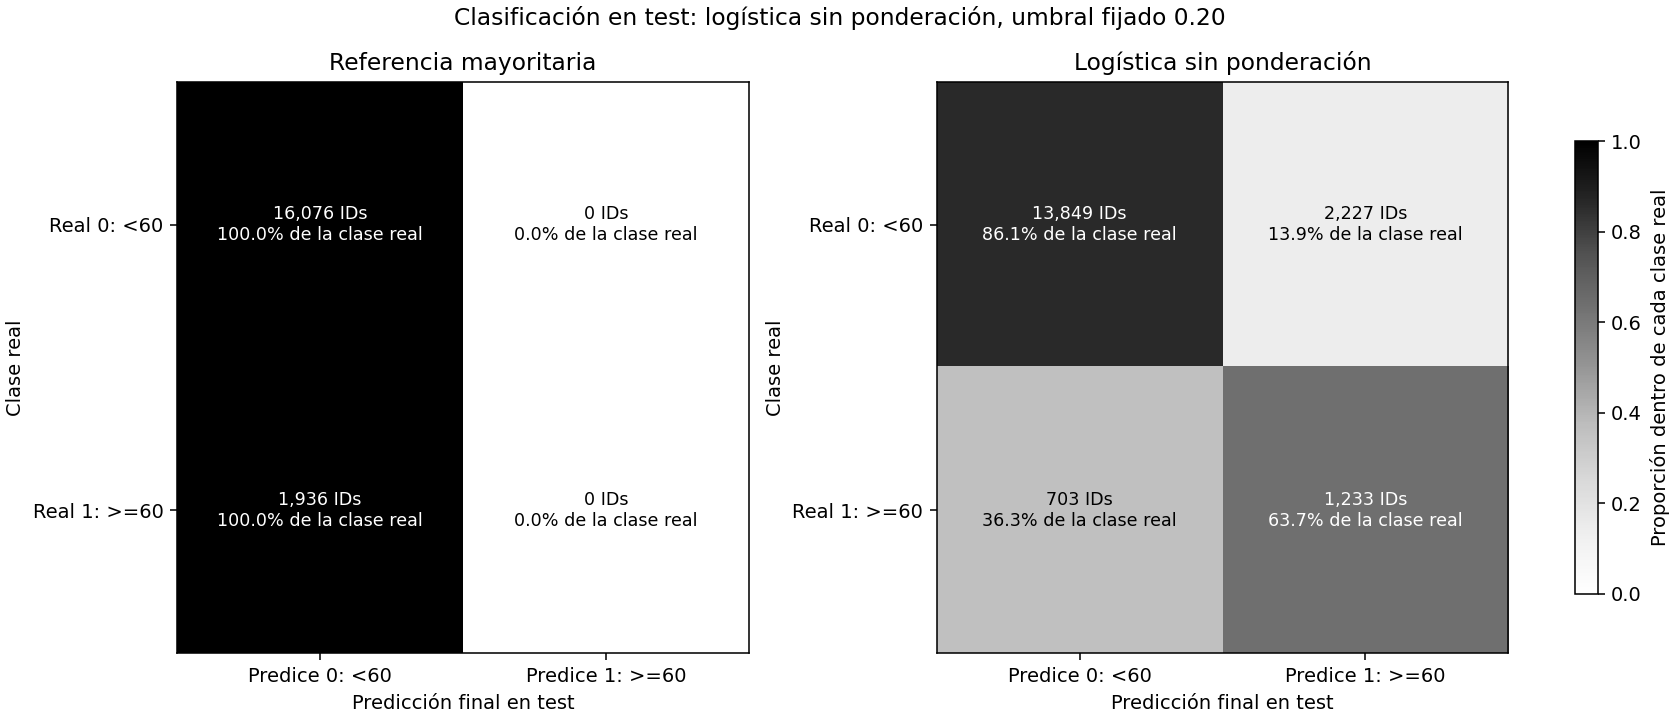

In [48]:
# Construir etiquetas de test únicamente para esta evaluación final ya fijada
if not (y_test.notna().all() and np.isfinite(y_test).all() and y_test.between(0, 100).all()):
    raise ValueError("Revisar popularidad de test antes de construir las etiquetas de evaluación.")
y_clasificacion_test = y_test.ge(corte_popularidad_clasificacion).astype("int8").rename("clase_popularidad_60_test")
assert y_clasificacion_test.index.equals(predicciones_logistica_test.index)
distribucion_clasificacion_test = y_clasificacion_test.value_counts().reindex([0, 1], fill_value=0).to_frame("IDs")
distribucion_clasificacion_test["Porcentaje de test"] = distribucion_clasificacion_test["IDs"] / len(y_clasificacion_test) * 100
registros_clasificacion_test = []
matrices_clasificacion_test = {}
for nombre, pred in {"Referencia mayoritaria": predicciones_mayoria_clasificacion_test, "Logística sin ponderación": predicciones_logistica_test}.items():
    assert pred.index.equals(y_clasificacion_test.index)
    matriz, resumen = resumir_clasificacion(y_clasificacion_test, pred)
    registros_clasificacion_test.append({"Procedimiento": nombre, **resumen})
    matrices_clasificacion_test[nombre] = matriz
    display(pd.DataFrame(matriz, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(f"Test: {nombre}"))
tabla_metricas_clasificacion_test = pd.DataFrame(registros_clasificacion_test).set_index("Procedimiento")
lectura_metricas_clasificacion_test = tabla_metricas_clasificacion_test[["IDs", "TN", "FP", "FN", "TP", "Positivos predichos", "Precisión positiva definida", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]].copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    lectura_metricas_clasificacion_test[metrica] *= 100
lectura_metricas_clasificacion_test = lectura_metricas_clasificacion_test.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
resultado_logistica_test = tabla_metricas_clasificacion_test.loc["Logística sin ponderación"]
comparacion_clasificacion_desarrollo_test = pd.DataFrame([
    {"Evaluación": "Validación anidada de entrenamiento", "IDs": int(fila_elegida_clasificacion["IDs"]), "Precisión (%)": float(fila_elegida_clasificacion["Precisión clase 1"]) * 100, "Recall (%)": float(fila_elegida_clasificacion["Recall clase 1"]) * 100, "F1": float(fila_elegida_clasificacion["F1 clase 1"]), "Accuracy (%)": float(fila_elegida_clasificacion["Accuracy"]) * 100},
    {"Evaluación": "Test del procedimiento final", "IDs": len(y_clasificacion_test), "Precisión (%)": resultado_logistica_test["Precisión clase 1"] * 100, "Recall (%)": resultado_logistica_test["Recall clase 1"] * 100, "F1": resultado_logistica_test["F1 clase 1"], "Accuracy (%)": resultado_logistica_test["Accuracy"] * 100}
]).set_index("Evaluación")
ejemplos_clasificacion_test = pd.DataFrame({"Clase real": y_clasificacion_test, "Referencia": predicciones_mayoria_clasificacion_test, "Probabilidad estimada clase 1": probabilidades_logistica_test, "Predicción logística": predicciones_logistica_test})
display(distribucion_clasificacion_test.round(4))
display(lectura_metricas_clasificacion_test.round(4))
display(comparacion_clasificacion_desarrollo_test.round(4))
display(ejemplos_clasificacion_test.head(5).round(4))

# Visualizar conteos y proporciones dentro de cada clase real
import matplotlib.pyplot as plt
fig_clasificacion_test, ejes_clasificacion_test = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for eje, (nombre, matriz) in zip(ejes_clasificacion_test, matrices_clasificacion_test.items()):
    proporciones = matriz / matriz.sum(axis=1, keepdims=True)
    imagen_test = eje.imshow(proporciones, vmin=0, vmax=1, cmap="Greys")
    for fila in range(2):
        for columna in range(2):
            texto = f"{matriz[fila, columna]:,} IDs\n{proporciones[fila, columna] * 100:.1f}% de la clase real"
            eje.text(columna, fila, texto, ha="center", va="center", fontsize=9, color="white" if proporciones[fila, columna] > 0.5 else "black")
    eje.set_xticks([0, 1], ["Predice 0: <60", "Predice 1: >=60"])
    eje.set_yticks([0, 1], ["Real 0: <60", "Real 1: >=60"])
    eje.set_xlabel("Predicción final en test")
    eje.set_ylabel("Clase real")
    eje.set_title(nombre)
fig_clasificacion_test.colorbar(imagen_test, ax=ejes_clasificacion_test, shrink=0.7, label="Proporción dentro de cada clase real")
fig_clasificacion_test.suptitle(f"Clasificación en test: logística sin ponderación, umbral fijado {umbral_final_clasificacion:.2f}")
display(fig_clasificacion_test)
plt.close(fig_clasificacion_test)


### Cierre de KPI de clasificación y estado final

Las metas predictivas siguen siendo **recall >=60% y precisión >=30%**. Se comprueban ahora sobre el test del procedimiento fijado, sin sustituirlas por metas más fáciles si alguna falla.

**Código, en orden:**

- La tabla final copia los KPI de desarrollo para conservar evidencia y añade alcance. Recall y precisión se actualizan con los resultados de test y estado «Cumple» o «No cumple».
- Los indicadores de etiquetas de entrenamiento, claves de ajuste/validación y cobertura OOF conservan su resultado y alcance de **desarrollo en entrenamiento**; no se presentan como si fueran nuevas mediciones de test.
- Se añaden controles finales separados: IDs y claves no compartidos, cobertura de predicciones en test, etiquetas de test alineadas y parámetros fijados. La cobertura OOF anterior no se confunde con esta cobertura final.
- El cumplimiento se decide con precisión completa; el redondeo solo facilita lectura. Que los controles metodológicos sean correctos no compensa incumplir una meta predictiva.
- El estado final registra que la prueba de clasificación ya fue evaluada. No se ajusta el umbral ni se reemplaza por balanced en función del resultado.

**Recall cumple:** 63,69% >=60%; se identifican 1.233 de las 1.936 positivas reales.

**Precisión cumple:** 35,64% >=30%. De 3.460 canciones señaladas, 1.233 cumplen realmente y 2.227 son falsas alarmas.

El resultado de referencia se conserva como contraste: si predice siempre clase 0 puede tener accuracy alta, pero no identifica positivas y no cumple las metas de identificación. La logística debe justificarse con su matriz y ambas métricas, no solo con el porcentaje global de aciertos.


In [49]:
# Conservar controles de desarrollo y actualizar los KPI predictivos con test
tabla_kpi_clasificacion_test = tabla_kpi_eleccion_clasificacion.copy(deep=True)
tabla_kpi_clasificacion_test["Alcance"] = "Desarrollo: etiquetas y validación agrupada de entrenamiento"
for indicador, valor, cumple in [
    ("Recall clase 1", resultado_logistica_test["Recall clase 1"] * 100, resultado_logistica_test["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", resultado_logistica_test["Precisión clase 1"] * 100, resultado_logistica_test["Precisión positiva definida"] and resultado_logistica_test["Precisión clase 1"] >= meta_precision_clasificacion)
]:
    tabla_kpi_clasificacion_test.loc[indicador, "Resultado"] = valor
    tabla_kpi_clasificacion_test.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"
    tabla_kpi_clasificacion_test.loc[indicador, "Alcance"] = "Evaluación final de clasificación en test"
controles_clasificacion_final_test = pd.Series({
    "Cero IDs compartidos entrenamiento/test": X_train.index.intersection(X_test.index).empty,
    "Cero claves compartidas entrenamiento/test": set(datos_entrenamiento["clave_cancion"]).isdisjoint(set(datos_prueba["clave_cancion"])),
    "Cobertura de predicciones de test del 100%": predicciones_logistica_test.index.equals(X_test.index) and predicciones_logistica_test.notna().all(),
    "Etiquetas reales de test válidas y alineadas": y_clasificacion_test.isin([0, 1]).all() and y_clasificacion_test.index.equals(predicciones_logistica_test.index),
    "Parámetros del estimador sin cambios": modelo_logistico_final.named_steps["clasificar"].get_params() == parametros_finales_logistica,
    "Umbral fijado solo con entrenamiento": umbral_final_clasificacion == decision_final_clasificacion["Umbral de probabilidad fijado"]
})
if not controles_clasificacion_final_test.all():
    raise ValueError("Revisar controles finales antes de cerrar la evaluación de clasificación.")
cumple_kpi_predictivos_clasificacion_test = bool(resultado_logistica_test["Precisión positiva definida"] and resultado_logistica_test["Precisión clase 1"] >= meta_precision_clasificacion and resultado_logistica_test["Recall clase 1"] >= meta_recall_clasificacion)
estado_final_clasificacion = pd.Series({"Procedimiento": "Logística sin ponderación y sin artista", "Umbral fijado": umbral_final_clasificacion, "Ajuste único con todo entrenamiento": "Realizado", "Evaluación de clasificación en test": "Realizada", "Ambas metas predictivas en test": "Cumple" if cumple_kpi_predictivos_clasificacion_test else "No cumple", "Uso posterior de test": "Ya observado; no usar para cambiar el procedimiento y afirmar una confirmación independiente"})
display(tabla_kpi_clasificacion_test.round({"Resultado": 4}))
display(controles_clasificacion_final_test)
display(estado_final_clasificacion)


,Meta,Resultado,Unidad,Estado,Alcance
KPI,,,,,
Recall clase 1,>= 60%,63.6880,%,Cumple,Evaluación final de clasificación en test
Precisión clase 1,>= 30%,35.6358,%,Cumple,Evaluación final de clasificación en test
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple,Desarrollo: etiquetas y validación agrupada de...
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple,Desarrollo: etiquetas y validación agrupada de...
Cobertura de predicciones OOF,100%,100.0000,%,Cumple,Desarrollo: etiquetas y validación agrupada de...


Cero IDs compartidos entrenamiento/test         True
Cero claves compartidas entrenamiento/test      True
Cobertura de predicciones de test del 100%      True
Etiquetas reales de test válidas y alineadas    True
Parámetros del estimador sin cambios            True
Umbral fijado solo con entrenamiento            True
dtype: bool

Procedimiento                                    Logística sin ponderación y sin artista
Umbral fijado                                                                        0.2
Ajuste único con todo entrenamiento                                            Realizado
Evaluación de clasificación en test                                            Realizada
Ambas metas predictivas en test                                                   Cumple
Uso posterior de test                  Ya observado; no usar para cambiar el procedim...
dtype: object

### Conclusión de la evaluación final de clasificación

Se ajustó una única logística **sin ponderación y sin artista** con los 71.728 IDs de entrenamiento y se evaluó sobre los **18.012 IDs de test**, con umbral **0,20** elegido solo con entrenamiento. No se consultaron métricas de test para escogerlo o corregirlo.

| Procedimiento en test | Precisión clase 1 | Recall clase 1 | F1 clase 1 | Accuracy |
|---|---:|---:|---:|---:|
| Referencia mayoritaria | No definida; reporte 0 | 0,00% | 0,0000 | 89,25% |
| Logística sin ponderación | 35,64% | 63,69% | 0,4570 | 83,73% |

La logística identifica **1.233** positivas reales, omite **703** y produce **2.227** falsas alarmas; reconoce correctamente **13.849** negativas. En total señala **3.460** canciones, de las que **1.233** cumplen el corte.

**Cumple ambas metas predictivas iniciales en este test interno.** Este cumplimiento no equivale a ausencia de errores ni garantiza desempeño futuro.

**Por qué no se elige por accuracy:** la referencia alcanza 89,25% de accuracy frente a 83,73% de la logística, pero no detecta ninguna de las 1.936 positivas: recall=0 y F1=0. La logística sí cumple las dos metas que responden al objetivo de identificación. Aun así, 2.227 de sus 3.460 canciones señaladas son falsas alarmas: el cumplimiento de la meta académica de precisión no elimina esa carga de revisión.

**Comparación con desarrollo:** en la validación anidada, precisión=34,68%, recall=61,11% y F1=0,4425. El test corresponde a otras canciones y a un modelo ajustado con más datos. La coincidencia o diferencia de métricas no demuestra ausencia de sobreajuste o fuga ni garantiza comportamiento futuro. La fuente ya fue explorada y test se había observado para regresión.

Los controles de separación y cobertura final se verificaron. No se eliminaron canciones difíciles, no se ajustó el umbral después de observar test y no se sustituyó el modelo por balanced. La referencia ilustra por qué accuracy sola no responde al objetivo de identificar positivas.

**Estado de esta tarea:** evaluación final interna de clasificación realizada, con cumplimiento e incumplimientos documentados según corresponda. No termina automáticamente los contenidos pendientes de unidad 2. Cualquier cambio posterior guiado por estos resultados requerirá nueva evidencia independiente para confirmarse; este test ya está observado para ambas tareas supervisadas.
